# Complete Garmin + EMA pipeline

In [1]:
from pathlib import Path
import sys, json, importlib, hashlib
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root / 'src'))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from IPython.core.magic import register_cell_magic
from garmin_pipeline_review.sources import source_path
from garmin_pipeline_review.workflow import execute_review
from garmin_pipeline_review.audit import load

@register_cell_magic
def canonical_source(line, cell):
    path = source_path(root, line.strip())
    assert cell == path.read_text()
    compile(cell, str(path), 'exec')
    module = importlib.import_module(line.strip())
    assert Path(module.__file__).resolve() == path.resolve()
    return None

# Import exact source; do not rerun expensive extraction/search entrypoints.
public = root / 'reports/complete_pipeline_review'
def table(name):
    return pd.read_csv(public / (name + '.csv'))
def figure(name):
    display(Image(filename=str(public / 'figures' / (name + '.png'))))
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)


## Checkpoints and scope

In [2]:
display(pd.DataFrame([
    [13, '678 candidates; 438 supported + 240 provisional', 'recorded-time features; full logistic'],
    [14, '438 supported; PulseOx separate', 'continuous regression'],
    [15, '438 multiscale; 47 single-window', 'binary logistic'],
    [16, 'bounded subsets of the complete matrix', 'sampling and model diagnostics'],
    [17, 'past-only wearable references; EMA history gated', 'answer availability unverified'],
    [18, 'matched measurement/item diagnostics', 'no replacement of the complete matrix'],
    [19, 'reviewed-metadata importer and recall alignment', 'real aligned/history prediction blocked'],
], columns=['notebook', 'inputs', 'status']))
# Supported means computable observed summaries, not verified acquisition or physiology.
# No final-test data; no new feature definitions or model search.


,notebook,inputs,status
0,13,678 candidates; 438 supported + 240 provisional,recorded-time features; full logistic
1,14,438 supported; PulseOx separate,continuous regression
2,15,438 multiscale; 47 single-window,binary logistic
3,16,bounded subsets of the complete matrix,sampling and model diagnostics
4,17,past-only wearable references; EMA history gated,answer availability unverified
5,18,matched measurement/item diagnostics,no replacement of the complete matrix
6,19,reviewed-metadata importer and recall alignment,real aligned/history prediction blocked


## Frozen configurations

In [3]:
for name in ['comprehensive_features','comprehensive_regression','binary_6hour','binary_improvement','temporal_personalization','root_cause_analysis','measurement_alignment']:
    print(name)
    print(json.dumps(json.loads((root / 'config' / (name + '.json')).read_text()), indent=2))


comprehensive_features
{
  "version": "13-v1",
  "seed": 20261017,
  "normalized_bundle": "private/preprocessing/normalized/31e51c934bcdeffa",
  "feature_bundle": "private/hr_activity/features/76f5885b3955d5b0",
  "baseline_bundle": "private/ema_baseline/runs/640600af77404ff6",
  "history_bundle": "private/past_hr_reference/runs/510f1ad96a9e46f3",
  "eligibility_bundle": "private/preprocessing/eligibility/974e98729579967b",
  "lookbacks_minutes": [
    5,
    15,
    30,
    60,
    120,
    360,
    720,
    1440
  ],
  "summary_min_count": 2,
  "summary_min_span_seconds": 1,
  "slope_min_count": 3,
  "slope_min_span_seconds": 60,
  "shape_min_count": 8,
  "shape_min_span_seconds": 60,
  "adjacent_max_gap_seconds": 60,
  "adjacent_min_pairs": 2,
  "rolling_minutes": 5,
  "rolling_min_occupied_minutes": 3,
  "pulseox_provisional_range": [
    70,
    100
  ],
  "inner_splits": 3,
  "C_grid": [
    0.01,
    0.1,
    1,
    10
  ],
  "selection_C_grid": [
    0.01,
    0.1,
    1
  ],
 

## Raw sources and participant linkage

### src/garmin_inventory/sources.py

In [4]:
%%canonical_source garmin_inventory.sources
"""Read-only ZIP discovery. No extraction, basename linkage, or pickle loading."""
import hashlib
import io
import zipfile
from collections import Counter
from contextlib import contextmanager
from dataclasses import dataclass
from pathlib import Path, PurePosixPath

from .privacy import AuditError

MAX_MEMBER_BYTES = 1_500_000_000
MAX_CONTAINER_BYTES = 12_000_000_000


def safe_members(z):
    members = []
    total = 0
    for m in z.infolist():
        p = PurePosixPath(m.filename)
        if p.is_absolute() or '..' in p.parts or '\\' in m.filename:
            raise AuditError('Unsafe archive member path; names withheld.')
        if m.is_dir() or '__MACOSX' in p.parts or p.name == '.DS_Store':
            continue
        if m.flag_bits & 1 or ((m.external_attr >> 16) & 0o170000) == 0o120000:
            raise AuditError('Encrypted or symlink archive member is unsupported.')
        total += m.file_size
        if m.file_size > MAX_MEMBER_BYTES or total > MAX_CONTAINER_BYTES:
            raise AuditError('Archive exceeds inspection size budget.')
        members.append(m)
    return members


@dataclass(frozen=True)
class Source:
    archive: Path
    member: str
    nested: str | None = None

    @contextmanager
    def open(self):
        with zipfile.ZipFile(self.archive) as outer:
            if self.nested is None:
                with outer.open(self.member) as f:
                    yield f
            else:
                with zipfile.ZipFile(io.BytesIO(outer.read(self.nested))) as inner:
                    with inner.open(self.member) as f:
                        yield f

    def content_hash(self):
        h = hashlib.sha256()
        with self.open() as f:
            for chunk in iter(lambda: f.read(4 * 1024 * 1024), b''):
                h.update(chunk)
        return h.hexdigest()

    def exact_tokens(self):
        return set(Path(self.member).stem.split('.')) | set(Path(self.nested or '').stem.split('.'))


def discover(data):
    ema, garmin, pdf = [], [], []
    inventory, names = [], set()
    for p in sorted(data.rglob('*.zip')):
        names.add(p.name)
        with zipfile.ZipFile(p) as z:
            members = safe_members(z)
            inventory.append({'archive': f'archive_{len(inventory) + 1:02}',
                              'bytes': p.stat().st_size, 'members': len(members),
                              'uncompressed_bytes': sum(m.file_size for m in members),
                              'extensions': dict(Counter(Path(m.filename).suffix for m in members))})
            for m in members:
                names.add(Path(m.filename).name)
                suffix = Path(m.filename).suffix.lower()
                if suffix == '.zip':
                    with zipfile.ZipFile(io.BytesIO(z.read(m))) as inner:
                        for n in safe_members(inner):
                            names.add(Path(n.filename).name)
                            if n.filename.lower().endswith('.csv'):
                                garmin.append(Source(p, n.filename, m.filename))
                elif suffix == '.csv':
                    import pandas as pd
                    with z.open(m) as f:
                        columns = set(pd.read_csv(f, nrows=0).columns)
                    if {'actual_start_local', 'scheduled_start_local', 'mbl_cod'} <= columns:
                        ema.append(Source(p, m.filename))
                    elif {'ts', 'dte_tme', 'data_type', 'val'} <= columns:
                        garmin.append(Source(p, m.filename))
                    else:
                        raise AuditError('Unrecognized local CSV schema; no legacy substitution.')
                elif suffix == '.pdf':
                    pdf.append(Source(p, m.filename))
    if not ema or not garmin:
        raise AuditError('Corrected EMA and Garmin archives are required.')
    return ema, garmin, pdf, inventory, names


### src/garmin_inventory/audit.py

In [5]:
%%canonical_source garmin_inventory.audit
"""Recompute inspection from raw archives. Only aggregate findings leave memory.

All-cohort access: schemas, identity, source accounting, split verification only.
Development-only access: clocks, values, item validity, gaps and history diagnostics.
"""
import argparse
import hashlib
import io
import json
import os
import re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
from pypdf import PdfReader

from .privacy import AuditError, git_guard, scan_public, sha256, tree_snapshot
from .sources import discover

SENSORS = ('hr', 'ibi', 'stress', 'pulseOx', 'steps', 'calories',
           'floorsClimbed', 'intensityMinutes')
LOOKBACKS = (5, 15, 30, 60, 120, 360, 720, 1440)
KEYS = ('mbl_cod', 'rsp_id')
PSS = ('PSS_NERVOUS', 'PSS_COPE', 'PSS_CONTROL')
MISSING = {'', 'NA', 'N/A', 'NaN', 'nan', 'NULL', 'null', '-999', '-99'}


def clean(s):
    return s.astype(str).str.strip().replace({x: None for x in MISSING})


def parse_local(s):
    return pd.to_datetime(s, format='mixed', errors='coerce')


def epoch(s):
    return s.astype('int64').to_numpy(dtype=float) / 1e9


def cutoff(actual, precision):
    if precision not in ('minute', 'second'):
        raise AuditError('Unknown EMA clock precision; no default cutoff allowed.')
    return actual - (60 if precision == 'minute' else 0)


def continuity(times, threshold):
    t = np.unique(np.asarray(times, float))
    if not len(t):
        return np.array([], dtype=float)
    breaks = np.flatnonzero(np.diff(t) > threshold)
    starts = np.r_[0, breaks + 1]
    ends = np.r_[breaks, len(t) - 1]
    return t[ends] - t[starts]


def history(times, boundary, minutes, gap_limit, *, sorted_unique=False):
    """Diagnostic-only; interval [boundary-lookback,boundary), no feature export."""
    times = np.asarray(times, float) if sorted_unique else np.unique(np.asarray(times, float))
    left, right = np.searchsorted(times, [boundary - minutes * 60, boundary], side='left')
    t = times[left:right]
    if not len(t):
        return False, False
    edge = np.r_[t[0] - (boundary - minutes * 60), np.diff(t), boundary - t[-1]]
    return True, bool(edge.max() <= gap_limit)


def validate_split(assignments, people):
    required = {'participant', 'partition', 'fold'}
    if not required <= set(assignments):
        raise AuditError('Frozen split schema is incomplete.')
    if assignments.participant.duplicated().any() or set(assignments.participant) != people:
        raise AuditError('Frozen split does not cover the current cohort exactly once.')
    if assignments.groupby('partition').size().to_dict() != {'development': 125, 'final_test': 32}:
        raise AuditError('Frozen split differs from the agreed participant counts.')
    d = assignments.loc[assignments.partition == 'development']
    if d.groupby('fold').size().to_dict() != {i: 25 for i in range(5)}:
        raise AuditError('Frozen development folds differ from the verified reference.')
    if not assignments.loc[assignments.partition == 'final_test', 'fold'].eq(-1).all():
        raise AuditError('Final-test fold metadata is unexpected.')
    return set(d.participant)


def resolve_pair(mbl, rsp, lookup, ambiguous, fallback=None):
    # A participant key wins only if it does not conflict with a usable respondent key.
    candidate = lookup.get(rsp) if rsp not in ambiguous else None
    if mbl and candidate and mbl != candidate:
        return None, 'conflicting'
    if mbl:
        return mbl, 'content_mbl_cod'
    if candidate:
        return candidate, 'content_rsp_id'
    if fallback:
        return fallback, 'reference_corroborated_filename'
    return None, 'unresolved'


def describe_field(name):
    if name in KEYS:
        return 'identity', 'opaque string; never numeric', 'none; exact keys only'
    if name in ('actual_start_local', 'scheduled_start_local', 'dte_tme'):
        return 'clock', 'naive local datetime text', 'local clock; offset required'
    if name == 'ts':
        return ('clock', 'numeric epoch stored as text',
                'Unix seconds; acquisition-versus-receipt semantics unconfirmed')
    if name == 'instance_id':
        return 'clock', 'numeric epoch stored as text', 'Unix seconds; instance is scheduled'
    if name == 'timezone_offset':
        return 'clock', 'integer stored as text', 'minutes local minus UTC'
    if name in PSS:
        return 'outcome item', 'integer code', '1–5 codes; displayed 0–4 labels'
    if name == 'data_type':
        return 'sensor category', 'categorical text', 'see sensor dictionary'
    if name == 'val':
        return 'sensor value', 'numeric stored as text', 'depends on data_type'
    if any(x in name.upper() for x in ['TEXT', 'THREAT_MESSAGE']):
        return 'sensitive survey text', 'text/coded content; values withheld', 'not a predictor'
    if name in ('LATITUDE', 'LONGITUDE', 'Location Timestamp', 'Location near window', 'Proximity to window'):
        return 'sensitive location', 'source text', 'not a predictor; exporter semantics unverified'
    if name in ('STRESS', 'PULSE_OX', 'HEART_RATE', 'RESPIRATION', 'BODY_BATTERY', 'STEPS',
                'CALORIES', 'FLOORS', 'INTENSITY_MINUTES', 'AVG_AMP', 'VOX_ACTV'):
        return 'embedded EMA device/context field', 'source text', 'timing/units unverified; exclude initial predictors'
    return 'survey response', 'source text / numeric codes', 'questionnaire-specific; not an initial predictor'


def field_profile(frame, category):
    result = []
    for name in frame:
        s = frame[name].astype(str).str.strip()
        kind, dtype, units = describe_field(name)
        missing = s.eq('') if kind == 'sensitive survey text' else s.isin(MISSING)
        num = pd.to_numeric(s.where(~missing), errors='coerce')
        numeric = num.dropna()
        observed = ('empty' if missing.all() else 'numeric' if num.notna().sum() == (~missing).sum()
                    else 'text/mixed')
        result.append(dict(table=category, field=name, semantic_category=kind,
                           storage_type='CSV text', interpretation=dtype, units=units,
                           observed_development_type=observed, development_cells=len(s),
                           development_missing_cells=int(missing.sum()),
                           development_blank_cells=int(s.eq('').sum()),
                           development_numeric_cells=int(num.notna().sum()),
                           development_integer_cells=int((numeric % 1 == 0).sum())))
    return result


def load_ema(sources):
    tables, inventory, raw_tables = [], [], []
    for source in sources:
        with source.open() as f:
            raw = pd.read_csv(f, dtype=str, keep_default_na=False)
        category = 'Morning' if 'SLEEP_SLEEPTIME' in raw else 'Endday' if 'ENDDAY_TEXT' in raw else 'Midday'
        raw_tables.append((category, raw))
        inventory.append(dict(category=category, rows=len(raw), participants=clean(raw.mbl_cod).nunique(),
                              fields=len(raw.columns)))
        t = raw[list(KEYS) + ['instance_id', 'scheduled_start_local', 'timezone_offset',
                             'actual_start_local']].copy()
        t['category'] = category
        for key in KEYS:
            t[key] = clean(t[key])
        tables.append(t)
    return pd.concat(tables, ignore_index=True), raw_tables, inventory


def ema_audit(ema, raw_tables, dev):
    t = ema.loc[ema.mbl_cod.isin(dev)].copy()
    t['precision'] = np.where(t.actual_start_local.str.contains(r'\d+:\d+:\d+'), 'second', 'minute')
    actual, scheduled = parse_local(t.actual_start_local), parse_local(t.scheduled_start_local)
    offset = pd.to_numeric(t.timezone_offset, errors='coerce')
    actual_utc, scheduled_utc = actual - pd.to_timedelta(offset, unit='min'), scheduled - pd.to_timedelta(offset, unit='min')
    t['actual_epoch'] = epoch(actual_utc)
    invalid = actual_utc.isna() | offset.isna()
    t.loc[invalid, 'actual_epoch'] = np.nan
    t['cutoff'] = [cutoff(a, p) for a, p in zip(t.actual_epoch, t.precision)]
    residual = epoch(scheduled_utc) - pd.to_numeric(t.instance_id, errors='coerce')
    delay = (actual - scheduled).dt.total_seconds()
    clocks = dict(scope='development only', rows=len(t), actual_unparsed=int(actual.isna().sum()),
                  scheduled_unparsed=int(scheduled.isna().sum()), offset_missing=int(offset.isna().sum()),
                  offsets_minutes=sorted(offset.dropna().unique().tolist()),
                  scheduled_epoch_agreement_rows=int((abs(residual) < .001).sum()),
                  actual_before_scheduled=int((delay < 0).sum()), delays_above_30min=int((delay > 1800).sum()),
                  delays_above_2h=int((delay > 7200).sum()), delay_median_seconds=float(delay.median()),
                  precision_counts=t.precision.value_counts().to_dict(),
                  start_date_utc=str(actual_utc.min().date()), end_date_utc=str(actual_utc.max().date()),
                  submission_or_end_columns=[c for c in ema if re.search(r'submit|completion_time|end_time', c, re.I)])
    dictionary, item_validity = [], []
    for category, raw in raw_tables:
        d = raw.loc[clean(raw.mbl_cod).isin(dev)]
        dictionary += field_profile(d, category)
        items = d[list(PSS)].apply(pd.to_numeric, errors='coerce')
        valid = items.notna() & items.ge(1) & items.le(5) & items.mod(1).eq(0)
        item_validity.append(dict(category=category, development_rows=len(d),
                                  complete_valid_items=int(valid.all(axis=1).sum()),
                                  rows_missing_any_item=int(items.isna().any(axis=1).sum()),
                                  nonmissing_invalid_cells=int((items.notna() & ~valid).sum().sum()),
                                  blank_item_cells=int(d[list(PSS)].eq('').sum().sum())))
    return t, clocks, dictionary, item_validity


def questionnaire_audit(sources):
    matched = 0
    for source in sources:
        with source.open() as f:
            text = '\n'.join(p.extract_text() or '' for p in PdfReader(io.BytesIO(f.read())).pages)
        if all(field in text for field in PSS):
            if '0 = Not at all' in text and '4 = Extremely' in text:
                matched += 1
    return dict(pdf_documents=len(sources), documents_with_three_pss_items_and_0_to_4_labels=matched,
                csv_codes='1–5', display_labels='0–4',
                proposed_formula='PSS_NERVOUS + (6 - PSS_COPE) + (6 - PSS_CONTROL)',
                range='3–15', score_calculated=False,
                note='Three adapted items; do not equate with a standard full PSS instrument. Complete integer-coded items required.')


def corroborate_fallback(reference, participant, content_hash):
    folder = reference / 'data_interim/v2/garmin_normalized' / ('person_' + hashlib.sha256(participant.encode()).hexdigest()[:24])
    for p in folder.rglob('*.parquet'):
        f = pd.read_parquet(p, columns=['participant', 'source_content_sha256'])
        matched = f.loc[f.source_content_sha256 == content_hash, 'participant']
        if len(matched) and set(matched) == {participant}:
            return True
    return False


def source_identity_scan(sources, ema, reference):
    pairs = set(map(tuple, ema[['rsp_id', 'mbl_cod']].dropna().to_numpy()))
    sources_meta, all_schemas, private_keys = [], Counter(), set(ema.mbl_cod.dropna()) | set(ema.rsp_id.dropna())
    for index, source in enumerate(sources):
        key_counts = Counter()
        rows = 0
        with source.open() as f:
            reader = pd.read_csv(f, dtype=str, keep_default_na=False, chunksize=250_000,
                                 usecols=lambda c: c in KEYS)
            for chunk in reader:
                # pandas cannot retain row count for a zero-column usecols result.
                if not len(chunk.columns):
                    break
                rows += len(chunk)
                for key in KEYS:
                    if key not in chunk:
                        chunk[key] = ''
                    chunk[key] = clean(chunk[key]).fillna('')
                counts = chunk.groupby(list(KEYS), dropna=False).size()
                key_counts.update({tuple(k): int(v) for k, v in counts.items()})
        with source.open() as f:
            columns = tuple(pd.read_csv(f, nrows=0).columns)
        if not {'ts', 'dte_tme', 'data_type', 'val'} <= set(columns):
            raise AuditError('Unsupported Garmin schema.')
        if not set(KEYS) & set(columns):
            with source.open() as f:
                rows = sum(len(c) for c in pd.read_csv(f, usecols=['ts'], chunksize=250_000))
            key_counts[('', '')] = rows
        all_schemas[columns] += 1
        for (m, r), n in key_counts.items():
            private_keys.update(x for x in [m, r] if x)
            if m and r:
                pairs.add((r, m))
        sources_meta.append(dict(source=source, rows=rows, key_counts=key_counts,
                                 content_hash=source.content_hash(), columns=columns))
        if (index + 1) % 20 == 0:
            print(f'Identity/content audit: {index + 1}/{len(sources)} sources', flush=True)
    candidates = defaultdict(set)
    for r, p in pairs:
        candidates[r].add(p)
    ambiguous = {r for r, ps in candidates.items() if len(ps) > 1}
    lookup = {r: next(iter(ps)) for r, ps in candidates.items() if len(ps) == 1}
    verified = reference / 'data_interim/v2/participant_crosswalk.parquet'
    reference_pairs = set()
    if verified.exists():
        c = pd.read_parquet(verified)
        reference_pairs = set(map(tuple, c[['respondent', 'participant']].to_numpy()))
    seen, methods, people, unknown, missing = set(), Counter(), set(), set(), Counter()
    for meta in sources_meta:
        source = meta['source']
        tokens = source.exact_tokens() & set(ema.mbl_cod.dropna())
        fallback = next(iter(tokens)) if len(tokens) == 1 else None
        has_unmapped = any(not m and (r not in lookup) for m, r in meta['key_counts'])
        if has_unmapped and fallback:
            if not corroborate_fallback(reference, fallback, meta['content_hash']):
                fallback = None
        source_people, unresolved = set(), 0
        for (m, r), n in meta['key_counts'].items():
            participant, method = resolve_pair(m, r, lookup, ambiguous, fallback)
            methods[method] += n
            missing['rows_missing_mbl_cod'] += n if not m else 0
            missing['rows_missing_rsp_id'] += n if not r else 0
            if participant:
                source_people.add(participant)
                if participant not in set(ema.mbl_cod):
                    unknown.add(participant)
            else:
                unresolved += n
        meta.update(participants=source_people, unresolved_rows=unresolved,
                    duplicate_export=meta['content_hash'] in seen, fallback=fallback)
        seen.add(meta['content_hash'])
        people.update(source_people)
    return sources_meta, dict(schemas=[dict(fields=list(k), files=v) for k, v in all_schemas.items()],
                             physical_rows=sum(m['rows'] for m in sources_meta),
                             logical_rows=sum(m['rows'] for m in sources_meta if not m['duplicate_export']),
                             duplicate_export_files=sum(m['duplicate_export'] for m in sources_meta),
                             distinct_mapped_participants=len(people), participants_absent_from_ema=len(unknown),
                             ema_participants_without_garmin=len(set(ema.mbl_cod) - people),
                             ambiguous_respondent_keys=len(ambiguous), mapping_methods_rows=dict(methods),
                             missing_key_rows=dict(missing),
                             current_crosswalk_pairs=len(pairs), reference_crosswalk_pairs=len(reference_pairs),
                             pairs_only_current=len(pairs - reference_pairs), pairs_only_reference=len(reference_pairs - pairs),
                             files_with_multiple_participants=sum(len(m['participants']) > 1 for m in sources_meta)), private_keys


def hist_quantile(hist, q):
    if not hist:
        return None
    ordered = sorted(hist.items())
    target = q * (sum(hist.values()) - 1)
    cumulative = 0
    for value, count in ordered:
        cumulative += count
        if cumulative > target:
            return float(value)
    return float(ordered[-1][0])


def add_hist(hist, values, decimals=3):
    values, counts = np.unique(np.round(values, decimals), return_counts=True)
    hist.update(dict(zip(values.tolist(), counts.tolist())))


def sensor_audit(sources_meta, development, ema_dev):
    counts = {s: Counter() for s in SENSORS}
    intervals = {s: Counter() for s in SENSORS}
    runs = {s: Counter() for s in SENSORS}
    people = {s: set() for s in SENSORS}
    limits = {'hr': (30, 240), 'ibi': (250, 2000), 'stress': (0, 100), 'pulseOx': (70, 100)}
    offsets, clock_totals, date_bounds = Counter(), Counter(), []
    coverage = {(s, w): Counter() for s in SENSORS for w in LOOKBACKS}
    ibi_clock_agreement = Counter()
    audited_people = set()
    files_by_person = defaultdict(list)
    for meta in sources_meta:
        if meta['unresolved_rows'] or len(meta['participants']) != 1:
            raise AuditError('Unresolved or mixed source identities require a separate structural audit.')
        person = next(iter(meta['participants']))
        if person in development and not meta['duplicate_export']:
            files_by_person[person].append(meta)
    for index, (person, metas) in enumerate(files_by_person.items()):
        frames = []
        for meta in metas:
            with meta['source'].open() as f:
                frames.append(pd.read_csv(f, dtype=str, keep_default_na=False))
        raw = pd.concat(frames, ignore_index=True)
        if not set(raw.data_type) <= set(SENSORS):
            raise AuditError('Unknown sensor type; values withheld.')
        audited_people.add(person)
        ts = pd.to_numeric(raw.ts, errors='coerce')
        good_epoch = ts.between(946684800, 2082758400)  # Explicit 2000–2035 plausibility, not a study exclusion.
        local = pd.to_datetime(raw.dte_tme, format='mixed', errors='coerce')
        wall = epoch(local)
        offset = np.rint((wall - ts) / 60)
        residual = wall - ts - offset * 60
        valid_clock = good_epoch & local.notna()
        offsets.update({str(int(k)): int(v) for k, v in pd.Series(offset[valid_clock]).value_counts().items()})
        clock_totals.update(rows=len(raw), invalid_epoch=int((~good_epoch).sum()),
                            invalid_text_clock=int(local.isna().sum()),
                            residual_above_1_1_seconds=int((valid_clock & (abs(residual) > 1.1)).sum()),
                            offsets_outside_ema=int((valid_clock & ~pd.Series(offset).isin([-480, -420, -360, -300])).sum()),
                            fractional_epoch_rows=int((good_epoch & ts.mod(1).ne(0)).sum()),
                            fractional_text_rows=int(raw.dte_tme.str.contains(r'\d+:\d+:\d+\.\d+').sum()))
        if good_epoch.any():
            date_bounds.extend([ts[good_epoch].min(), ts[good_epoch].max()])
        raw['_ts'], raw['_val'], raw['_good_epoch'] = ts, pd.to_numeric(raw.val, errors='coerce'), good_epoch
        anchors = ema_dev.loc[ema_dev.mbl_cod == person, 'cutoff'].dropna().to_numpy()
        for sensor, f in raw.groupby('data_type', sort=False):
            c = counts[sensor]
            people[sensor].add(person)
            v = f._val.to_numpy()
            valid_values = np.isfinite(v)
            low, high = limits.get(sensor, (0, np.inf))
            c.update(rows=len(f), missing_or_nonnumeric_values=int((~valid_values).sum()),
                     blank_values=int(f.val.str.strip().eq('').sum()), zero_values=int((v == 0).sum()),
                     negative_values=int((v < 0).sum()), noninteger_values=int((valid_values & (v % 1 != 0)).sum()),
                     outside_provisional_range=int((valid_values & ((v < low) | (v > high))).sum()),
                     exact_record_duplicate_excess=int(f.drop(columns=['_ts', '_val', '_good_epoch']).duplicated().sum()))
            if valid_values.any():
                c['min'] = min(c.get('min', np.inf), float(v[valid_values].min()))
                c['max'] = max(c.get('max', -np.inf), float(v[valid_values].max()))
            ordered = f.loc[f._good_epoch].sort_values('_ts', kind='stable')
            t, vals = ordered._ts.to_numpy(), ordered._val.to_numpy()
            unique = np.unique(t)
            diffs = np.diff(unique)
            c['duplicate_timestamp_excess'] += len(t) - len(unique)
            c['identical_timestamp_value_excess'] += int(ordered.duplicated(['_ts', '_val']).sum())
            distinct_pairs = ordered.drop_duplicates(['_ts', '_val'])
            c['conflicting_timestamps'] += int((distinct_pairs.groupby('_ts').size() > 1).sum())
            original_order = f.loc[f._good_epoch, '_ts'].to_numpy()
            c['backward_steps_in_export_order'] += int((np.diff(original_order) < 0).sum())
            for gap in (2, 5, 60, 300, 1800, 3600, 7200):
                c[f'gaps_above_{gap}s'] += int((diffs > gap).sum())
            add_hist(intervals[sensor], diffs)
            threshold = 2 if sensor in ('hr', 'ibi') else 60
            run_lengths = continuity(unique, threshold)
            add_hist(runs[sensor], run_lengths)
            c['runs_at_least_5min'] += int((run_lengths >= 300).sum())
            c['run_gap_threshold_seconds'] = threshold
            if sensor == 'ibi' and len(t) > 1:
                dt, rr = np.diff(t), vals[1:] / 1000
                finite = np.isfinite(rr) & (dt > 0)
                ibi_clock_agreement.update(adjacent_positive_time_pairs=int(finite.sum()),
                    time_difference_within_100ms_of_current_ibi=int((finite & (abs(dt - rr) <= .1)).sum()),
                    adjacent_value_change_above_20pct=int((abs(np.diff(vals)) > .2 * vals[:-1]).sum()))
            if sensor in ('steps', 'calories', 'floorsClimbed', 'intensityMinutes') and len(t) > 1:
                day = ordered.dte_tme.str[:10].to_numpy()
                same_day, decrease = day[1:] == day[:-1], np.diff(vals) < 0
                c.update(within_day_pairs=int(same_day.sum()), within_day_decreases=int((same_day & decrease).sum()),
                         date_transition_pairs=int((~same_day).sum()), date_transition_decreases=int((~same_day & decrease).sum()))
            for w in LOOKBACKS:
                a = coverage[sensor, w]
                for boundary in anchors:
                    present, bounded = history(unique, boundary, w, 60, sorted_unique=True)
                    a['responses_with_any_observation'] += int(present)
                    a['responses_with_all_edge_and_internal_gaps_le_60s'] += int(bounded)
                    if sensor == 'ibi':
                        _, tight = history(unique, boundary, w, 2, sorted_unique=True)
                        a['responses_with_all_edge_and_internal_gaps_le_2s'] += int(tight)
        if (index + 1) % 10 == 0:
            print(f'Development sensor audit: {index + 1}/{len(files_by_person)} participants', flush=True)
    sensor_summary = []
    for s in SENSORS:
        c = dict(counts[s])
        c.update(sensor=s, participants=len(people[s]),
                 positive_distinct_interval_p05_seconds=hist_quantile(intervals[s], .05),
                 positive_distinct_interval_median_seconds=hist_quantile(intervals[s], .5),
                 positive_distinct_interval_p95_seconds=hist_quantile(intervals[s], .95),
                 continuity_run_median_seconds=hist_quantile(runs[s], .5),
                 continuity_run_p95_seconds=hist_quantile(runs[s], .95),
                 longest_continuity_run_seconds=max(runs[s], default=None),
                 continuity_runs=sum(runs[s].values()))
        sensor_summary.append(c)
    coverage_summary = []
    for (s, w), c in coverage.items():
        coverage_summary.append(dict(sensor=s, lookback_minutes=w, denominator_development_ema=len(ema_dev),
                                     **dict(c)))
    clock_totals['inferred_offsets_minutes_counts'] = dict(offsets)
    if date_bounds:
        clock_totals['start_date_utc'] = str(pd.to_datetime(min(date_bounds), unit='s').date())
        clock_totals['end_date_utc'] = str(pd.to_datetime(max(date_bounds), unit='s').date())
    return sensor_summary, coverage_summary, dict(clock_totals), dict(ibi_clock_agreement), len(audited_people)


def json_ready(x):
    if isinstance(x, dict):
        return {str(k): json_ready(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [json_ready(v) for v in x]
    if isinstance(x, (np.integer, np.floating)):
        return x.item()
    return x


def run(root, reference=None, data=None):
    root = Path(root).resolve()
    data = Path(data or os.environ.get('GARMIN_DATA_DIR', root / 'data')).resolve()
    reference = Path(reference or os.environ.get('GARMIN_REFERENCE_PROJECT', '/nonexistent')).resolve()
    git_guard(root)
    (root / 'private').mkdir(exist_ok=True)
    print('Recording read-only source/reference integrity baseline', flush=True)
    before_data = tree_snapshot(data)
    before_reference = tree_snapshot(reference)
    (root / 'private/integrity_baseline.json').write_text(json.dumps({'data': before_data, 'reference': before_reference}))
    ema_sources, garmin_sources, pdf_sources, archives, names = discover(data)
    ema, raw_tables, ema_inventory = load_ema(ema_sources)
    people = set(ema.mbl_cod.dropna())
    assignments_file = reference / 'data_interim/v2/v2_step13_participant_assignments.parquet'
    assignment_hash = None
    dev = set()
    if assignments_file.exists():
        assignments = pd.read_parquet(assignments_file)
        dev = validate_split(assignments, people)
        assignment_hash = sha256(assignments_file)
        # Preserve exact original bytes locally; never reconstruct or resplit.
        (root / 'private/frozen_participant_assignments.parquet').write_bytes(assignments_file.read_bytes())
    else:
        print('Frozen split unavailable: structural inspection only; no exploratory summaries', flush=True)
    structural = dict(ema_rows=len(ema), ema_participants=len(people), ema_tables=ema_inventory,
                      missing_participant_rows=int(ema.mbl_cod.isna().sum()),
                      repeated_participant_instance_excess=int(ema.duplicated(['mbl_cod', 'instance_id']).sum()),
                      repeated_participant_instance_category_excess=int(ema.duplicated(['mbl_cod', 'instance_id', 'category']).sum()),
                      ema_respondent_keys_mapping_to_multiple_people=int((ema.groupby('rsp_id').mbl_cod.nunique() > 1).sum()))
    meta, identity, private_keys = source_identity_scan(garmin_sources, ema, reference)
    structural['garmin'] = identity
    structural['garmin_csv_tables'] = len(garmin_sources)
    source_catalog = reference / 'data_interim/v2/preprocessing_current/source_catalog.parquet'
    if source_catalog.exists():
        catalog = pd.read_parquet(source_catalog)
        current_hashes = {m['content_hash'] for m in meta}
        ref_hashes = set(catalog.content_sha256)
        structural['local_garmin_content_hashes_matching_reference'] = len(current_hashes & ref_hashes)
        structural['reference_extra_physical_sources'] = len(catalog) - len(meta)
        structural['reference_duplicate_export_rows'] = int(catalog.loc[catalog.duplicate_export, 'rows'].sum())
    ema_catalog = reference / 'data_interim/v2/preprocessing_current/ema_source_catalog.json'
    if ema_catalog.exists():
        reference_ema_hashes = {x['sha256'] for x in json.loads(ema_catalog.read_text())}
        structural['local_ema_content_hashes_matching_reference'] = len(
            {source.content_hash() for source in ema_sources} & reference_ema_hashes)
    report = dict(checkpoint='inventory only; no scores/features/models',
                  scope='All-cohort structural accounting; development-only exploration',
                  archives=archives, structural=structural,
                  frozen_split=dict(available=bool(dev), development_participants=len(dev),
                                    final_test_participants=len(people) - len(dev) if dev else None,
                                    assignment_sha256=assignment_hash, original_folds_preserved=bool(dev)),
                  questionnaire=questionnaire_audit(pdf_sources))
    dictionary = []
    if dev:
        ema_dev, clocks, dictionary, items = ema_audit(ema, raw_tables, dev)
        report.update(ema_clocks_development=clocks, pss_item_validity_development=items)
        sensors, coverage, garmin_clocks, ibi_diagnostic, n = sensor_audit(meta, dev, ema_dev)
        report.update(sensors_development=sensors, history_development=coverage,
                      garmin_clocks_development=garmin_clocks, ibi_clock_diagnostic_development=ibi_diagnostic,
                      development_participants_with_garmin=n)
    else:
        # Schemas and semantic roles only, without response profiles.
        for category, raw in raw_tables:
            for field in raw:
                kind, dtype, units = describe_field(field)
                dictionary.append(dict(table=category, field=field, semantic_category=kind,
                                       storage_type='CSV text', interpretation=dtype, units=units))
    for field in ['ts', 'dte_tme', 'rsp_id', 'mbl_cod', 'data_type', 'val']:
        kind, dtype, units = describe_field(field)
        dictionary.append(dict(table='Garmin', field=field, semantic_category=kind,
                               storage_type='CSV text', interpretation=dtype, units=units))
    print('Verifying original archive and reference-project hashes', flush=True)
    if tree_snapshot(data) != before_data or tree_snapshot(reference) != before_reference:
        raise AuditError('Source/reference integrity changed during inspection; publication stopped.')
    report['verification'] = dict(data_source_files_unchanged=len(before_data),
                                  reference_project_files_unchanged=len(before_reference),
                                  final_test_exploratory_rows=0, notebook_contains_real_rows=False)
    report = json_ready(report)
    dictionary = json_ready(dictionary)
    # Save aggregate-only cache in ignored location; public renderer never receives rows or keys.
    (root / 'private/aggregate_inventory.json').write_text(json.dumps(report, indent=2, allow_nan=False) + '\n')
    (root / 'private/aggregate_dictionary.json').write_text(json.dumps(dictionary, indent=2, allow_nan=False) + '\n')
    (root / 'private/privacy_tokens.json').write_text(json.dumps(dict(identifiers=sorted(private_keys), names=sorted(names))))
    from .render import publish
    publish(root, report, dictionary)
    report['verification']['public_artifacts_scanned'] = scan_public(root, private_keys, names)
    (root / 'reports/inventory.json').write_text(json.dumps(report, indent=2, allow_nan=False) + '\n')
    print('Completed aggregate inventory; source/reference hashes unchanged', flush=True)
    return report


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--root', type=Path, default=Path.cwd())
    parser.add_argument('--reference', type=Path)
    parser.add_argument('--data', type=Path)
    args = parser.parse_args()
    try:
        run(args.root, args.reference, args.data)
    except Exception as exc:
        # CSV/parser exceptions can echo identifying content. Only known safe errors surface.
        if isinstance(exc, AuditError):
            print(f'Inspection stopped: {exc}', flush=True)
        else:
            print(f'Inspection stopped ({type(exc).__name__}); source details withheld.', flush=True)
        raise SystemExit(1) from None


if __name__ == '__main__':
    main()


## Raw-preserving preprocessing and corrected clocks

### src/garmin_preprocessing/common.py

In [6]:
%%canonical_source garmin_preprocessing.common
"""Deterministic immutable bundles and input guards."""
import hashlib
import json
from pathlib import Path

import pandas as pd

from garmin_inventory.audit import validate_split
from garmin_inventory.privacy import AuditError, git_guard, sha256, tree_snapshot


def digest_object(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(',', ':')).encode()).hexdigest()


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + '\n')


def read_config(root):
    p = root / 'config/ibi_eligibility.json'
    return json.loads(p.read_text())


def frozen_assignments(root, reference):
    p = root / 'private/frozen_participant_assignments.parquet'
    expected = json.loads((root / 'reports/inventory.json').read_text())['frozen_split']['assignment_sha256']
    if sha256(p) != expected or sha256(reference / 'data_interim/v2/v2_step13_participant_assignments.parquet') != expected:
        raise AuditError('Frozen assignments changed; stop without resplitting.')
    a = pd.read_parquet(p)
    dev = validate_split(a, set(a.participant))
    return a, dev


def input_guard(root, reference, data):
    git_guard(root)
    baseline = json.loads((root / 'private/integrity_baseline.json').read_text())
    if tree_snapshot(data) != baseline['data'] or tree_snapshot(reference) != baseline['reference']:
        raise AuditError('Raw/reference inputs differ from the verified inventory baseline.')
    return baseline


def artifact_hashes(folder):
    return {str(p.relative_to(folder)): sha256(p) for p in sorted(folder.rglob('*'))
            if p.is_file() and p.name != 'manifest.json'}


def verify_archive_bundle(folder):
    """Checksum-only historical inspection; never permission to use obsolete windows."""
    m = json.loads((folder / 'manifest.json').read_text())
    if not m.get('complete') or artifact_hashes(folder) != m['artifact_sha256']:
        raise AuditError('Existing version is incomplete or changed; never overwrite validated artifacts.')
    return m


def verify_bundle(folder):
    from .provenance import assert_current_windows
    m = json.loads((Path(folder) / "manifest.json").read_text())
    assert_current_windows(folder, m)
    return verify_archive_bundle(folder)


def publish_bundle(build, destination, metadata):
    metadata = dict(metadata, complete=True, artifact_sha256=artifact_hashes(build))
    write_json(build / 'manifest.json', metadata)
    if destination.exists():
        raise AuditError('Immutable destination exists; refusing to overwrite it.')
    build.rename(destination)
    return metadata


### src/garmin_preprocessing/provenance.py

In [7]:
%%canonical_source garmin_preprocessing.provenance
"""Reject known-invalid window artifacts, including copies renamed on disk."""

from pathlib import Path

from garmin_inventory.privacy import AuditError, sha256

REVOKED_MANIFESTS = {
    "ddeddedfde4e9449776179cbad9e9209e992fd54833e7164e93000e2476e320a",
    "c6e897386d7de6e70e0d7d0aa27b6139488f9f1829274210eaaf35df6aa3faff",
    "f1a95d52b36d29722979969b59e108f50ac9d312a979bcc4c4f68600d368e2fd",
    "571373500a732850c089ec22e0bc64c7fc672c43a4961c447b00683637437db7",
}
REVOKED_VERSIONS = {
    "6747223eb50269ba",
    "bc13763b35972be4",
    "6747223eb50269ba_90911a7ae670",
    "30a0bbe188d56b40",
}


def assert_current_windows(folder, manifest):
    if (
        manifest.get("version") in REVOKED_VERSIONS
        or sha256(Path(folder) / "manifest.json") in REVOKED_MANIFESTS
    ):
        raise AuditError(
            "Superseded int16 window artifact rejected. See reports/window_supersession.json; historical checksums do not establish valid boundaries."
        )


### src/garmin_preprocessing/normalize.py

In [8]:
%%canonical_source garmin_preprocessing.normalize
"""Chunked raw-preserving development normalization with separate logical views."""
import json
import tempfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from garmin_inventory.audit import clean, resolve_pair
from garmin_inventory.privacy import AuditError, sha256
from garmin_inventory.sources import discover
from .common import (digest_object, frozen_assignments, publish_bundle, read_config,
                     verify_bundle, write_json)

RAW = ['ts', 'dte_tme', 'rsp_id', 'mbl_cod', 'data_type', 'val']


def write_parquet(frame, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_parquet(path, index=False, engine='pyarrow', compression='zstd')


def parse_ema_clock(raw):
    """Original strings retained by caller; parse only clocks, never outcome values."""
    out = pd.DataFrame(index=raw.index)
    offsets = pd.to_numeric(raw.timezone_offset, errors='coerce')
    for name, column in [('actual', 'actual_start_local'), ('scheduled', 'scheduled_start_local')]:
        local = pd.to_datetime(raw[column], format='mixed', errors='coerce')
        out[f'n_{name}_local'] = local
        utc = local - pd.to_timedelta(offsets, unit='min')
        out[f'n_{name}_utc'] = utc.dt.tz_localize('UTC')
    precision = np.select([raw.actual_start_local.str.contains(r'\d+:\d+:\d+'),
                           raw.actual_start_local.str.contains(r'\d+:\d+')],
                          ['second', 'minute'], default='unknown')
    out['n_start_precision'] = precision
    out['n_offset_minutes'] = offsets
    out['n_invalid_clock'] = out.n_actual_utc.isna() | offsets.isna() | (precision == 'unknown')
    embargo = np.where(precision == 'minute', 60, 0)
    out['n_cutoff_utc'] = (out.n_actual_utc - pd.to_timedelta(embargo, unit='s')).mask(out.n_invalid_clock)
    out['n_cutoff_epoch'] = out.n_cutoff_utc.astype('int64') / 1e9
    out.loc[out.n_invalid_clock, 'n_cutoff_epoch'] = np.nan
    scheduled_epoch = out.n_scheduled_utc.astype('int64') / 1e9
    out['n_scheduled_epoch_residual_s'] = scheduled_epoch - pd.to_numeric(raw.instance_id, errors='coerce')
    out['n_scheduled_clock_discrepancy'] = out.n_scheduled_epoch_residual_s.abs().gt(.001) | out.n_scheduled_utc.isna()
    out['n_actual_before_scheduled'] = out.n_actual_utc < out.n_scheduled_utc
    return out


def annotate_duplicates(frame):
    """No averaging; deduplication compares all raw strings plus original source schema."""
    f = frame.sort_values(['n_source_id', 'n_source_row'], kind='stable').reset_index(drop=True).copy()
    keys = RAW + ['n_source_columns']
    f['q_exact_record_duplicate'] = f.duplicated(keys, keep=False)
    f['q_exact_record_excess'] = f.duplicated(keys, keep='first')
    f['n_logical_keep'] = ~f.q_exact_record_excess
    f['q_physical_repeated_timestamp'] = f.duplicated(['n_epoch_s'], keep=False) & f.n_epoch_s.notna()
    f['q_physical_repeated_timestamp_value'] = f.duplicated(['n_epoch_s', 'n_value'], keep=False) & f.n_epoch_s.notna()
    logical = f.loc[f.n_logical_keep]
    repeated = logical.loc[logical.duplicated('n_epoch_s', keep=False), 'n_epoch_s'].dropna().unique()
    by_time = logical.groupby('n_epoch_s').n_value.nunique(dropna=False)
    conflict = by_time.index[by_time > 1]
    f['q_logical_repeated_timestamp'] = f.n_epoch_s.isin(repeated)
    f['q_conflicting_timestamp_value'] = f.n_epoch_s.isin(conflict)
    f['q_export_order_backward'] = f.groupby('n_source_id', sort=False).n_epoch_s.diff().lt(0)
    return f


def reference_identity_registry(reference):
    """Read identity-only Parquet footer stats (fallback identity columns), including no outcomes."""
    registry = defaultdict(set)
    base = reference / 'data_interim/v2/garmin_normalized'
    for p in sorted(base.rglob('*.parquet')):
        pf = pq.ParquetFile(p)
        schema = pf.schema_arrow.names
        pi, hi = schema.index('participant'), schema.index('source_content_sha256')
        for i in range(pf.num_row_groups):
            group = pf.metadata.row_group(i)
            ps, hs = group.column(pi).statistics, group.column(hi).statistics
            if ps and hs and ps.has_min_max and hs.has_min_max and ps.min == ps.max and hs.min == hs.max:
                registry[hs.min].add(ps.min)
            else:
                ids = pf.read_row_group(i, columns=['participant', 'source_content_sha256']).to_pandas().drop_duplicates()
                for person, content in ids.itertuples(index=False, name=None):
                    registry[content].add(person)
    if not registry or any(len(v) != 1 for v in registry.values()):
        raise AuditError('Reference content-to-participant identity is not unique.')
    return {k: next(iter(v)) for k, v in registry.items()}


def normalize_ema(sources, dev, fold, build, archive_hashes):
    frames, catalog = [], []
    for source_number, source in enumerate(sources):
        with source.open() as stream:
            raw = pd.read_csv(stream, dtype=str, keep_default_na=False)
        # Gate on identity immediately; final-test survey fields never enter any transformation/output.
        ids = clean(raw.mbl_cod)
        d = raw.loc[ids.isin(dev)].copy()
        row_number = d.index.to_numpy() + 1
        d.reset_index(drop=True, inplace=True)
        columns = list(d.columns)
        category = 'Morning' if 'SLEEP_SLEEPTIME' in columns else 'Endday' if 'ENDDAY_TEXT' in columns else 'Midday'
        content_hash = source.content_hash()
        d['n_source_id'] = f'ema_{source_number:02}'
        d['n_source_row'] = row_number
        d['n_source_columns'] = json.dumps(columns, separators=(',', ':'))
        d['n_source_sha256'] = content_hash
        d['n_archive_sha256'] = archive_hashes[str(source.archive)]
        d['n_participant'] = clean(d.mbl_cod)
        d['n_mapping_method'] = 'exact_ema_mbl_cod'
        d['n_partition'] = 'development'
        d['n_fold'] = d.n_participant.map(fold).astype('int16')
        d['n_survey_category'] = category
        d['n_ema_id'] = [f'e{source_number:02}_{r:06}' for r in row_number]
        d = pd.concat([d, parse_ema_clock(d)], axis=1)
        d['q_exact_record_duplicate'] = d.duplicated(columns, keep=False)
        catalog.append(dict(source_id=f'ema_{source_number:02}', columns=columns, content_sha256=content_hash,
                            archive_sha256=archive_hashes[str(source.archive)], development_rows=len(d)))
        frames.append(d)
    ema = pd.concat(frames, ignore_index=True)
    ema['q_event_key_collision'] = ema.duplicated(['n_participant', 'instance_id', 'n_survey_category'], keep=False)
    if set(ema.n_participant) != dev or ema.n_ema_id.duplicated().any():
        raise AuditError('Development EMA accounting or event identity failed.')
    write_parquet(ema, build / 'ema/development_ema.parquet')
    restored = pd.read_parquet(build / 'ema/development_ema.parquet')
    if not restored.equals(ema):
        raise AuditError('EMA Parquet round-trip did not preserve values.')
    return ema, catalog


def normalize_chunk(raw, source, person, fold, lookup, ambiguous, start_row, config):
    if fold not in range(5):
        raise AuditError('Normalization accepts development folds 0–4 only.')
    columns = list(raw.columns)
    f = raw.copy()
    for name in RAW:
        if name not in f:
            f[name] = None
    mbl, rsp = clean(f.mbl_cod).fillna(''), clean(f.rsp_id).fillna('')
    # Missing columns are null, not the literal spelling produced by astype(str).
    if 'mbl_cod' not in columns:
        mbl[:] = ''
    if 'rsp_id' not in columns:
        rsp[:] = ''
    methods = {}
    for m, r in set(zip(mbl, rsp)):
        resolved, method = resolve_pair(m, r, lookup, ambiguous, fallback=person)
        if resolved != person:
            raise AuditError('Raw row keys conflict with verified source identity; details withheld.')
        methods[m, r] = 'reference_content_hash' if method == 'reference_corroborated_filename' else method
    f['n_mapping_method'] = [methods[m, r] for m, r in zip(mbl, rsp)]
    f['n_participant'], f['n_partition'], f['n_fold'] = person, 'development', np.int16(fold)
    f['n_source_id'], f['n_source_sha256'] = source['source_id'], source['content_sha256']
    f['n_archive_sha256'] = source['archive_sha256']
    f['n_source_columns'] = json.dumps(columns, separators=(',', ':'))
    f['n_source_row'] = np.arange(start_row, start_row + len(f), dtype=np.int64)
    f['n_epoch_s'] = pd.to_numeric(f.ts, errors='coerce')
    f['q_invalid_epoch'] = ~f.n_epoch_s.between(946684800, 2082758400)
    f['n_utc'] = pd.to_datetime(f.n_epoch_s.where(~f.q_invalid_epoch), unit='s', utc=True, errors='coerce')
    f['n_text_local'] = pd.to_datetime(f.dte_tme, format='mixed', errors='coerce')
    f['q_invalid_text_clock'] = f.n_text_local.isna()
    f['n_inferred_offset_minutes'] = np.rint((f.n_text_local.astype('int64') / 1e9 - f.n_epoch_s) / 60)
    f['n_clock_residual_s'] = f.n_text_local.astype('int64') / 1e9 - f.n_epoch_s - 60 * f.n_inferred_offset_minutes
    f['q_clock_discrepancy'] = f.n_clock_residual_s.abs() > config['clock_residual_tolerance_seconds']
    f['q_unusual_offset'] = ~f.n_inferred_offset_minutes.isin(config['allowed_offsets_minutes'])
    f['n_value'] = pd.to_numeric(f.val, errors='coerce')
    f['q_invalid_value'] = ~np.isfinite(f.n_value)
    f['q_zero_value'] = f.n_value.eq(0)
    f['q_negative_value'] = f.n_value.lt(0)
    f['q_normal_beat_unverified'] = f.data_type.eq('ibi')
    return f


def normalize(root, reference, data):
    config = read_config(root)
    assignments, dev = frozen_assignments(root, reference)
    fold = assignments.set_index('participant').fold.to_dict()
    crosswalk_path = reference / 'data_interim/v2/participant_crosswalk.parquet'
    crosswalk = pd.read_parquet(crosswalk_path)
    pairs = crosswalk.groupby('respondent').participant.agg(set)
    ambiguous = {r for r, ps in pairs.items() if len(ps) > 1}
    lookup = {r: next(iter(ps)) for r, ps in pairs.items() if len(ps) == 1}
    sources, sensors, _, _, _ = discover(data)
    archive_hashes = {str(p): sha256(p) for p in sorted(data.rglob('*.zip'))}
    inputs = dict(archives=sorted(archive_hashes.values()), crosswalk_sha256=sha256(crosswalk_path),
                  assignment_sha256=sha256(root / 'private/frozen_participant_assignments.parquet'),
                  code_sha256={name: sha256(Path(__file__).parent / name) for name in ['normalize.py', 'common.py']},
                  reused_code_sha256={name: sha256(root / 'src/garmin_inventory' / name) for name in ['audit.py', 'sources.py']},
                  environment_sha256=sha256(root / 'uv.lock'),
                  parsing_config={k: config[k] for k in ['chunk_rows', 'max_partition_rows', 'clock_residual_tolerance_seconds', 'allowed_offsets_minutes']})
    version = digest_object(inputs)[:16]
    parent = root / 'private/preprocessing/normalized'
    parent.mkdir(parents=True, exist_ok=True)
    destination = parent / version
    if destination.exists():
        return destination, verify_bundle(destination)
    build = Path(tempfile.mkdtemp(prefix=f'.building_{version}_', dir=parent))
    registry = reference_identity_registry(reference)
    ema, ema_catalog = normalize_ema(sources, dev, fold, build, archive_hashes)
    source_catalog, chunks_by_person, counts = [], defaultdict(list), Counter()
    people_order = {p: f'person_{i:03}' for i, p in enumerate(sorted(dev))}
    content_seen = set()
    for i, source in enumerate(sensors):
        content = source.content_hash()
        if content not in registry:
            raise AuditError('Raw CSV content hash is absent from verified identity provenance.')
        person = registry[content]
        if person not in set(assignments.participant):
            raise AuditError('Source participant absent from frozen assignments.')
        if person not in dev:
            counts['sealed_final_test_sources'] += 1
            continue  # No final-test sensor CSV parsing or exploration.
        source_meta = dict(source_id=f'garmin_{i:03}', content_sha256=content,
                           archive_sha256=archive_hashes[str(source.archive)],
                           participant=person, fold=fold[person], duplicate_export=content in content_seen)
        content_seen.add(content)
        rows = 0
        with source.open() as stream:
            for j, raw in enumerate(pd.read_csv(stream, dtype=str, keep_default_na=False, chunksize=config['chunk_rows'])):
                f = normalize_chunk(raw, source_meta, person, fold[person], lookup, ambiguous, rows + 1, config)
                f['q_duplicate_export'] = source_meta['duplicate_export']
                chunk_path = build / '_chunks' / people_order[person] / f's{i:03}_{j:04}.parquet'
                write_parquet(f, chunk_path)
                restored = pd.read_parquet(chunk_path, columns=list(raw.columns))
                if not raw.reset_index(drop=True).equals(restored):
                    raise AuditError('Raw sensor values changed in Parquet round-trip.')
                chunks_by_person[person].append(chunk_path)
                rows += len(raw)
        source_meta['rows'] = rows
        source_catalog.append(source_meta)
        counts['physical_sensor_rows'] += rows
        if (i + 1) % 20 == 0:
            print(f'Raw-preserving source scan: {i + 1}/{len(sensors)}', flush=True)
    sensor_counts, mapping_counts, person_catalog = Counter(), Counter(), []
    for i, person in enumerate(sorted(dev)):
        person_label = people_order[person]
        paths = chunks_by_person[person]
        person_catalog.append(dict(participant=person, directory=person_label, fold=fold[person], has_garmin=bool(paths)))
        if not paths:
            continue
        # Partition by participant/sensor; no whole-cohort frame is materialized.
        for sensor in ['hr', 'ibi', 'stress', 'pulseOx', 'steps', 'calories', 'floorsClimbed', 'intensityMinutes']:
            import pyarrow.dataset as ds
            dataset = ds.dataset([str(p) for p in paths], format='parquet')
            n = dataset.count_rows(filter=ds.field('data_type') == sensor)
            if not n:
                continue
            if n > config['max_partition_rows']:
                raise AuditError('Participant/sensor exceeds configured partition memory budget.')
            frame = dataset.to_table(filter=ds.field('data_type') == sensor).to_pandas()
            physical = annotate_duplicates(frame)
            physical['n_physical_row'] = np.arange(len(physical), dtype=np.int64)
            physical_path = build / 'physical' / person_label / f'{sensor}.parquet'
            write_parquet(physical, physical_path)
            restored = pd.read_parquet(physical_path, columns=RAW + ['n_source_id', 'n_source_row'])
            if not restored.equals(physical[RAW + ['n_source_id', 'n_source_row']]):
                raise AuditError('Final physical partition failed raw-value/provenance round-trip.')
            keep_columns = [c for c in physical if c.startswith(('n_', 'q_'))] + ['data_type']
            logical = physical.loc[physical.n_logical_keep, keep_columns].sort_values(
                ['n_epoch_s', 'n_source_id', 'n_source_row'], kind='stable').reset_index(drop=True)
            logical['n_previous_timestamp_gap_s'] = logical.n_epoch_s.diff()
            logical['n_logical_row'] = np.arange(len(logical), dtype=np.int64)
            write_parquet(logical, build / 'logical' / person_label / f'{sensor}.parquet')
            counts['logical_sensor_rows'] += len(logical)
            counts['exact_duplicate_excess_rows'] += int(physical.q_exact_record_excess.sum())
            counts['conflicting_physical_rows'] += int(physical.q_conflicting_timestamp_value.sum())
            sensor_counts[sensor] += len(physical)
            mapping_counts.update(physical.n_mapping_method.value_counts().to_dict())
        if (i + 1) % 10 == 0:
            print(f'Normalized development partitions: {i + 1}/{len(dev)}', flush=True)
    # All persisted physical rows account for source rows exactly once.
    if sum(sensor_counts.values()) != counts['physical_sensor_rows']:
        raise AuditError('Sensor schema or row accounting mismatch; no rows silently dropped.')
    if counts['physical_sensor_rows'] != counts['logical_sensor_rows'] + counts['exact_duplicate_excess_rows']:
        raise AuditError('Physical/logical accounting mismatch.')
    write_json(build / 'source_catalog.json', dict(ema=ema_catalog, garmin=source_catalog))
    write_json(build / 'participant_directories.json', person_catalog)
    # Own temporary chunks are redundant after exact raw/provenance round-trip verification.
    import shutil
    shutil.rmtree(build / '_chunks')
    metadata = dict(version=version, inputs=inputs, counts=dict(counts), sensor_rows=dict(sensor_counts),
                    mapping_rows=dict(mapping_counts), ema_rows=len(ema), development_participants=len(dev),
                    development_participants_with_garmin=len([p for p in person_catalog if p['has_garmin']]),
                    raw_roundtrip_verified=True, final_test_rows_written=0,
                    all_ema_folds_preserved=bool(ema.n_fold.eq(ema.n_participant.map(fold)).all()))
    manifest = publish_bundle(build, destination, metadata)
    print('Immutable development normalization complete', flush=True)
    return destination, manifest


### src/garmin_hr_activity/boundaries.py

In [9]:
%%canonical_source garmin_hr_activity.boundaries
"""Independent Python integer/datetime checks; no vectorized offset arithmetic."""

from datetime import datetime, timedelta, timezone

from garmin_inventory.privacy import AuditError


def expected_window(cutoff, step):
    if not float(cutoff).is_integer() or not 0 <= int(step) <= 1435:
        raise AuditError("Unexpected cutoff precision or window step.")
    cutoff_time = datetime.fromtimestamp(int(cutoff), tz=timezone.utc)
    end = cutoff_time - timedelta(minutes=int(step))
    start = end - timedelta(seconds=300)
    return start.timestamp(), end.timestamp()


def verify_grid(frame, cutoff_by_ema, lookbacks):
    """Check every row and every approved lookback it belongs to, independently."""
    previous = {}
    for row in frame.itertuples():
        cutoff = int(cutoff_by_ema[row.n_ema_id])
        step = int(row.n_step_index)
        a, b = expected_window(cutoff, step)
        if (
            row.n_window_start_epoch != a
            or row.n_window_end_epoch != b
            or b - a != 300
            or b > cutoff
        ):
            raise AuditError("Window differs from independent datetime boundaries.")
        if row.n_ema_id in previous:
            old_step, old_end = previous[row.n_ema_id]
            if step != old_step + 1 or old_end - b != 60:
                raise AuditError("Non-consecutive window grid.")
        elif step != 0:
            raise AuditError("Grid does not start at EMA cutoff.")
        previous[row.n_ema_id] = (step, b)
        for minutes in lookbacks:
            if step <= int(minutes) - 5 and not (cutoff - int(minutes) * 60 <= a < b <= cutoff):
                raise AuditError("Window escapes its approved lookback.")
    if any(step != 1435 for step, _ in previous.values()):
        raise AuditError("Incomplete 24-hour window grid.")
    return len(frame)


### src/garmin_hr_activity/features.py

In [10]:
%%canonical_source garmin_hr_activity.features
"""Observed-reading summaries and counter pairs; no interpolation or physiological inference."""

import numpy as np
import pandas as pd

HR_SUMMARIES = [
    "mean_bpm",
    "median_bpm",
    "sd_bpm",
    "minimum_bpm",
    "maximum_bpm",
    "q25_bpm",
    "q75_bpm",
]
HR_FEATURES = HR_SUMMARIES + ["latest_bpm", "slope_bpm_per_minute"]
COUNTERS = ["steps", "floorsClimbed", "calories", "intensityMinutes"]
CLOCK_FLAGS = ["q_invalid_epoch", "q_invalid_text_clock", "q_clock_discrepancy", "q_unusual_offset"]
PAIR_REASONS = {
    1: "no_previous",
    2: "rejected_endpoint",
    4: "date_transition",
    8: "offset_transition",
    16: "source_transition",
    32: "nonpositive_time",
    64: "long_gap",
    128: "counter_decrease",
}


def prepare(frame, sensor, config):
    """Preserve every row in ledger; explicit grouped view retains rejected points as barriers."""
    f = frame.copy()
    t = f.n_epoch_s.to_numpy(float)
    v = f.n_value.to_numpy(float)
    bad_clock = f[CLOCK_FLAGS].any(axis=1).to_numpy() | ~np.isfinite(t)
    bad_value = ~np.isfinite(v)
    if sensor == "hr":
        bad_value |= (v < config["hr_min_bpm"]) | (v > config["hr_max_bpm"])
    else:
        bad_value |= (v < 0) | (v != np.floor(v))
    f["a_bad_clock"] = bad_clock
    f["a_bad_value"] = bad_value
    groups = f.groupby("n_epoch_s", sort=False, dropna=False)
    f["a_group_size"] = groups.n_value.transform("size")
    f["a_conflict"] = groups.n_value.transform("nunique", dropna=False) > 1
    f["a_conflict"] |= f.q_conflicting_timestamp_value
    f["a_group_bad_clock"] = groups.a_bad_clock.transform("any")
    f["a_group_bad_value"] = groups.a_bad_value.transform("any")
    f["a_first"] = ~f.n_epoch_s.duplicated()
    f["a_same_value_tie_excess"] = ~f.a_first & ~f.a_conflict
    f["a_acceptable"] = ~(f.a_conflict | f.a_group_bad_clock | f.a_group_bad_value)
    f["a_analysis_keep"] = f.a_first & f.a_acceptable
    # All finite groups remain, even rejected ones, so pairs cannot jump over bad readings.
    g = f.loc[f.a_first & np.isfinite(t)].copy().reset_index(drop=True)
    if len(g) and not g.n_epoch_s.is_monotonic_increasing:
        raise ValueError("Normalized sensor order is not chronological.")
    if sensor != "hr":
        n = len(g)
        reason = np.zeros(n, np.uint16)
        if n:
            reason[0] = 1
            dt = g.n_epoch_s.diff().to_numpy(float)
            delta = g.n_value.diff().to_numpy(float)
            prev_good = g.a_acceptable.shift(fill_value=False).to_numpy(bool)
            tests = {
                2: ~(g.a_acceptable.to_numpy(bool) & prev_good),
                4: g.n_text_local.dt.date.ne(g.n_text_local.dt.date.shift()).to_numpy(),
                8: g.n_inferred_offset_minutes.ne(g.n_inferred_offset_minutes.shift()).to_numpy(),
                16: g.n_source_sha256.ne(g.n_source_sha256.shift()).to_numpy(),
                32: ~(dt > 0),
                64: dt > config["counter_maximum_pair_gap_seconds"],
                128: delta < 0,
            }
            for bit, mask in tests.items():
                reason[mask] |= bit
            g["a_pair_start"] = g.n_epoch_s.shift()
            g["a_pair_delta"] = delta
            g["a_pair_duration"] = dt
        else:
            for name in ["a_pair_start", "a_pair_delta", "a_pair_duration"]:
                g[name] = pd.Series(dtype=float)
        g["a_pair_rejection_mask"] = reason
        g["a_pair_accepted"] = reason == 0
    ledger_columns = [
        "n_logical_row",
        "n_physical_row",
        "n_source_sha256",
        "n_source_row",
        "n_epoch_s",
        "n_value",
        "n_participant",
        "n_partition",
        "n_fold",
    ] + [c for c in f if c.startswith("a_")]
    ledger = f[[c for c in ledger_columns if c in f]].copy()
    return g, ledger


def empty_frame():
    names = [
        "n_epoch_s",
        "n_value",
        "n_logical_row",
        "n_text_local",
        "n_inferred_offset_minutes",
        "n_source_sha256",
        "q_conflicting_timestamp_value",
        *CLOCK_FLAGS,
    ]
    f = pd.DataFrame({n: pd.Series(dtype=float) for n in names})
    f["n_text_local"] = pd.Series(dtype="datetime64[ns]")
    for n in ["q_conflicting_timestamp_value", *CLOCK_FLAGS]:
        f[n] = pd.Series(dtype=bool)
    return f


def window(g, start, end, sensor, config):
    """One direct lookback. Pair start and end must both be inside it; no borrowed baseline."""
    left, right = np.searchsorted(g.n_epoch_s.to_numpy(float), [start, end])
    w = g.iloc[left:right]
    valid = w[w.a_acceptable]
    t = valid.n_epoch_s.to_numpy(float)
    v = valid.n_value.to_numpy(float)
    n = len(valid)
    span = float(t[-1] - t[0]) if n else None
    status = (
        "no_recording" if not len(w) else "all_readings_rejected" if not n else "observed_valid"
    )
    quality = dict(
        recorded_rows=int(w.a_group_size.sum()),
        distinct_recorded_timestamps=len(w),
        valid_readings=n,
        rejected_rows=int(w.loc[~w.a_acceptable, "a_group_size"].sum()),
        same_value_tie_excess=int((w.loc[~w.a_conflict, "a_group_size"] - 1).sum()),
        conflicting_rows=int(w.loc[w.a_conflict, "a_group_size"].sum()),
        clock_rejected_rows=int(w.loc[w.a_group_bad_clock, "a_group_size"].sum()),
        value_rejected_rows=int(w.loc[w.a_group_bad_value, "a_group_size"].sum()),
        recording_status=status,
        observed_span_seconds=span,
        latest_age_seconds=float(end - t[-1]) if n else None,
        left_gap_seconds=float(t[0] - start) if n else None,
        right_gap_seconds=float(end - t[-1]) if n else None,
        maximum_internal_gap_seconds=float(np.diff(t).max()) if n > 1 else None,
        maximum_gap_including_edges_seconds=float(np.diff(np.r_[start, t, end]).max()),
        occupied_minute_bins=int(len(np.unique(np.floor((t - start) / 60)))) if n else 0,
        possible_minute_bins=int((end - start) / 60),
    )
    for threshold in config["quality_gap_diagnostics_seconds"]:
        quality[f"internal_gaps_gt_{threshold}s"] = int(np.sum(np.diff(t) > threshold))
    lineage = dict(
        group_slice_start=int(left),
        group_slice_stop=int(right),
        first_logical_row=int(w.n_logical_row.iloc[0]) if len(w) else None,
        last_logical_row=int(w.n_logical_row.iloc[-1]) if len(w) else None,
    )
    if sensor == "hr":
        values = {k: None for k in HR_FEATURES}
        reason = (
            status
            if status != "observed_valid"
            else "insufficient_observations"
            if n < config["hr_summary_minimum_observations"]
            else "insufficient_timestamp_span"
            if span < config["hr_summary_minimum_span_seconds"]
            else "available"
        )
        slope_reason = (
            status
            if status != "observed_valid"
            else "insufficient_observations"
            if n < config["hr_slope_minimum_observations"]
            else "insufficient_timestamp_span"
            if span < config["hr_slope_minimum_span_seconds"]
            else "available"
        )
        if reason == "available":
            values.update(
                mean_bpm=float(v.mean()),
                median_bpm=float(np.median(v)),
                sd_bpm=float(v.std(ddof=config["sd_ddof"])),
                minimum_bpm=float(v.min()),
                maximum_bpm=float(v.max()),
                q25_bpm=float(np.quantile(v, 0.25, method=config["quantile_method"])),
                q75_bpm=float(np.quantile(v, 0.75, method=config["quantile_method"])),
            )
        if n:
            values["latest_bpm"] = float(v[-1])
        if slope_reason == "available":
            x = (t - t[0]) / 60
            centered = x - x.mean()
            values["slope_bpm_per_minute"] = float(
                np.dot(centered, v - v.mean()) / np.dot(centered, centered)
            )
        for f in HR_SUMMARIES:
            quality["status_" + f] = reason
        quality["status_latest_bpm"] = "available" if n else status
        quality["status_slope_bpm_per_minute"] = slope_reason
    else:
        fully_inside = w.a_pair_start.ge(start)
        accepted = w.a_pair_accepted & fully_inside
        for bit, name in PAIR_REASONS.items():
            quality["pairs_" + name] = int(
                ((w.a_pair_rejection_mask.to_numpy(np.uint16) & bit) != 0).sum()
            )
        quality["pairs_crossing_left_boundary"] = int((w.a_pair_start < start).sum())
        # Right-crossing pairs need their future endpoint and are intentionally never inspected.
        quality["supported_pairs"] = int(accepted.sum())
        quality["supported_pair_seconds"] = float(w.loc[accepted, "a_pair_duration"].sum())
        quality["supported_pair_fraction"] = quality["supported_pair_seconds"] / (end - start)
        if sensor in config["unresolved_counters"]:
            values = {"added_supported": None}
            reason = config["unresolved_counters"][sensor]
            quality["supported_pairs"] = 0
            quality["supported_pair_seconds"] = 0.0
            quality["supported_pair_fraction"] = 0.0
        else:
            reason = (
                "available"
                if accepted.any()
                else status
                if status != "observed_valid"
                else "no_supported_counter_pair"
            )
            values = {
                "added_supported": float(w.loc[accepted, "a_pair_delta"].sum())
                if accepted.any()
                else None
            }
        quality["status_added_supported"] = reason
    return values, quality, lineage


### src/garmin_hr_activity/pipeline.py

In [11]:
%%canonical_source garmin_hr_activity.pipeline
"""Versioned development HR/activity features; only metadata and authorized streams are read."""

import argparse
import json
import os
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd

from garmin_inventory.privacy import AuditError, sha256
from garmin_preprocessing.common import (
    digest_object,
    frozen_assignments,
    input_guard,
    publish_bundle,
    verify_bundle,
    write_json,
)
from garmin_preprocessing.normalize import write_parquet
from .features import HR_FEATURES, COUNTERS, prepare, empty_frame, window

META = [
    "n_ema_id",
    "n_participant",
    "n_partition",
    "n_fold",
    "n_survey_category",
    "n_cutoff_epoch",
    "n_start_precision",
    "n_invalid_clock",
]


def require(condition):
    if not condition:
        raise AuditError("HR/activity invariant failed; private details withheld.")


def dictionary(config):
    entries = []
    for minutes in config["lookbacks_minutes"]:
        for sensor in ["hr", *COUNTERS]:
            for metric in HR_FEATURES if sensor == "hr" else ["added_supported"]:
                unresolved = sensor in config["unresolved_counters"]
                entries.append(
                    dict(
                        name=f"{sensor}_{metric}__{minutes}m",
                        sensor=sensor,
                        metric=metric,
                        lookback_minutes=minutes,
                        units="bpm/minute"
                        if metric.startswith("slope")
                        else "bpm"
                        if sensor == "hr"
                        else "steps"
                        if sensor == "steps"
                        else "floors"
                        if sensor == "floorsClimbed"
                        else "unconfirmed",
                        predictor=not unresolved,
                        minimum_observations=1
                        if metric == "latest_bpm"
                        else 3
                        if metric.startswith("slope")
                        else 2,
                        minimum_timestamp_span_seconds=0
                        if metric == "latest_bpm"
                        else 60
                        if metric.startswith("slope")
                        else 1
                        if sensor == "hr"
                        else "positive; each pair ≤300",
                        missingness_column="status_" + metric,
                        semantics="observed readings"
                        if sensor == "hr"
                        else "supported within-day counter additions"
                        if not unresolved
                        else config["unresolved_counters"][sensor],
                    )
                )
    return dict(
        label=config["label"],
        features=entries,
        predictor_columns=[r["name"] for r in entries if r["predictor"]],
        metadata_columns=META,
        quality_predictors=[],
        excluded_families=[
            "IBI",
            "Garmin stress",
            "PulseOx",
            "calories",
            "intensityMinutes",
            "PSS",
            "quality/missingness",
        ],
        specification="reports/hr_activity_feature_specification.md",
    )


def aggregate(features, quality, entries):
    availability = []
    gaps = []
    overlaps = []
    for minutes in sorted(quality.lookback_minutes.unique()):
        for category in ["All", "Morning", "Midday", "Endday"]:
            f = features if category == "All" else features[features.n_survey_category == category]
            q = quality[(quality.lookback_minutes == minutes) & quality.n_ema_id.isin(f.n_ema_id)]
            for entry in [e for e in entries if e["lookback_minutes"] == minutes]:
                count = f[entry["name"]].notna()
                z = q[q.sensor == entry["sensor"]]
                status = z["status_" + entry["metric"]].value_counts().to_dict()
                availability.append(
                    dict(
                        feature=entry["name"],
                        sensor=entry["sensor"],
                        metric=entry["metric"],
                        lookback_minutes=int(minutes),
                        survey_category=category,
                        ema_denominator=len(f),
                        participant_denominator=f.n_participant.nunique(),
                        available_ema=int(count.sum()),
                        available_participants=f.loc[count, "n_participant"].nunique(),
                        predictor=entry["predictor"],
                        no_recording_ema=int(z.recording_status.eq("no_recording").sum()),
                        all_rejected_ema=int(z.recording_status.eq("all_readings_rejected").sum()),
                        reasons={str(k): int(v) for k, v in status.items()},
                    )
                )
            for sensor, z in q.groupby("sensor", sort=True):

                def stat(col, fn):
                    vals = z[col].dropna()
                    return float(getattr(vals, fn)()) if len(vals) else None

                gaps.append(
                    dict(
                        sensor=sensor,
                        lookback_minutes=int(minutes),
                        survey_category=category,
                        ema_denominator=len(z),
                        no_recording_ema=int(z.recording_status.eq("no_recording").sum()),
                        all_rejected_ema=int(z.recording_status.eq("all_readings_rejected").sum()),
                        ema_with_valid_readings=int(z.valid_readings.gt(0).sum()),
                        median_reading_count=stat("valid_readings", "median"),
                        median_latest_age_seconds=stat("latest_age_seconds", "median"),
                        median_maximum_internal_gap_seconds=stat(
                            "maximum_internal_gap_seconds", "median"
                        ),
                        maximum_internal_gap_seconds=stat("maximum_internal_gap_seconds", "max"),
                        median_maximum_gap_including_edges_seconds=stat(
                            "maximum_gap_including_edges_seconds", "median"
                        ),
                        mean_occupied_minute_fraction=float(
                            (z.occupied_minute_bins / z.possible_minute_bins).mean()
                        ),
                        mean_supported_pair_fraction=stat("supported_pair_fraction", "mean")
                        if sensor != "hr"
                        else None,
                        ema_with_gap_gt_300s=int(
                            z.maximum_gap_including_edges_seconds.gt(300).sum()
                        ),
                    )
                )
            hr = f[f"hr_mean_bpm__{minutes}m"].notna()
            activity = (
                f[[f"{s}_added_supported__{minutes}m" for s in ["steps", "floorsClimbed"]]]
                .notna()
                .any(axis=1)
            )
            overlaps.append(
                dict(
                    lookback_minutes=int(minutes),
                    survey_category=category,
                    ema_denominator=len(f),
                    hr_and_activity_ema=int((hr & activity).sum()),
                    hr_only_ema=int((hr & ~activity).sum()),
                    activity_only_ema=int((~hr & activity).sum()),
                    neither_ema=int((~hr & ~activity).sum()),
                    participants_with_both=f.loc[hr & activity, "n_participant"].nunique(),
                )
            )
    return dict(availability=availability, gaps=gaps, overlap=overlaps)


def run(root, reference):
    config = json.loads((root / "config/hr_activity.json").read_text())
    require(config["lookbacks_minutes"] == [5, 15, 30, 60, 120, 360, 720, 1440])
    input_guard(root, reference, root / "data")
    assignments, dev = frozen_assignments(root, reference)
    folds = assignments.set_index("participant").fold.to_dict()
    normalized = root / config["normalized_bundle"]
    verify_bundle(normalized)
    reissue = json.loads((root / "private/hr_activity/reissue.json").read_text())
    audited = root / reissue["eligibility"]
    verify_bundle(audited)
    supersession = json.loads((root / "reports/window_supersession.json").read_text())
    require(
        supersession["corrected_manifest_sha256"] == sha256(audited / "manifest.json")
        and supersession["status"] == "complete"
    )
    inputs = dict(
        normalized_manifest=sha256(normalized / "manifest.json"),
        corrected_eligibility_manifest=sha256(audited / "manifest.json"),
        corrected_eligibility=str(audited.relative_to(root)),
        config_sha256=sha256(root / "config/hr_activity.json"),
        specification_sha256=sha256(root / "reports/hr_activity_feature_specification.md"),
        assignments_sha256=sha256(root / "private/frozen_participant_assignments.parquet"),
        environment_sha256=sha256(root / "uv.lock"),
        code={p.name: sha256(p) for p in [Path(__file__), Path(__file__).with_name("features.py")]},
    )
    version = digest_object(inputs)[:16]
    parent = root / "private/hr_activity/features"
    parent.mkdir(parents=True, exist_ok=True)
    destination = parent / version
    if destination.exists():
        verify_bundle(destination)
        return destination
    build = Path(tempfile.mkdtemp(prefix=".building_", dir=parent))
    write_json(build / "frozen_feature_rules.json", config)
    d = dictionary(config)
    write_json(build / "feature_dictionary.json", d)
    ema = pd.read_parquet(normalized / "ema/development_ema.parquet", columns=META)
    require(
        len(ema) == 3706 and set(ema.n_participant) == dev and not ema.n_ema_id.duplicated().any()
    )
    require(
        ema.n_partition.eq("development").all()
        and ema.n_fold.eq(ema.n_participant.map(folds)).all()
    )
    people = json.loads((normalized / "participant_directories.json").read_text())
    require({p["participant"] for p in people} == dev)
    rows = {row.n_ema_id: row._asdict() for row in ema.itertuples(index=False)}
    quality = []
    lineage = []
    sensor_counts = {}
    supported_union = {}
    ledger_rows = 0
    for number, person in enumerate(people):
        e = ema[ema.n_participant == person["participant"]]
        for sensor in ["hr", *COUNTERS]:
            path = normalized / "logical" / person["directory"] / f"{sensor}.parquet"
            f = pd.read_parquet(path) if path.exists() else empty_frame()
            if len(f):
                require(
                    f.n_participant.eq(person["participant"]).all()
                    and f.n_partition.eq("development").all()
                    and f.n_fold.eq(person["fold"]).all()
                )
            source_hash = sha256(path) if path.exists() else None
            g, ledger = prepare(f, sensor, config)
            ledger_rows += len(ledger)
            write_parquet(
                ledger, build / "reading_dispositions" / person["directory"] / f"{sensor}.parquet"
            )
            # Counter view retains every finite timestamp group, including rejected barriers.
            if sensor != "hr":
                fields = [
                    "n_logical_row",
                    "n_epoch_s",
                    "n_value",
                    "a_acceptable",
                    "a_group_size",
                    "a_pair_start",
                    "a_pair_delta",
                    "a_pair_duration",
                    "a_pair_rejection_mask",
                    "a_pair_accepted",
                ]
                write_parquet(
                    g[fields], build / "counter_pairs" / person["directory"] / f"{sensor}.parquet"
                )
            sensor_counts[sensor] = sensor_counts.get(sensor, 0) + len(f)
            for minutes in config["lookbacks_minutes"]:
                chosen = np.zeros(len(g), bool)
                for row in e.itertuples(index=False):
                    end = float(row.n_cutoff_epoch)
                    start = end - 60 * int(minutes)
                    invalid = bool(row.n_invalid_clock) or not np.isfinite(end)
                    if invalid:
                        values, q, ref = window(g.iloc[:0], 0.0, 60.0 * minutes, sensor, config)
                        q["recording_status"] = "invalid_cutoff"
                        for name in q:
                            if name.startswith("status_"):
                                q[name] = "invalid_cutoff"
                    else:
                        values, q, ref = window(g, start, end, sensor, config)
                    for metric, value in values.items():
                        rows[row.n_ema_id][f"{sensor}_{metric}__{minutes}m"] = value
                    meta = {k: getattr(row, k) for k in META}
                    quality.append(dict(meta, sensor=sensor, lookback_minutes=minutes, **q))
                    lineage.append(
                        dict(
                            n_ema_id=row.n_ema_id,
                            directory=person["directory"],
                            sensor=sensor,
                            lookback_minutes=minutes,
                            start_epoch=start,
                            end_epoch=end,
                            source_partition_sha256=source_hash,
                            **ref,
                        )
                    )
                    if sensor in config["supported_counters"] and not invalid:
                        a, b = ref["group_slice_start"], ref["group_slice_stop"]
                        chosen[a:b] |= (
                            g.a_pair_accepted.iloc[a:b] & g.a_pair_start.iloc[a:b].ge(start)
                        ).to_numpy()
                if sensor in config["supported_counters"]:
                    # Original pairs cannot overlap except shared endpoints; deduplicate via Boolean union.
                    key = f"{sensor}__{minutes}m"
                    supported_union[key] = supported_union.get(key, 0.0) + float(
                        g.loc[chosen, "a_pair_duration"].sum()
                    )
        if (number + 1) % 20 == 0:
            print(f"HR/activity: {number + 1}/{len(people)} development participants", flush=True)
    features = pd.DataFrame(list(rows.values()))
    features = features[META + [e["name"] for e in d["features"]]]
    q = pd.DataFrame(quality)
    lineage_frame = pd.DataFrame(lineage)
    require(
        len(features) == 3706
        and len(q) == 3706 * 8 * 5
        and not q.duplicated(["n_ema_id", "sensor", "lookback_minutes"]).any()
    )
    require(features[[e["name"] for e in d["features"] if not e["predictor"]]].isna().all().all())
    write_parquet(features, build / "features.parquet")
    write_parquet(q, build / "quality.parquet")
    write_parquet(lineage_frame, build / "window_lineage.parquet")
    result = aggregate(features, q, d["features"])
    result.update(
        version=version,
        inputs=inputs,
        label=config["label"],
        feature_rows=len(features),
        quality_rows=len(q),
        lineage_rows=len(lineage_frame),
        reading_disposition_rows=ledger_rows,
        sensor_rows=sensor_counts,
        predictor_count=len(d["predictor_columns"]),
        supported_counter_union_seconds=supported_union,
        all_development_ema_retained=True,
        final_test_processed=False,
        expanded_hrv=False,
        pss_targets=False,
        imputation=False,
        model=False,
    )
    write_json(build / "aggregate_results.json", result)
    input_guard(root, reference, root / "data")
    publish_bundle(
        build,
        destination,
        dict(
            version=version,
            inputs=inputs,
            feature_rows=len(features),
            quality_rows=len(q),
            development_only=True,
        ),
    )
    return destination


def main():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--reference", type=Path, default=os.environ.get("GARMIN_REFERENCE_PROJECT"))
    a = p.parse_args()
    if a.reference is None:
        raise AuditError("Set GARMIN_REFERENCE_PROJECT.")
    out = run(Path.cwd(), a.reference)
    write_json(
        Path("private/hr_activity/feature_run.json"), {"features": str(out.relative_to(Path.cwd()))}
    )
    print("Completed HR/activity bundle:", out.relative_to(Path.cwd()), flush=True)


if __name__ == "__main__":
    main()


## PSS scoring, labels and context

### src/garmin_ema_baseline/linkage.py

In [12]:
%%canonical_source garmin_ema_baseline.linkage
"""Raw-preserving outcome parsing, questionnaire evidence and strict identity linkage."""
import io
import json
import re

import numpy as np
import pandas as pd
from pypdf import PdfReader

from garmin_inventory.audit import MISSING, PSS
from garmin_inventory.privacy import AuditError
from garmin_inventory.sources import discover

META = ['n_ema_id', 'n_participant', 'n_partition', 'n_fold', 'n_survey_category',
        'n_cutoff_epoch', 'n_start_precision', 'n_invalid_clock']


def questionnaire_evidence(root):
    """Read blank survey PDFs, not participant response files."""
    evidence = []
    for source in discover(root / 'data')[2]:
        with source.open() as stream:
            pages = [p.extract_text() or '' for p in PdfReader(io.BytesIO(stream.read())).pages]
        text = '\n'.join(pages)
        if not all(field in text for field in PSS):
            continue
        suffix = '_1' if 'PSS_NERVOUS_1' in text else '_4' if 'PSS_NERVOUS_4' in text else ''
        category = {'_1': 'Morning', '_4': 'Endday', '': 'Midday'}[suffix]
        fields = []
        for name in PSS:
            start = text.index(name + suffix)
            # The five option lines can straddle a page break. Match export code/label columns.
            segment = text[start:start + 1600]
            patterns = [r'1\s+0 = Not at all', r'2\s+1\s+1', r'3\s+2\s+2',
                        r'4\s+3\s+3', r'5\s+4 = Extremely']
            if not all(re.search(pattern, segment) for pattern in patterns):
                raise AuditError('Questionnaire option-code verification failed.')
            fields.append({'export_field': name, 'questionnaire_field': name + suffix,
                           'page': next(i + 1 for i, p in enumerate(pages) if name + suffix in p),
                           'stored_codes': [1, 2, 3, 4, 5], 'display_labels': [0, 1, 2, 3, 4]})
        evidence.append({'category': category, 'document_sha256': source.content_hash(),
                         'items': fields, 'missing_sentinels_documented': False})
    if sorted(x['category'] for x in evidence) != ['Endday', 'Midday', 'Morning']:
        raise AuditError('Three category-specific questionnaire definitions are required.')
    return sorted(evidence, key=lambda x: x['category'])


def score_items(raw):
    out = pd.DataFrame(index=raw.index)
    for name in PSS:
        s = raw[name].astype('string').str.strip()
        missing = s.isna() | s.isin(MISSING)
        v = pd.to_numeric(s, errors='coerce').astype(float)
        valid = ~missing & np.isfinite(v) & v.between(1, 5) & v.mod(1).eq(0)
        out[name + '_raw'] = raw[name]
        out[name + '_value'] = v.where(valid)
        out[name + '_status'] = np.select([missing, valid], ['missing', 'valid'], default='invalid')
    complete = out[[p + '_status' for p in PSS]].eq('valid').all(axis=1)
    out['pss_combo'] = (out.PSS_NERVOUS_value + 6 - out.PSS_COPE_value + 6 - out.PSS_CONTROL_value).where(complete)
    reasons = []
    for row in out[[p + '_status' for p in PSS]].itertuples(index=False, name=None):
        reasons.append(';'.join(p + ':' + status for p, status in zip(PSS, row) if status != 'valid') or 'available')
    out['outcome_reason'] = reasons
    return out


def local_context(actual_local):
    local = pd.to_datetime(actual_local, format='mixed', errors='coerce')
    seconds = local.dt.hour * 3600 + local.dt.minute * 60 + local.dt.second + local.dt.microsecond / 1e6
    phase = 2 * np.pi * seconds / 86400
    return pd.DataFrame({'local_time_sin': np.sin(phase), 'local_time_cos': np.cos(phase)}, index=actual_local.index)


def check_development(frame, assignments, expected_rows=None):
    dev = assignments.loc[assignments.partition.eq('development')].set_index('participant')
    if (not frame.n_partition.eq('development').all() or frame.n_ema_id.duplicated().any()
            or not frame.n_participant.isin(dev.index).all()
            or not frame.n_fold.eq(frame.n_participant.map(dev.fold)).all()
            or not frame.n_fold.isin(range(5)).all()
            or (expected_rows is not None and len(frame) != expected_rows)):
        raise AuditError('Development identity, unique EMA key or frozen fold validation failed.')


def link_outcomes(ema, features, assignments, expected_rows=3706):
    check_development(ema, assignments, expected_rows)
    check_development(features, assignments, expected_rows)
    if set(ema.n_ema_id) != set(features.n_ema_id):
        raise AuditError('EMA/feature key sets do not match.')
    f = features.set_index('n_ema_id').loc[ema.n_ema_id].reset_index()
    e = ema.reset_index(drop=True)
    for col in META:
        if not (e[col].eq(f[col]) | (e[col].isna() & f[col].isna())).all():
            raise AuditError('EMA/feature metadata consistency failed.')
    for schema in e.n_source_columns.unique():
        if not set(PSS) <= set(json.loads(schema)):
            raise AuditError('Required original raw item names are absent from an EMA source schema.')
    metadata = e[['n_actual_local', 'n_source_sha256', 'n_source_row']]
    linked = pd.concat([f, metadata, score_items(e), local_context(e.n_actual_local)], axis=1)
    linked['context_available'] = (linked[['local_time_sin', 'local_time_cos']].notna().all(axis=1)
                                   & linked.n_survey_category.isin(['Morning', 'Midday', 'Endday'])
                                   & ~linked.n_invalid_clock)
    return linked


### src/garmin_pss_classification/data.py

In [13]:
%%canonical_source garmin_pss_classification.data
"""Explicit predictor sets, unchanged outcomes, and matching before model fitting."""
import numpy as np
import pandas as pd
from garmin_ema_baseline.models import CONTEXT, LOOKBACKS, feature_columns
from garmin_ema_baseline.linkage import check_development
from garmin_inventory.privacy import AuditError
from garmin_preprocessing.common import verify_bundle

HISTORY = ['reference_mean_bpm', 'hr_mean_deviation_bpm', 'hr_latest_deviation_bpm']
META = ['n_ema_id', 'n_participant', 'n_partition', 'n_fold', 'n_survey_category',
        'pss_combo', 'context_available']
TASKS = {'three_class': 3, 'at_least_5': 2, 'at_least_10': 2}


def targets(score, task):
    s = np.asarray(score, float)
    valid = np.isfinite(s)
    if np.any(valid & ((s < 3) | (s > 15) | (s != np.floor(s)))):
        raise AuditError('Composite is outside the verified integer scale.')
    if task not in TASKS:
        raise AuditError('Unapproved classification task.')
    result = np.full(len(s), np.nan)
    if task == 'three_class':
        result[valid] = np.select([s[valid] <= 4, s[valid] <= 9], [0, 1], default=2)
    else:
        result[valid] = (s[valid] >= (5 if task == 'at_least_5' else 10)).astype(int)
    return result


def feature_set(view, minutes):
    if minutes not in LOOKBACKS:
        raise AuditError('Lookback outside frozen feature set.')
    if view == 'context':
        return list(CONTEXT), []
    if view == 'context_missingness':
        return list(CONTEXT), feature_columns(minutes, True)
    if view not in ['context_hr', 'context_hr_steps', 'context_hr_steps_history']:
        raise AuditError('Predictor view outside allowlist.')
    wear = feature_columns(minutes, view != 'context_hr')
    if view.endswith('_history'):
        if minutes != 60:
            raise AuditError('Earlier reference only exists for 60 minutes.')
        wear += HISTORY
    return list(CONTEXT) + wear, wear


def load_development(root, config, assignments):
    for name in ['baseline_bundle', 'feature_bundle', 'history_bundle', 'eligibility_bundle']:
        verify_bundle(root / config[name])
    original = pd.read_parquet(root / config['baseline_bundle'] / 'linked_development.parquet')
    check_development(original, assignments, 3706)
    items = original[['PSS_NERVOUS_value', 'PSS_COPE_value', 'PSS_CONTROL_value']]
    valid = items.notna().all(axis=1)
    if not items.stack().between(1, 5).all() or not (items.stack() == np.floor(items.stack())).all():
        raise AuditError('Existing item coding changed.')
    expected = (items.iloc[:, 0] + 6 - items.iloc[:, 1] + 6 - items.iloc[:, 2]).where(valid)
    if not np.allclose(expected, original.pss_combo, equal_nan=True):
        raise AuditError('Existing composite no longer matches item coding.')
    columns = META + CONTEXT + [c for m in LOOKBACKS for c in feature_columns(m, True)]
    f = original[columns].copy()
    history = pd.read_parquet(root / config['history_bundle'] / 'reference_features.parquet')
    check_development(history, assignments, 3706)
    aligned = history.set_index('n_ema_id').loc[f.n_ema_id]
    if not (aligned.n_participant.to_numpy() == f.n_participant.to_numpy()).all() or not (
        aligned.n_fold.to_numpy() == f.n_fold.to_numpy()).all():
        raise AuditError('History feature identity/fold mismatch.')
    for c in HISTORY:
        f[c] = aligned[c].to_numpy()
    for task in TASKS:
        f['target_' + task] = targets(f.pss_combo, task)
    numeric = CONTEXT + [c for m in LOOKBACKS for c in feature_columns(m, True)] + HISTORY
    if np.isinf(f[numeric].to_numpy(float)).any():
        raise AuditError('Unexpected infinite feature values.')
    return f.sort_values('n_ema_id').reset_index(drop=True)


def experiments(config):
    rows = []
    for task in TASKS:
        for minutes in (LOOKBACKS if task == 'three_class' else [60]):
            for handling in ['complete', 'imputed']:
                views = ['context', 'context_hr', 'context_hr_steps']
                if task == 'three_class' and minutes == 60 and handling == 'imputed':
                    views.append('context_missingness')
                rows.append(dict(task=task, minutes=minutes, cohort='joint', handling=handling, views=views))
    rows.append(dict(task='three_class', minutes=60, cohort='hr_native', handling='complete',
                     views=['context', 'context_hr']))
    for handling in ['complete', 'imputed']:
        rows.append(dict(task='three_class', minutes=60, cohort='history', handling=handling,
                         views=['context', 'context_hr', 'context_hr_steps', 'context_hr_steps_history']))
    for row in rows:
        row['experiment'] = f"{row['task']}__{row['minutes']}m__{row['cohort']}__{row['handling']}"
    return rows


def cohort_mask(frame, spec):
    base = frame['target_' + spec['task']].notna() & frame.context_available
    if spec['handling'] == 'imputed':
        return base
    cols = feature_columns(spec['minutes'], spec['cohort'] != 'hr_native')
    if spec['cohort'] == 'history':
        cols += HISTORY
    return base & frame[cols].notna().all(axis=1)


In [14]:
from garmin_ema_baseline.linkage import score_items
from garmin_pss_classification.data import targets
from garmin_preprocessing.normalize import parse_ema_clock
# Synthetic calculations only; stored item codes are 1–5.
synthetic = pd.DataFrame({'PSS_NERVOUS':['1','3','5',''], 'PSS_COPE':['5','3','1','4'], 'PSS_CONTROL':['5','4','1','4']})
scored = score_items(synthetic)
display(pd.DataFrame({'nervous':synthetic.PSS_NERVOUS, 'cope':synthetic.PSS_COPE, 'control':synthetic.PSS_CONTROL, 'composite':scored.pss_combo, 'three_class':targets(scored.pss_combo,'three_class'), 'at_least_5':targets(scored.pss_combo,'at_least_5'), 'at_least_10':targets(scored.pss_combo,'at_least_10')}))
# Exploratory labels, not clinical diagnoses.
clocks = pd.DataFrame({'actual_start_local':['01/01/2030 09:22','01/01/2030 09:22:35'], 'scheduled_start_local':['01/01/2030 09:20','01/01/2030 09:20'], 'timezone_offset':['-240','-240'], 'instance_id':['0','0']})
parsed = parse_ema_clock(clocks)
display(parsed[['n_actual_utc','n_start_precision','n_cutoff_utc']])


,nervous,cope,control,composite,three_class,at_least_5,at_least_10
0,1,5,5,3.0,0.0,0.0,0.0
1,3,3,4,8.0,1.0,1.0,0.0
2,5,1,1,15.0,2.0,1.0,1.0
3,,4,4,NaN,NaN,NaN,NaN


,n_actual_utc,n_start_precision,n_cutoff_utc
0,2030-01-01 13:22:00+00:00,minute,2030-01-01 13:21:00+00:00
1,2030-01-01 13:22:35+00:00,second,2030-01-01 13:22:35+00:00


## Complete candidate feature generation

### src/garmin_comprehensive/features.py

In [15]:
%%canonical_source garmin_comprehensive.features
"""Timestamp-aware descriptive features; no resampling, beat inference or sensor filling."""
import numpy as np
from scipy.stats import kurtosis, skew

STAT = ['mean', 'median', 'minimum', 'maximum', 'sd', 'variance', 'p10', 'p25', 'p75',
        'p90', 'range', 'iqr', 'mad', 'cv', 'first', 'latest', 'slope', 'net_change',
        'half_mean_change', 'skewness', 'excess_kurtosis', 'mean_absolute_change',
        'median_absolute_change', 'rms_change', 'observed_minute_mean', 'observed_minute_sd',
        'rolling5_mean', 'rolling5_min', 'rolling5_max', 'rolling5_within_sd']
ACTIVITY = ['added_supported', 'supported_rate', 'median_pair_rate', 'p90_pair_rate',
            'max_pair_rate', 'sd_pair_rate', 'zero_change_supported_fraction']
QUALITY = ['recorded_groups', 'accepted_readings', 'accepted_fraction', 'occupied_minutes',
           'occupied_fraction', 'span_seconds', 'latest_age_seconds', 'left_gap_seconds',
           'maximum_internal_gap_seconds', 'maximum_gap_seconds', 'valid_adjacent_pairs']


def slice_window(g, start, end):
    if not np.isfinite([start, end]).all() or end <= start:
        raise ValueError('Invalid observation window.')
    a, b = np.searchsorted(g.n_epoch_s.to_numpy(float), [start, end], side='left')
    return g.iloc[a:b], int(a), int(b)


def moments(v):
    q10, q25, q75, q90 = np.quantile(v, [.1, .25, .75, .9])
    mu, sd = v.mean(), v.std(ddof=1)
    return dict(mean=mu, median=np.median(v), minimum=v.min(), maximum=v.max(), sd=sd,
                variance=sd**2, p10=q10, p25=q25, p75=q75, p90=q90,
                range=np.ptp(v), iqr=q75-q25, mad=np.median(np.abs(v-np.median(v))),
                cv=sd/mu if mu != 0 else np.nan)


def supported(t, n=2, span=1):
    return len(t) >= n and t[-1]-t[0] >= span


def observed_features(g, start, end, cfg):
    w, a, b = slice_window(g, start, end)
    good = w.a_acceptable.to_numpy(bool)
    all_t, all_v = w.n_epoch_s.to_numpy(float), w.n_value.to_numpy(float)
    t, v = all_t[good], all_v[good]
    f = dict.fromkeys(STAT, np.nan)
    reason = dict.fromkeys(STAT, 'no_recording' if not len(w) else
                           'all_rejected' if not len(t) else 'insufficient_support')
    if len(t):
        f.update(first=v[0], latest=v[-1])
    if supported(t, cfg['summary_min_count'], cfg['summary_min_span_seconds']):
        f.update(moments(v), net_change=v[-1]-v[0])
    if supported(t, cfg['slope_min_count'], cfg['slope_min_span_seconds']):
        x = (t-t[0])/60
        x -= x.mean()
        f['slope'] = np.dot(x, v-v.mean()) / np.dot(x, x)
    if supported(t, cfg['shape_min_count'], cfg['shape_min_span_seconds']) and np.ptp(v) > 0:
        f.update(skewness=skew(v, bias=False), excess_kurtosis=kurtosis(v, bias=False))
    half = (start+end)/2
    if supported(t[t < half]) and supported(t[t >= half]):
        f['half_mean_change'] = v[t >= half].mean()-v[t < half].mean()
    pair = good[1:] & good[:-1] & (np.diff(all_t) > 0) & (
        np.diff(all_t) <= cfg['adjacent_max_gap_seconds'])
    d = np.diff(all_v)[pair]
    if len(d) >= cfg['adjacent_min_pairs']:
        f.update(mean_absolute_change=np.abs(d).mean(), median_absolute_change=np.median(np.abs(d)),
                 rms_change=np.sqrt(np.mean(d*d)))
    if len(t):
        utc_bin = np.floor(t/60).astype(np.int64)
        _, inv = np.unique(utc_bin, return_inverse=True)
        means = np.bincount(inv, weights=v)/np.bincount(inv)
        if len(means) >= 2:
            f.update(observed_minute_mean=means.mean(), observed_minute_sd=means.std(ddof=1))
        bins = np.floor((t-start)/60).astype(np.int64)
        count = int(round((end-start)/60))
        sums = np.bincount(bins, weights=v, minlength=count)
        nums = np.bincount(bins, minlength=count)
        minute = np.divide(sums, nums, out=np.full(count, np.nan), where=nums > 0)
        means5, sds5 = [], []
        for j in range(max(0, count-cfg['rolling_minutes']+1)):
            m = minute[j:j+cfg['rolling_minutes']]
            m = m[np.isfinite(m)]
            if len(m) >= cfg['rolling_min_occupied_minutes']:
                means5.append(m.mean())
                sds5.append(m.std(ddof=1))
        if means5:
            f.update(rolling5_mean=np.mean(means5), rolling5_min=min(means5),
                     rolling5_max=max(means5), rolling5_within_sd=np.mean(sds5))
    for k, value in f.items():
        if np.isfinite(value):
            reason[k] = 'available'
        elif k in ['skewness', 'excess_kurtosis'] and len(v) and np.ptp(v) == 0:
            reason[k] = 'constant_values'
    occupied = len(np.unique(np.floor((t-start)/60)))
    q = dict(recorded_groups=len(w), accepted_readings=len(t),
             accepted_fraction=len(t)/len(w) if len(w) else np.nan,
             occupied_minutes=occupied, occupied_fraction=occupied/((end-start)/60),
             span_seconds=t[-1]-t[0] if len(t) else np.nan,
             latest_age_seconds=end-t[-1] if len(t) else np.nan,
             left_gap_seconds=t[0]-start if len(t) else np.nan,
             maximum_internal_gap_seconds=np.diff(t).max() if len(t) > 1 else np.nan,
             maximum_gap_seconds=np.diff(np.r_[start, t, end]).max(), valid_adjacent_pairs=len(d))
    return f, q, reason, (a, b)


def activity_features(g, start, end):
    w, a, b = slice_window(g, start, end)
    p = w[w.a_pair_accepted & w.a_pair_start.ge(start)]
    f = dict.fromkeys(ACTIVITY, np.nan)
    q = dict(supported_pairs=len(p), supported_seconds=p.a_pair_duration.sum(),
             reset_pairs=int(((w.a_pair_rejection_mask.to_numpy(int) & 128) != 0).sum()),
             boundary_pairs=int(w.a_pair_start.lt(start).sum()), recorded_groups=len(w))
    if len(p):
        delta, dt = p.a_pair_delta.to_numpy(float), p.a_pair_duration.to_numpy(float)
        rate = 60*delta/dt
        f.update(added_supported=delta.sum(), supported_rate=60*delta.sum()/dt.sum(),
                 median_pair_rate=np.median(rate), p90_pair_rate=np.quantile(rate, .9),
                 max_pair_rate=rate.max(), zero_change_supported_fraction=dt[delta == 0].sum()/dt.sum())
        if len(p) >= 2:
            f['sd_pair_rate'] = rate.std(ddof=1)
    return f, q, (a, b)


def coobserved(hr, steps, start, end):
    """Overlap-conditioned observations, not a causal activity adjustment."""
    w, _, _ = slice_window(steps, start, end)
    pairs = w[w.a_pair_accepted & w.a_pair_start.ge(start)]
    h, _, _ = slice_window(hr, start, end)
    h = h[h.a_acceptable]
    ts, vs = h.n_epoch_s.to_numpy(float), h.n_value.to_numpy(float)
    values = {}
    for positive, name in [(False, 'hr_zero_step_mean'), (True, 'hr_positive_step_mean')]:
        mask = np.zeros(len(ts), bool)
        for p in pairs[pairs.a_pair_delta.gt(0).eq(positive)].itertuples():
            mask |= (ts >= p.a_pair_start) & (ts < p.n_epoch_s)
        values[name] = vs[mask].mean() if supported(ts[mask], 3, 60) else np.nan
    values['hr_step_stratum_difference'] = values['hr_positive_step_mean']-values['hr_zero_step_mean']
    return values


### src/garmin_comprehensive/dictionary.py

In [16]:
%%canonical_source garmin_comprehensive.dictionary
"""Explicit feature registry and evidence status; counts are never a design objective."""
from .features import STAT, ACTIVITY

FORMULAS = {
 'mean':'sum(x)/n', 'median':'median(x)', 'minimum':'min(x)', 'maximum':'max(x)',
 'sd':'sqrt(sum((x-mean)^2)/(n-1))', 'variance':'sum((x-mean)^2)/(n-1)',
 'p10':'linear quantile(x,.10)', 'p25':'linear quantile(x,.25)',
 'p75':'linear quantile(x,.75)', 'p90':'linear quantile(x,.90)',
 'range':'max(x)-min(x)', 'iqr':'p75-p25', 'mad':'median(abs(x-median(x))), scale=1',
 'cv':'sample SD/mean; missing if mean=0', 'first':'earliest accepted in-window value',
 'latest':'latest accepted value strictly before cutoff',
 'slope':'OLS slope with intercept against (epoch-first_epoch)/60',
 'net_change':'last-first accepted value',
 'half_mean_change':'mean(second half)-mean(first half); each half n>=2/span>=1s',
 'skewness':'scipy.stats.skew(x,bias=False)',
 'excess_kurtosis':'scipy.stats.kurtosis(x,fisher=True,bias=False)',
 'mean_absolute_change':'mean(abs(diff)) over original valid adjacent pairs only',
 'median_absolute_change':'median(abs(diff)) over original valid adjacent pairs only',
 'rms_change':'sqrt(mean(diff^2)) over original valid adjacent pairs; NOT HRV',
 'observed_minute_mean':'equal mean of occupied UTC-minute means; no empty-minute filling',
 'observed_minute_sd':'sample SD of occupied UTC-minute means',
 'rolling5_mean':'mean of observed-bin means in eligible overlapping 5-minute blocks',
 'rolling5_min':'minimum qualifying 5-minute observed-bin mean',
 'rolling5_max':'maximum qualifying 5-minute observed-bin mean',
 'rolling5_within_sd':'mean sample SD of observed minute means within eligible blocks',
 'added_supported':'sum(nonnegative counter differences) over wholly contained supported pairs',
 'supported_rate':'60*sum(differences)/sum(supported seconds)',
 'median_pair_rate':'median(60*delta/dt) over supported pairs',
 'p90_pair_rate':'linear quantile(60*delta/dt,.9)',
 'max_pair_rate':'max(60*delta/dt)', 'sd_pair_rate':'sample SD(60*delta/dt)',
 'zero_change_supported_fraction':'sum(dt where delta=0)/sum(dt)',
}


def dictionary(cfg):
    rows = []
    for sensor in ['hr', 'pulseox', 'steps', 'floors']:
        for m in cfg['lookbacks_minutes']:
            for metric in STAT if sensor in ['hr', 'pulseox'] else ACTIVITY:
                base = 'bpm' if sensor == 'hr' else 'percent-like' if sensor == 'pulseox' else sensor
                units = (base+'^2' if metric == 'variance' else base+'/minute' if 'rate' in metric or
                         metric == 'slope' else 'dimensionless' if metric in ['cv','skewness',
                         'excess_kurtosis','zero_change_supported_fraction'] else base)
                req = 'n>=2; span>=1s'
                if metric in ['first', 'latest']:
                    req = 'n>=1'
                elif metric == 'slope':
                    req = 'n>=3; span>=60s'
                elif metric in ['skewness','excess_kurtosis']:
                    req = 'n>=8; span>=60s; nonconstant'
                elif 'absolute_change' in metric or metric == 'rms_change':
                    req = '>=2 original neighboring accepted pairs; each gap<=60s'
                elif metric.startswith('observed_minute'):
                    req = '>=2 occupied UTC minutes'
                elif metric.startswith('rolling5'):
                    req = '>=1 fully contained 5-minute block; >=3 observed minute bins per block'
                elif metric == 'half_mean_change':
                    req = 'each half n>=2; span>=1s'
                elif sensor in ['steps','floors']:
                    req = ('>=2' if metric == 'sd_pair_rate' else '>=1')+' fully contained supported counter pairs; dt<=300s'
                rows.append(dict(name=f'{sensor}__{metric}__{m}m', modality=sensor, metric=metric,
                    lookback_minutes=m, formula=FORMULAS[metric], units=units, requirements=req,
                    missing='NaN with explicit private status when support/validity fails',
                    source='n_epoch_s,n_value; accepted logical groups/counter-pair ledger',
                    status='provisional_pulseox_sensitivity' if sensor == 'pulseox' else 'supported_observed_summary',
                    limitation='Irregular recorded samples; acquisition and physiological validity unverified'))
    for m in cfg['lookbacks_minutes']:
        for key in ['hr_zero_step_mean','hr_positive_step_mean','hr_step_stratum_difference']:
            rows.append(dict(name=f'interaction__{key}__{m}m', modality='interaction',metric=key,
                lookback_minutes=m, units='bpm', formula='Mean HR in supported zero/positive step pairs; positive minus zero',
                requirements='each reported stratum >=3 HR readings spanning >=60s',missing='NaN if stratum absent',
                source='accepted HR and supported step-pair time overlap',status='supported_observed_summary',
                limitation='co-observation contrast; not causal adjustment or resting HR'))
    for m in cfg['lookbacks_minutes'][:-1]:
        for metric in ['mean','sd']:
            rows.append(dict(name=f'multiscale__adjacent_{metric}_difference__{m}m',modality='multiscale',
                metric=metric,lookback_minutes=m, units='bpm',formula=f'HR {metric} [c-L,c) minus [c-2L,c-L)',
                requirements='each non-overlapping interval n>=2/span>=1s',missing='NaN if either unsupported',
                source='accepted HR',status='supported_observed_summary',limitation='observed summaries, not full interval coverage'))
    for key in ['reference_mean_bpm','hr_mean_deviation_bpm','hr_latest_deviation_bpm']:
        rows.append(dict(name=key,modality='history',metric=key,lookback_minutes=60, units='bpm',
            formula='Earlier reference equal-weight UTC-minute mean [c-25h,c-1h); current mean/latest minus reference',
            requirements='>=30 occupied minutes and >=3 UTC hours; deviations need current summary',
            missing='NaN if history/current input unavailable',source='Notebook10 verified reference_features.parquet',
            status='supported_observed_summary',limitation='earlier recording, not resting; current/reference weighting differs'))
    return rows


### src/garmin_comprehensive/extract.py

In [17]:
%%canonical_source garmin_comprehensive.extract
"""Partitioned extraction from immutable development-only inputs."""
import json
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd

from garmin_ema_baseline.linkage import check_development
from garmin_hr_activity.features import prepare, empty_frame
from garmin_inventory.privacy import AuditError, sha256
from garmin_preprocessing.common import (digest_object, frozen_assignments, input_guard,
                                        publish_bundle, verify_bundle, write_json)
from garmin_pss_classification.data import load_development, HISTORY
from .dictionary import dictionary
from .features import observed_features, activity_features, coobserved

REFERENCE = Path('/Users/siddharthareddy/SEA-RESEARCH/HEALTH-WEARABLE-PROJECT/Analysis/sea-garmin')


def extract(root):
    root = Path(root)
    cfg = json.loads((root/'config/comprehensive_features.json').read_text())
    input_guard(root, REFERENCE, root/'data')
    assignments, dev = frozen_assignments(root, REFERENCE)
    frame = load_development(root, cfg, assignments)
    normalized, old = root/cfg['normalized_bundle'], root/cfg['feature_bundle']
    verify_bundle(normalized)
    old_features = pd.read_parquet(old/'features.parquet').set_index('n_ema_id')
    meta = pd.read_parquet(normalized/'ema/development_ema.parquet',
                           columns=['n_ema_id','n_cutoff_epoch','n_invalid_clock','n_start_precision'])
    frame = frame.merge(meta, on='n_ema_id', validate='one_to_one')
    inputs = dict(config=cfg, specification_sha256=sha256(root/'reports/comprehensive_features/specification.md'),
        bundles={k:sha256(root/cfg[k]/'manifest.json') for k in cfg if k.endswith('_bundle')},
        assignments=sha256(root/'private/frozen_participant_assignments.parquet'),
        environment=sha256(root/'uv.lock'), code={n:sha256(Path(__file__).with_name(n))
            for n in ['extract.py','features.py','dictionary.py']})
    version = digest_object(inputs)[:16]
    dest = root/'private/comprehensive_features/features'/version
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        verify_bundle(dest)
        return dest
    build = Path(tempfile.mkdtemp(prefix='.building_',dir=dest.parent))
    entries = dictionary(cfg)
    people = json.loads((normalized/'participant_directories.json').read_text())
    assert {p['participant'] for p in people} == dev
    values, quality, lineage = [], [], []
    legacy_checks = 0
    source_hashes = {}
    count_input = dict(hr=0,steps=0,floors=0,pulseox=0)
    hr_cfg = json.loads((root/'config/hr_activity.json').read_text())
    for num, person in enumerate(people):
        e = frame[frame.n_participant.eq(person['participant'])]
        streams = {}
        for sensor, raw in [('hr','hr'),('steps','steps'),('floors','floorsClimbed'),('pulseox','pulseOx')]:
            if sensor == 'hr':
                path = old/'reading_dispositions'/person['directory']/'hr.parquet'
                f = pd.read_parquet(path)
                if len(f):
                    assert f.n_participant.eq(person['participant']).all() and f.n_partition.eq('development').all()
                    assert f.n_fold.eq(person['fold']).all()
                g = f[f.a_first & np.isfinite(f.n_epoch_s)].copy() if len(f) else prepare(empty_frame(),'hr',hr_cfg)[0]
            elif sensor in ['steps','floors']:
                path = old/'counter_pairs'/person['directory']/f'{raw}.parquet'
                g = pd.read_parquet(path)
            else:
                path = normalized/'logical'/person['directory']/'pulseOx.parquet'
                f = pd.read_parquet(path) if path.exists() else empty_frame()
                if len(f):
                    assert f.n_participant.eq(person['participant']).all() and f.n_partition.eq('development').all()
                    assert f.n_fold.eq(person['fold']).all()
                bounds = cfg['pulseox_provisional_range']
                g, _ = prepare(f,'hr',{**hr_cfg,'hr_min_bpm':bounds[0],'hr_max_bpm':bounds[1]})
            source_hashes[str(path.relative_to(root))] = sha256(path) if path.exists() else None
            count_input[sensor] += len(g)
            streams[sensor] = g.reset_index(drop=True)
        for row in e.itertuples(index=False):
            output = {'n_ema_id':row.n_ema_id}
            for m in cfg['lookbacks_minutes']:
                end = float(row.n_cutoff_epoch)
                if row.n_invalid_clock or not np.isfinite(end):
                    continue
                start = end-60*int(m)
                for sensor, g in streams.items():
                    if sensor in ['hr','pulseox']:
                        f, q, reasons, bounds = observed_features(g,start,end,cfg)
                    else:
                        f, q, bounds = activity_features(g,start,end)
                        reasons = {k:'available' if np.isfinite(v) else
                            'no_recording' if not q['recorded_groups'] else 'no_supported_pair_or_insufficient_pairs' for k,v in f.items()}
                    output.update({f'{sensor}__{k}__{m}m':v for k,v in f.items()})
                    quality.append(dict(n_ema_id=row.n_ema_id,sensor=sensor,lookback_minutes=m,
                                        **q,reasons_json=json.dumps(reasons,sort_keys=True)))
                    lineage.append(dict(n_ema_id=row.n_ema_id,sensor=sensor,lookback_minutes=m,
                        start_epoch=start,end_epoch=end,directory=person['directory'],group_start=bounds[0],group_stop=bounds[1]))
                output.update({f'interaction__{k}__{m}m':v for k,v in
                               coobserved(streams['hr'],streams['steps'],start,end).items()})
                if m < 1440:
                    earlier, _, _, _ = observed_features(streams['hr'],start-60*int(m),start,cfg)
                    for metric in ['mean','sd']:
                        output[f'multiscale__adjacent_{metric}_difference__{m}m'] = output[f'hr__{metric}__{m}m']-earlier[metric]
                # Independent equality against frozen old implementation/output, not a new expected value.
                mapping = {'mean':'mean_bpm','median':'median_bpm','sd':'sd_bpm','minimum':'minimum_bpm',
                           'maximum':'maximum_bpm','p25':'q25_bpm','p75':'q75_bpm','latest':'latest_bpm',
                           'slope':'slope_bpm_per_minute'}
                for a,b in mapping.items():
                    if not np.isclose(output[f'hr__{a}__{m}m'],old_features.loc[row.n_ema_id,f'hr_{b}__{m}m'],equal_nan=True):
                        raise AuditError('Expanded HR disagrees with frozen original summaries; details private.')
                    legacy_checks += 1
                for s, old_s in [('steps','steps'),('floors','floorsClimbed')]:
                    assert np.isclose(output[f'{s}__added_supported__{m}m'],old_features.loc[row.n_ema_id,f'{old_s}_added_supported__{m}m'],equal_nan=True)
                    legacy_checks += 1
            values.append(output)
        if (num+1)%10 == 0:
            print(f'Extracted {num+1}/{len(people)} development partitions',flush=True)
    generated = pd.DataFrame(values)
    names = [d['name'] for d in entries]
    base_columns = ['n_ema_id','n_participant','n_partition','n_fold','n_survey_category',
                    'n_cutoff_epoch','n_invalid_clock','n_start_precision','pss_combo','context_available',
                    'local_time_sin','local_time_cos', *HISTORY,
                    'target_three_class','target_at_least_5','target_at_least_10']
    data = frame[base_columns].merge(generated,on='n_ema_id',validate='one_to_one')
    for name in names:
        if name not in data:
            data[name] = np.nan
    data = data.sort_values('n_ema_id').reset_index(drop=True)
    check_development(data,assignments,3706)
    assert not np.isinf(data[names].to_numpy(float)).any()
    q = pd.DataFrame(quality)
    data.to_parquet(build/'development_features.parquet',index=False)
    q.to_parquet(build/'quality.parquet',index=False)
    pd.DataFrame(lineage).to_parquet(build/'lineage.parquet',index=False)
    write_json(build/'dictionary.json',entries)
    write_json(build/'source_partitions.json',source_hashes)
    coverage = []
    for d in entries:
        for survey in ['All','Morning','Midday','Endday']:
            f = data if survey == 'All' else data[data.n_survey_category.eq(survey)]
            ok = f[d['name']].notna()
            coverage.append(dict(feature=d['name'],modality=d['modality'],lookback_minutes=d['lookback_minutes'],
                survey=survey,responses=len(f),available=int(ok.sum()),missing=int((~ok).sum()),
                available_participants=f.loc[ok,'n_participant'].nunique(),missing_fraction=float((~ok).mean())))
    write_json(build/'coverage.json',coverage)
    write_json(build/'summary.json',dict(responses=len(data),participants=data.n_participant.nunique(),
        valid_scores=int(data.pss_combo.notna().sum()),feature_count=len(names),
        count_by_modality=pd.Series([d['modality'] for d in entries]).value_counts().to_dict(),
        count_by_lookback=pd.Series([str(d['lookback_minutes']) for d in entries]).value_counts().to_dict(),
        original_summary_agreement_checks=legacy_checks,input_group_counts=count_input,
        entirely_missing=[c for c in names if not data[c].notna().any()],
        complete_all_supported=int(data[[d['name'] for d in entries if d['modality']!='pulseox']].notna().all(axis=1).sum())))
    publish_bundle(build,dest,dict(inputs=inputs))
    return dest


if __name__ == '__main__':
    print(extract(Path.cwd()))


### src/garmin_comprehensive/augment.py

In [18]:
%%canonical_source garmin_comprehensive.augment
"""Versioned original-sheet completion using cached features and past-only HR partitions."""

import argparse
import json
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd

from garmin_ema_baseline.linkage import check_development
from garmin_inventory.privacy import sha256
from garmin_preprocessing.common import (
    digest_object,
    frozen_assignments,
    publish_bundle,
    verify_bundle,
    write_json,
)
from .extract import REFERENCE

HISTORY_METRICS = [
    "reference_mean",
    "reference_sd",
    "mean_deviation",
    "latest_deviation",
    "standardized_mean_deviation",
    "standardized_latest_deviation",
]


def history_name(metric, m):
    legacy = {
        "reference_mean": "reference_mean_bpm",
        "mean_deviation": "hr_mean_deviation_bpm",
        "latest_deviation": "hr_latest_deviation_bpm",
    }
    return legacy[metric] if m == 60 and metric in legacy else f"history__{metric}__{m}m"


def past_reference(g, cutoff, m, current_mean, current_latest):
    start, end = cutoff - (m + 1440) * 60, cutoff - m * 60
    t = g.n_epoch_s.to_numpy(float)
    a, b = np.searchsorted(t, [start, end])
    w = g.iloc[a:b]
    v = w[w.a_acceptable]
    ts, x = v.n_epoch_s.to_numpy(float), v.n_value.to_numpy(float)
    bins = np.floor(ts / 60).astype(np.int64)
    _, inverse = np.unique(bins, return_inverse=True)
    means = np.bincount(inverse, weights=x) / np.bincount(inverse) if len(ts) else np.array([])
    hours = len(np.unique(np.floor(ts / 3600)))
    out = dict.fromkeys(HISTORY_METRICS, np.nan)
    enough = len(means) >= 30 and hours >= 3
    if enough:
        mu, sd = means.mean(), means.std(ddof=1)
        out.update(
            reference_mean=mu,
            reference_sd=sd,
            mean_deviation=current_mean - mu,
            latest_deviation=current_latest - mu,
        )
        if sd > 0:
            out.update(
                standardized_mean_deviation=(current_mean - mu) / sd,
                standardized_latest_deviation=(current_latest - mu) / sd,
            )
    q = dict(
        accepted_readings=len(ts),
        occupied_minutes=len(means),
        occupied_fraction=len(means) / 1440,
        occupied_hours=hours,
        span_seconds=ts[-1] - ts[0] if len(ts) else np.nan,
        latest_age_seconds=cutoff - ts[-1] if len(ts) else np.nan,
        maximum_gap_seconds=np.diff(np.r_[start, ts, end]).max(),
        history_status="available" if enough else "insufficient_history",
        reference_start=start,
        reference_end=end,
    )
    return out, q


def augment(root, base):
    root, base = Path(root).resolve(), Path(base).resolve()
    cfg = json.loads((root / "config/comprehensive_features.json").read_text())
    verify_bundle(base)
    assignments, dev = frozen_assignments(root, REFERENCE)
    frame = pd.read_parquet(base / "development_features.parquet")
    check_development(frame, assignments, 3706)
    original = json.loads((root / "private/comprehensive_features/original_sheet.json").read_text())
    identity = dict(
        base_manifest=sha256(base / "manifest.json"),
        config=cfg,
        code=sha256(Path(__file__)),
        specification=sha256(root / "reports/comprehensive_features/specification.md"),
        original_sheet=original["source_sha256"],
        original_family_rows=original["family_rows"],
    )
    dest = root / "private/comprehensive_features/features" / digest_object(identity)[:16]
    if dest.exists():
        verify_bundle(dest)
        return dest
    build = Path(tempfile.mkdtemp(prefix=".building_", dir=dest.parent))
    normalized = root / cfg["normalized_bundle"]
    old = root / cfg["feature_bundle"]
    people = json.loads((normalized / "participant_directories.json").read_text())
    assert {p["participant"] for p in people} == dev
    additions, qs = [], []
    agreement = 0
    for person in people:
        ledger = pd.read_parquet(old / "reading_dispositions" / person["directory"] / "hr.parquet")
        if len(ledger):
            assert (
                ledger.n_participant.eq(person["participant"]).all()
                and ledger.n_partition.eq("development").all()
            )
            assert ledger.n_fold.eq(person["fold"]).all()
        g = ledger[ledger.a_first & np.isfinite(ledger.n_epoch_s)].copy()
        e = frame[frame.n_participant.eq(person["participant"])]
        for row in e.itertuples(index=False):
            output = {"n_ema_id": row.n_ema_id}
            for m in cfg["lookbacks_minutes"]:
                end = float(row.n_cutoff_epoch)
                if not np.isfinite(end) or row.n_invalid_clock:
                    continue
                values, q = past_reference(
                    g, end, m, getattr(row, f"hr__mean__{m}m"), getattr(row, f"hr__latest__{m}m")
                )
                for metric, value in values.items():
                    name = history_name(metric, m)
                    if name in frame:
                        assert np.isclose(value, getattr(row, name), equal_nan=True)
                        agreement += 1
                    else:
                        output[name] = value
                qs.append(
                    dict(
                        n_ema_id=row.n_ema_id,
                        sensor="history",
                        lookback_minutes=m,
                        **q,
                        reasons_json=json.dumps(
                            {
                                k: "available"
                                if np.isfinite(v)
                                else "insufficient_history_or_current_support_or_zero_reference_sd"
                                for k, v in values.items()
                            }
                        ),
                    )
                )
            additions.append(output)
    frame = frame.merge(pd.DataFrame(additions), on="n_ema_id", validate="one_to_one")
    entries = [
        d for d in json.loads((base / "dictionary.json").read_text()) if d["modality"] != "history"
    ]
    for m in cfg["lookbacks_minutes"]:
        for metric in HISTORY_METRICS:
            entries.append(
                dict(
                    name=history_name(metric, m),
                    modality="history",
                    metric=metric,
                    lookback_minutes=m,
                    units="dimensionless" if metric.startswith("standardized") else "bpm",
                    formula="Reference mean/sample SD of equally weighted occupied UTC-minute means in [c-(L+1440)m,c-Lm); current mean/latest minus reference, optionally /reference SD",
                    requirements=">=30 occupied minutes in >=3 UTC-hour bins; standardized deviation requires reference SD>0 and current input",
                    missing="NaN if support/current value unavailable or denominator zero",
                    source="accepted HR ledger; strictly preceding current window",
                    status="supported_observed_summary",
                    limitation="Earlier-recording reference; not resting, complete daily or full-person baseline",
                )
            )
    frame.to_parquet(build / "development_features.parquet", index=False)
    q = pd.concat([pd.read_parquet(base / "quality.parquet"), pd.DataFrame(qs)], ignore_index=True)
    q.to_parquet(build / "quality.parquet", index=False)
    # Existing source-row slices are preserved; history stores explicit disjoint interval bounds in quality.
    for name in ["lineage.parquet", "source_partitions.json"]:
        (build / name).write_bytes((base / name).read_bytes())
    write_json(build / "dictionary.json", entries)
    coverage = []
    for d in entries:
        for survey in ["All", "Morning", "Midday", "Endday"]:
            f = frame if survey == "All" else frame[frame.n_survey_category.eq(survey)]
            ok = f[d["name"]].notna()
            coverage.append(
                dict(
                    feature=d["name"],
                    modality=d["modality"],
                    lookback_minutes=d["lookback_minutes"],
                    survey=survey,
                    responses=len(f),
                    available=int(ok.sum()),
                    missing=int((~ok).sum()),
                    available_participants=f.loc[ok, "n_participant"].nunique(),
                    missing_fraction=float((~ok).mean()),
                )
            )
    write_json(build / "coverage.json", coverage)
    summary = json.loads((base / "summary.json").read_text())
    summary.update(
        feature_count=len(entries),
        history_legacy_agreement_checks=agreement,
        count_by_modality=pd.Series([d["modality"] for d in entries]).value_counts().to_dict(),
        count_by_lookback=pd.Series([str(d["lookback_minutes"]) for d in entries])
        .value_counts()
        .to_dict(),
        entirely_missing=[d["name"] for d in entries if not frame[d["name"]].notna().any()],
        complete_all_supported=int(
            frame[[d["name"] for d in entries if d["modality"] != "pulseox"]]
            .notna()
            .all(axis=1)
            .sum()
        ),
    )
    write_json(build / "summary.json", summary)
    write_json(build / "original_sheet.json", original)
    publish_bundle(build, dest, dict(inputs=identity))
    return dest


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("base")
    args = p.parse_args()
    print(augment(Path.cwd(), args.base))


In [19]:
from garmin_comprehensive.features import observed_features, activity_features
from garmin_comprehensive.augment import past_reference
cfg = json.loads((root / 'config/comprehensive_features.json').read_text())
# Synthetic HR: the rejected point remains a break for adjacent-change features.
synthetic_hr = pd.DataFrame({'n_epoch_s':[0.,60.,120.,180.,240.], 'n_value':[60.,70.,999.,80.,90.], 'a_acceptable':[True,True,False,True,True]})
values, quality, reasons, _ = observed_features(synthetic_hr,0.,300.,cfg)
display(pd.DataFrame([{'example':'synthetic HR','mean':values['mean'],'sample_sd':values['sd'],'slope_per_minute':values['slope'],'latest':values['latest'],'original_valid_pairs':quality['valid_adjacent_pairs'],'observed_minute_mean':values['observed_minute_mean']}]))
# Synthetic counter: rejected/reset/cross-boundary pairs do not contribute.
pairs = pd.DataFrame({'n_epoch_s':[30.,90.,150.,210.,270.], 'a_pair_start':[-30.,30.,90.,150.,210.], 'a_pair_delta':[10.,12.,-20.,0.,6.], 'a_pair_duration':[60.]*5, 'a_pair_accepted':[True,True,False,False,True], 'a_pair_rejection_mask':[0,0,128,2,0]})
activity, support, _ = activity_features(pairs,0.,300.)
display(pd.DataFrame([{**activity,**support}]))


,example,mean,sample_sd,slope_per_minute,latest,original_valid_pairs,observed_minute_mean
0,synthetic HR,75.0,12.909944,7.0,90.0,2,75.0


,added_supported,supported_rate,median_pair_rate,p90_pair_rate,max_pair_rate,sd_pair_rate,zero_change_supported_fraction,supported_pairs,supported_seconds,reset_pairs,boundary_pairs,recorded_groups
0,18.0,9.0,9.0,11.4,12.0,4.242641,0.0,2,120.0,1,1,5


## Comprehensive logistic training and evaluation

### src/garmin_comprehensive/models.py

In [20]:
%%canonical_source garmin_comprehensive.models
"""Training-only transforms and bounded nested logistic selection."""

import warnings

import numpy as np
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from garmin_inventory.privacy import AuditError
from garmin_pss_classification.metrics import macro_f1

CONTEXT = ["local_time_sin", "local_time_cos"]


def feature_blocks(entries):
    names = [d["name"] for d in entries]
    hr = [d["name"] for d in entries if d["modality"] == "hr"]
    activity = [d["name"] for d in entries if d["modality"] in ["steps", "floors", "interaction"]]
    full = [d["name"] for d in entries if d["modality"] != "pulseox"]
    return dict(
        context=[],
        original60=[f"hr__{m}__60m" for m in ["mean", "sd", "latest", "slope"]]
        + ["steps__added_supported__60m"],
        hr60=[c for c in hr if c.endswith("__60m")],
        hr_all=hr,
        hr_activity60=[c for c in hr + activity if c.endswith("__60m")],
        hr_activity_all=hr + activity,
        full=full,
        pulseox_full=names,
        **{
            f"hr_{m}m": [c for c in hr if c.endswith(f"__{m}m")]
            for m in [5, 15, 30, 120, 360, 720, 1440]
        },
    )


class Transform:
    def __init__(
        self, columns, handling="imputed", flags=True, missing_only=False, correlation=None
    ):
        self.columns = list(columns)
        self.handling = handling
        self.flags = flags
        self.missing_only = missing_only
        self.correlation = correlation
        if any(c.startswith(("n_", "target_", "PSS_")) or c == "pss_combo" for c in self.columns):
            raise AuditError("Forbidden identifier/outcome in predictors.")

    def fit(self, f):
        numeric = CONTEXT + ([] if self.missing_only else self.columns)
        x = f[numeric].to_numpy(float)
        if np.isinf(x).any():
            raise AuditError("Infinite predictor.")
        self.kept = [c for c in numeric if f[c].notna().any() and f[c].nunique() > 1]
        self.dropped = {
            c: "all_missing" if not f[c].notna().any() else "constant"
            for c in numeric
            if c not in self.kept
        }
        self.medians = f[self.kept].median()
        filled = f[self.kept].fillna(self.medians).to_numpy(float)
        if self.handling == "complete" and f[numeric].isna().any().any():
            raise AuditError("Missing complete-case value.")
        if self.correlation and len(self.kept) > 1:
            corr = np.abs(np.corrcoef(filled, rowvar=False))
            selected = []
            for j, c in enumerate(self.kept):
                if c in CONTEXT or not any(
                    corr[j, i] > self.correlation for i in selected if self.kept[i] not in CONTEXT
                ):
                    selected.append(j)
                else:
                    self.dropped[c] = "training_correlation"
            self.kept = [self.kept[j] for j in selected]
        self.medians = self.medians[self.kept]
        self.scaler = (
            StandardScaler().fit(f[self.kept].fillna(self.medians).to_numpy(float))
            if self.kept
            else None
        )
        self.encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(
            f[["n_survey_category"]]
        )
        self.flag_columns = (
            [c for c in self.columns if f[c].isna().nunique() > 1] if self.flags else []
        )
        self.names = (
            self.kept
            + list(self.encoder.get_feature_names_out())
            + ["missing__" + c for c in self.flag_columns]
        )
        return self

    def transform(self, f):
        if self.handling == "complete" and f[self.kept].isna().any().any():
            raise AuditError("Missing complete-case validation value.")
        blocks = []
        if self.kept:
            blocks.append(self.scaler.transform(f[self.kept].fillna(self.medians).to_numpy(float)))
        blocks.append(self.encoder.transform(f[["n_survey_category"]]))
        if self.flag_columns:
            blocks.append(f[self.flag_columns].isna().to_numpy(float))
        x = np.column_stack(blocks)
        if not np.isfinite(x).all():
            raise AuditError("Nonfinite transformed input.")
        return x


def split_inner(f, target, k, cfg):
    pairs = list(
        StratifiedGroupKFold(
            n_splits=cfg["inner_splits"], shuffle=True, random_state=cfg["seed"]
        ).split(f, f[target], f.n_participant)
    )
    for a, b in pairs:
        assert not set(f.iloc[a].n_participant) & set(f.iloc[b].n_participant)
        if any(len(np.unique(f.iloc[ix][target])) != k for ix in [a, b]):
            raise AuditError("Infeasible inner class support; folds unchanged.")
    return pairs


def fit(x, y, parameters, cfg, balanced=False):
    ratio = parameters.get("l1_ratio", 0.0)
    m = LogisticRegression(
        C=parameters["C"],
        l1_ratio=ratio,
        solver="saga" if ratio else "lbfgs",
        max_iter=cfg["max_iter"],
        tol=cfg["tol"],
        random_state=cfg["seed"],
        class_weight="balanced" if balanced else None,
    )
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        m.fit(x, y)
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return m, converged


def specs(blocks):
    out = [
        dict(name=n, block=n, method="l2", handling="imputed", flags=True)
        for n in blocks
        if n != "hr_activity_all"
    ]
    for name, method in [
        ("full_corr", "corr"),
        ("full_l1", "l1"),
        ("full_elastic", "elastic"),
        ("group_select", "groups"),
    ]:
        out.append(dict(name=name, block="full", method=method, handling="imputed", flags=True))
    out += [
        dict(name="full_no_flags", block="full", method="l2", handling="imputed", flags=False),
        dict(
            name="missingness",
            block="full",
            method="l2",
            handling="imputed",
            flags=True,
            missing_only=True,
        ),
        dict(name="quality", block="quality", method="l2", handling="imputed", flags=True),
    ]
    out += [
        dict(
            name=n + "_balanced",
            block=n,
            method="l2",
            handling="imputed",
            flags=True,
            balanced=True,
        )
        for n in ["original60", "full"]
    ]
    out += [
        dict(name=n + "_complete", block=n, method="l2", handling="complete", flags=False)
        for n in ["context", "original60"]
    ]
    # get_data adds the quality block; its explicitly named diagnostic appears below.
    # Identical specifications must schedule one job, not two cached views of one fit.
    return list({spec["name"]: spec for spec in out}.values())


def nested_fit(train, valid, target, k, spec, blocks, cfg):
    """Validation targets are not accepted by the tuning functions."""
    splits = split_inner(train, target, k, cfg)
    method = spec["method"]
    choices = ["hr_all", "hr_activity_all", "full"] if method == "groups" else [spec["block"]]
    ratio = {"l1": 1.0, "elastic": 0.5}.get(method, 0.0)
    grid = cfg["selection_C_grid"] if ratio else cfg["C_grid"]
    results = []
    cache = {}
    for block in choices:
        columns = blocks[block]
        kw = dict(
            handling=spec["handling"],
            flags=spec["flags"],
            missing_only=spec.get("missing_only", False),
            correlation=cfg["correlation_threshold"] if method == "corr" else None,
        )
        prepared = []
        for a, b in splits:
            tr, va = train.iloc[a], train.iloc[b]
            trans = Transform(columns, **kw).fit(tr)
            prepared.append(
                (
                    trans.transform(tr),
                    tr[target].to_numpy(int),
                    trans.transform(va),
                    va[target].to_numpy(int),
                )
            )
        cache[block] = kw
        for C in grid:
            scores = []
            iterations = []
            ok = True
            for x, y, xv, yv in prepared:
                model, conv = fit(x, y, dict(C=C, l1_ratio=ratio), cfg, spec.get("balanced", False))
                iterations.append(int(model.n_iter_.max()))
                if not conv:
                    ok = False
                    break
                scores.append(macro_f1(yv, model.predict(xv), k))
            results.append(
                dict(
                    block=block,
                    C=C,
                    l1_ratio=ratio,
                    converged=ok,
                    inner_macro_f1=float(np.mean(scores)) if ok else None,
                    iterations=iterations,
                )
            )
    candidates = [r for r in results if r["converged"]]
    if not candidates:
        raise AuditError("All fixed candidates failed convergence.")
    best = max(candidates, key=lambda r: r["inner_macro_f1"])
    trans = Transform(blocks[best["block"]], **cache[best["block"]]).fit(train)
    model, conv = fit(
        trans.transform(train), train[target].to_numpy(int), best, cfg, spec.get("balanced", False)
    )
    if not conv:
        raise AuditError("Selected outer fit did not converge.")
    assert np.array_equal(model.classes_, np.arange(k))
    probability = model.predict_proba(trans.transform(valid))
    training_probability = model.predict_proba(trans.transform(train))
    return trans, model, probability, training_probability, best, results, splits


### src/garmin_comprehensive/run.py

In [21]:
%%canonical_source garmin_comprehensive.run
"""Resumable immutable outer-fold jobs; private estimators and OOF predictions."""

import argparse
import json
import os
import tempfile
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss
from threadpoolctl import threadpool_limits

from garmin_ema_baseline.linkage import check_development
from garmin_inventory.privacy import AuditError, sha256
from garmin_preprocessing.common import (
    digest_object,
    frozen_assignments,
    publish_bundle,
    verify_bundle,
    write_json,
)
from garmin_pss_classification.data import TASKS
from garmin_pss_classification.metrics import score
from .extract import REFERENCE
from .models import feature_blocks, specs, nested_fit


def metrics(y, prob, groups, k):
    result, cm, per = score(y, prob.argmax(axis=1), prob, groups, k)
    result["log_loss"] = float(log_loss(y, prob, labels=np.arange(k)))
    result["brier_sum"] = float(np.mean(np.sum((prob - np.eye(k)[y]) ** 2, axis=1)))
    return result, cm, per


def get_data(feature_path):
    data = pd.read_parquet(feature_path / "development_features.parquet")
    entries = json.loads((feature_path / "dictionary.json").read_text())
    blocks = feature_blocks(entries)
    quality = pd.read_parquet(feature_path / "quality.parquet")
    qcols = [
        "accepted_readings",
        "accepted_fraction",
        "occupied_fraction",
        "span_seconds",
        "latest_age_seconds",
        "maximum_gap_seconds",
        "supported_pairs",
        "supported_seconds",
    ]
    q = quality.pivot(index="n_ema_id", columns=["sensor", "lookback_minutes"], values=qcols)
    q.columns = [f"quality__{s}__{v}__{m}m" for v, s, m in q.columns]
    # Counter-only / reading-only columns intentionally all-missing for other modalities.
    # Keep semantics explicit; training-only transformer discards empty columns.
    blocks["quality"] = list(q.columns)
    data = data.merge(q.reset_index(), on="n_ema_id", validate="one_to_one")
    return data, blocks


def one_job(root, feature_path, run_path, task, spec, fold, cfg):
    with threadpool_limits(limits=1):
        return _one_job(root, feature_path, run_path, task, spec, fold, cfg)


def _one_job(root, feature_path, run_path, task, spec, fold, cfg):
    destination = run_path / "jobs" / f"{task}__{spec['name']}__fold{fold}"
    if destination.exists():
        verify_bundle(destination)
        return "cached"
    data, blocks = get_data(feature_path)
    target = "target_" + task
    k = TASKS[task]
    mask = data[target].notna() & data.context_available
    if spec["handling"] == "complete":
        mask &= data[blocks["original60"]].notna().all(axis=1)
    data = data[mask].copy()
    train = data[data.n_fold.ne(fold)].copy()
    valid = data[data.n_fold.eq(fold)].copy()
    if set(train.n_participant) & set(valid.n_participant):
        raise AuditError("Participant fold leakage.")
    destination.parent.mkdir(parents=True, exist_ok=True)
    build = Path(tempfile.mkdtemp(prefix=".building_", dir=destination.parent))
    info = dict(
        task=task,
        spec=spec,
        fold=int(fold),
        training_responses=len(train),
        validation_responses=len(valid),
        training_participants=train.n_participant.nunique(),
        validation_participants=valid.n_participant.nunique(),
        training_support=np.bincount(train[target].to_numpy(int), minlength=k).tolist(),
        validation_support=np.bincount(valid[target].to_numpy(int), minlength=k).tolist(),
    )
    try:
        if not len(valid) or len(np.unique(train[target])) != k:
            raise AuditError("Infeasible outer-fold class support.")
        trans, model, p, pt, best, trials, splits = nested_fit(
            train, valid.drop(columns=[target]), target, k, spec, blocks, cfg
        )
        info.update(
            best=best,
            transformed_features=len(trans.names),
            retained_numeric=len(trans.kept),
            selected_nonzero=int(np.any(np.abs(model.coef_) > 1e-8, axis=0).sum()),
            n_iter=int(model.n_iter_.max()),
            status="complete",
        )
        joblib.dump(dict(transform=trans, model=model), build / "estimator.joblib")
        pred = valid[["n_ema_id", "n_participant", "n_fold", "n_survey_category"]].copy()
        pred["target"] = valid[target].to_numpy(int)
        for j in range(k):
            pred[f"p{j}"] = p[:, j]
        pred.to_parquet(build / "predictions.parquet", index=False)
        train[["n_ema_id", "n_participant", "n_fold"]].to_parquet(
            build / "training_membership.parquet", index=False
        )
        inner = []
        for i, (a, b) in enumerate(splits):
            for role, idx in [("train", a), ("validation", b)]:
                f = train.iloc[idx][["n_ema_id", "n_participant"]].copy()
                f["inner_fold"] = i
                f["role"] = role
                inner.append(f)
        pd.concat(inner).to_parquet(build / "inner_membership.parquet", index=False)
        train_metrics = metrics(train[target].to_numpy(int), pt, train.n_participant.to_numpy(), k)[
            0
        ]
        valid_metrics = metrics(valid[target].to_numpy(int), p, valid.n_participant.to_numpy(), k)[
            0
        ]
        write_json(build / "training_metrics.json", train_metrics)
        write_json(build / "validation_metrics.json", valid_metrics)
        write_json(build / "trials.json", trials)
        write_json(
            build / "transform.json",
            dict(
                kept=trans.kept,
                dropped=trans.dropped,
                names=trans.names,
                medians=trans.medians.to_dict(),
                means=trans.scaler.mean_.tolist() if trans.scaler else [],
                scales=trans.scaler.scale_.tolist() if trans.scaler else [],
            ),
        )
        coefs = [
            dict(
                feature=name,
                coefficients=model.coef_[:, j].tolist(),
                selected=bool(np.any(np.abs(model.coef_[:, j]) > 1e-8)),
            )
            for j, name in enumerate(trans.names)
        ]
        write_json(build / "coefficients.json", coefs)
    except AuditError as e:
        info.update(status="skipped", reason=str(e))
    write_json(build / "summary.json", info)
    publish_bundle(
        build,
        destination,
        dict(configuration=cfg, feature_manifest=sha256(feature_path / "manifest.json")),
    )
    return info["status"]


def run(root, feature_path, workers=None):
    root, feature_path = Path(root).resolve(), Path(feature_path).resolve()
    cfg = json.loads((root / "config/comprehensive_features.json").read_text())
    verify_bundle(feature_path)
    assignments, _ = frozen_assignments(root, REFERENCE)
    data, blocks = get_data(feature_path)
    check_development(data, assignments, 3706)
    code = {
        p.name: sha256(p)
        for p in Path(__file__).parent.glob("*.py")
        if p.name in ["run.py", "models.py"]
    }
    identity = dict(
        configuration=cfg,
        features=sha256(feature_path / "manifest.json"),
        code=code,
        specification=sha256(root / "reports/comprehensive_features/specification.md"),
    )
    version = digest_object(identity)[:16]
    path = root / "private/comprehensive_features/models" / version
    path.mkdir(parents=True, exist_ok=True)
    write_json(path / "run_identity.json", identity)
    write_json(
        root / "private/comprehensive_features/current.json",
        dict(features=str(feature_path.relative_to(root)), models=str(path.relative_to(root))),
    )
    jobs = [(task, spec, fold) for task in TASKS for spec in specs(blocks) for fold in range(5)]
    os.environ["OMP_NUM_THREADS"] = "1"
    os.environ["OPENBLAS_NUM_THREADS"] = "1"
    os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
    print(f"Running {len(jobs)} outer jobs with nested participant validation", flush=True)
    with ProcessPoolExecutor(max_workers=workers or cfg["workers"]) as pool:
        futures = [
            pool.submit(one_job, root, feature_path, path, task, spec, fold, cfg)
            for task, spec, fold in jobs
        ]
        for i, f in enumerate(as_completed(futures)):
            status = f.result()
            if (i + 1) % 5 == 0 or status == "skipped":
                print(f"Finished {i + 1}/{len(jobs)} jobs; latest status {status}", flush=True)
    return path


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("features")
    parser.add_argument("--workers", type=int)
    args = parser.parse_args()
    print(run(Path.cwd(), Path(args.features), args.workers))


### src/garmin_pss_classification/metrics.py

In [22]:
%%canonical_source garmin_pss_classification.metrics
"""Fixed-label classification scoring and paired participant uncertainty."""
import numpy as np
from sklearn.metrics import average_precision_score, roc_auc_score


def confusion(y, prediction, k, weights=None):
    out = np.zeros((k, k), float)
    np.add.at(out, (np.asarray(y, int), np.asarray(prediction, int)),
              1. if weights is None else np.asarray(weights, float))
    return out


def from_confusion(cm):
    cm = np.asarray(cm, float)
    support = cm.sum(axis=-1)
    predicted = cm.sum(axis=-2)
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    f1 = np.divide(2 * tp, support + predicted, out=np.zeros_like(tp), where=(support + predicted) > 0)
    total = support.sum(axis=-1)
    return dict(macro_f1=f1.mean(axis=-1), weighted_f1=(f1 * support).sum(axis=-1) / total,
                accuracy=tp.sum(axis=-1) / total,
                balanced_accuracy=recall.sum(axis=-1) / (support > 0).sum(axis=-1),
                precision=precision, recall=recall, f1=f1, support=support)


def macro_f1(y, p, k):
    return float(from_confusion(confusion(y, p, k))['macro_f1'])


def score(y, p, probability, groups, k):
    cm = confusion(y, p, k)
    summary = from_confusion(cm)
    values = {key: float(summary[key]) for key in ['macro_f1', 'weighted_f1', 'accuracy', 'balanced_accuracy']}
    _, inverse, counts = np.unique(groups, return_inverse=True, return_counts=True)
    equal = from_confusion(confusion(y, p, k, 1. / counts[inverse]))
    values['equal_participant_macro_f1'] = float(equal['macro_f1'])
    values['equal_participant_accuracy'] = float(equal['accuracy'])
    values['roc_auc'] = float(roc_auc_score(y, probability[:, 1] if k == 2 else probability,
        multi_class='ovr', average='macro')) if len(np.unique(y)) == k else None
    positive = np.asarray(y) == k - 1
    values['elevated_pr_auc'] = float(average_precision_score(positive, probability[:, k - 1])) if len(np.unique(positive)) == 2 else None
    values['elevated_precision'] = float(summary['precision'][-1])
    values['elevated_recall'] = float(summary['recall'][-1])
    values['elevated_f1'] = float(summary['f1'][-1])
    values['probability_sd'] = float(probability[:, -1].std())
    values['predicted_elevated_fraction'] = float((np.asarray(p) == k - 1).mean())
    return values, cm.astype(int), summary


def paired_bootstrap(y, model, baseline, participants, k, draws=2000, seed=20261015):
    groups = np.unique(participants)
    a = np.stack([confusion(y[participants == g], model[participants == g], k) for g in groups])
    b = np.stack([confusion(y[participants == g], baseline[participants == g], k) for g in groups])
    sample = np.random.default_rng(seed).integers(0, len(groups), size=(draws, len(groups)))
    delta = from_confusion(a[sample].sum(axis=1))['macro_f1'] - from_confusion(b[sample].sum(axis=1))['macro_f1']
    low, high = np.quantile(delta, [.025, .975])
    return dict(macro_f1_difference=macro_f1(y, model, k) - macro_f1(y, baseline, k),
                difference_low=float(low), difference_high=float(high),
                bootstrap_participants=len(groups), bootstrap_draws=draws)


### src/garmin_comprehensive/evaluate.py

In [23]:
%%canonical_source garmin_comprehensive.evaluate
"""Aggregate matched OOF metrics, cluster uncertainty, calibration and selection stability."""

import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from garmin_preprocessing.common import verify_bundle, write_json
from garmin_pss_classification.data import TASKS
from garmin_pss_classification.metrics import confusion, from_confusion
from .models import specs
from .run import get_data, metrics


def auc(y, p, k, weight=None):
    if k == 2:
        return roc_auc_score(y, p[:, 1], sample_weight=weight)
    return np.mean([roc_auc_score(y == j, p[:, j], sample_weight=weight) for j in range(k)])


def paired(a, b, k, draws, seed):
    x = a.sort_values("n_ema_id")
    y = b.sort_values("n_ema_id")
    assert x.n_ema_id.equals(y.n_ema_id) and np.array_equal(x.target, y.target)
    truth = x.target.to_numpy(int)
    pa = x[[f"p{i}" for i in range(k)]].to_numpy()
    pb = y[[f"p{i}" for i in range(k)]].to_numpy()
    people, inverse = np.unique(x.n_participant, return_inverse=True)
    ca = np.stack(
        [
            confusion(truth[inverse == i], pa[inverse == i].argmax(axis=1), k)
            for i in range(len(people))
        ]
    )
    cb = np.stack(
        [
            confusion(truth[inverse == i], pb[inverse == i].argmax(axis=1), k)
            for i in range(len(people))
        ]
    )
    rng = np.random.default_rng(seed)
    samples = rng.integers(0, len(people), size=(draws, len(people)))
    sa = from_confusion(ca[samples].sum(axis=1))
    sb = from_confusion(cb[samples].sum(axis=1))
    pointa = from_confusion(ca.sum(axis=0))
    pointb = from_confusion(cb.sum(axis=0))
    out = dict(responses=len(x), participants=len(people), draws=draws)
    for name in ["macro_f1", "balanced_accuracy"]:
        lo, hi = np.quantile(sa[name] - sb[name], [0.025, 0.975])
        out[name + "_difference"] = float(pointa[name] - pointb[name])
        out[name + "_low"] = float(lo)
        out[name + "_high"] = float(hi)
    differences = []
    for sample in samples:
        weight = np.bincount(sample, minlength=len(people))[inverse]
        if any(weight[truth == j].sum() == 0 for j in range(k)):
            continue
        differences.append(auc(truth, pa, k, weight) - auc(truth, pb, k, weight))
    lo, hi = np.quantile(differences, [0.025, 0.975])
    out.update(
        roc_auc_difference=float(auc(truth, pa, k) - auc(truth, pb, k)),
        roc_auc_low=float(lo),
        roc_auc_high=float(hi),
    )
    return out


def evaluate(root):
    root = Path(root)
    current = json.loads((root / "private/comprehensive_features/current.json").read_text())
    feature_path = root / current["features"]
    run = root / current["models"]
    public = root / "reports/comprehensive_features" / run.name
    if (public / "manifest.json").exists():
        verify_bundle(public)
        verify_bundle(run)
        return public
    cfg = json.loads((root / "config/comprehensive_features.json").read_text())
    data, blocks = get_data(feature_path)
    expected = len(TASKS) * len({s["name"] for s in specs(blocks)}) * 5
    jobs = sorted((run / "jobs").glob("*/summary.json"))
    if len(jobs) != expected:
        raise RuntimeError(
            f"Incomplete nested run: {len(jobs)}/{expected} jobs; no partial result publication."
        )
    predictions = []
    folds = []
    settings = []
    coefficients = []
    skipped = []
    for p in jobs:
        folder = p.parent
        verify_bundle(folder)
        info = json.loads(p.read_text())
        spec = info["spec"]
        task = info["task"]
        k = TASKS[task]
        flat = {key: value for key, value in info.items() if key not in ["spec", "best"]}
        flat.update(
            view=spec["name"],
            cohort="complete60" if spec["handling"] == "complete" else "all_valid",
        )
        if info["status"] != "complete":
            skipped.append(flat)
            continue
        pred = pd.read_parquet(folder / "predictions.parquet")
        pred["task"] = task
        pred["view"] = spec["name"]
        pred["cohort"] = flat["cohort"]
        predictions.append(pred)
        flat.update(
            **json.loads((folder / "validation_metrics.json").read_text()),
            training_metrics=json.loads((folder / "training_metrics.json").read_text()),
        )
        folds.append(flat)
        settings.append(
            dict(
                task=task,
                view=spec["name"],
                fold=info["fold"],
                **info["best"],
                transformed_features=info["transformed_features"],
                selected_nonzero=info["selected_nonzero"],
                n_iter=info["n_iter"],
            )
        )
        for c in json.loads((folder / "coefficients.json").read_text()):
            coefficients.append(dict(task=task, view=spec["name"], fold=info["fold"], **c))
    pred = pd.concat(predictions, ignore_index=True)
    # Dummies refit to each exact cohort/outer training membership, not full development prevalence.
    for task, k in TASKS.items():
        target = "target_" + task
        for cohort in ["all_valid", "complete60"]:
            f = data[data[target].notna() & data.context_available].copy()
            if cohort == "complete60":
                f = f[f[blocks["original60"]].notna().all(axis=1)]
            for fold in range(5):
                tr, va = f[f.n_fold != fold], f[f.n_fold == fold]
                counts = np.bincount(tr[target].to_numpy(int), minlength=k)
                for style in ["majority", "frequency"]:
                    p = np.tile(
                        counts / counts.sum()
                        if style == "frequency"
                        else np.eye(k)[counts.argmax()],
                        (len(va), 1),
                    )
                    v = va[["n_ema_id", "n_participant", "n_fold", "n_survey_category"]].copy()
                    v["target"] = va[target].to_numpy(int)
                    v["task"] = task
                    v["view"] = "dummy_" + style + ("_complete" if cohort == "complete60" else "")
                    v["cohort"] = cohort
                    for j in range(k):
                        v[f"p{j}"] = p[:, j]
                    predictions.append(v)
                    vals = metrics(v.target.to_numpy(int), p, v.n_participant.to_numpy(), k)[0]
                    folds.append(
                        dict(
                            task=task,
                            view=v.view.iloc[0],
                            fold=fold,
                            cohort=cohort,
                            status="complete",
                            training_responses=len(tr),
                            validation_responses=len(va),
                            training_participants=tr.n_participant.nunique(),
                            validation_participants=va.n_participant.nunique(),
                            training_support=counts.tolist(),
                            validation_support=np.bincount(v.target, minlength=k).tolist(),
                            **vals,
                        )
                    )
    pred = pd.concat(predictions, ignore_index=True)
    pooled = []
    per_class = []
    matrices = []
    survey_metrics = []
    calibration = []
    composition = []
    for (task, view), f in pred.groupby(["task", "view"], sort=True):
        k = TASKS[task]
        if f.n_fold.nunique() != 5:
            skipped.append(dict(task=task, view=view, reason="Incomplete OOF folds"))
            continue
        assert not f.n_ema_id.duplicated().any()
        prob = f[[f"p{j}" for j in range(k)]].to_numpy(float)
        truth = f.target.to_numpy(int)
        result, cm, per = metrics(truth, prob, f.n_participant.to_numpy(), k)
        pooled.append(
            dict(
                task=task,
                view=view,
                cohort=f.cohort.iloc[0],
                responses=len(f),
                participants=f.n_participant.nunique(),
                **result,
            )
        )
        matrices.append(dict(task=task, view=view, matrix=cm.tolist()))
        for j in range(k):
            per_class.append(
                dict(
                    task=task,
                    view=view,
                    target_class=j,
                    precision=float(per["precision"][j]),
                    recall=float(per["recall"][j]),
                    f1=float(per["f1"][j]),
                    support=int(per["support"][j]),
                )
            )
            edges = np.linspace(0, 1, 11)
            for n in range(10):
                choose = (prob[:, j] >= edges[n]) & (
                    prob[:, j] < (edges[n + 1] if n < 9 else 1.0000001)
                )
                if choose.any():
                    calibration.append(
                        dict(
                            task=task,
                            view=view,
                            target_class=j,
                            bin=n,
                            n=int(choose.sum()),
                            mean_probability=float(prob[choose, j].mean()),
                            observed_fraction=float((truth[choose] == j).mean()),
                        )
                    )
        for category, g in f.groupby("n_survey_category"):
            vals = metrics(
                g.target.to_numpy(int),
                g[[f"p{j}" for j in range(k)]].to_numpy(float),
                g.n_participant.to_numpy(),
                k,
            )[0]
            survey_metrics.append(
                dict(
                    task=task,
                    view=view,
                    survey=category,
                    responses=len(g),
                    participants=g.n_participant.nunique(),
                    **vals,
                )
            )
    # Cohort/accounting support independent of model outputs; keep all original rows accounted.
    valid = data.pss_combo.notna() & data.context_available
    complete = valid & data[blocks["original60"]].notna().all(axis=1)
    for cohort, mask in [("all_valid", valid), ("complete60", complete)]:
        for retained in [True, False]:
            for category in ["All", "Morning", "Midday", "Endday"]:
                f = data[mask if retained else ~mask]
                if category != "All":
                    f = f[f.n_survey_category.eq(category)]
                composition.append(
                    dict(
                        cohort=cohort,
                        included=retained,
                        survey=category,
                        responses=len(f),
                        participants=f.n_participant.nunique(),
                        scores_available=int(f.pss_combo.notna().sum()),
                        score_mean=float(f.pss_combo.mean()) if f.pss_combo.notna().any() else None,
                        score_median=float(f.pss_combo.median())
                        if f.pss_combo.notna().any()
                        else None,
                        class_support=[int(f.target_three_class.eq(j).sum()) for j in range(3)],
                    )
                )
    contrasts = []
    pairs = [
        ("original60", "context"),
        ("hr60", "original60"),
        ("hr_all", "hr60"),
        ("hr_activity60", "hr60"),
        ("full", "context"),
        ("full", "original60"),
        ("full", "missingness"),
        ("full", "quality"),
        ("full_l1", "full"),
        ("full_elastic", "full"),
        ("full_corr", "full"),
        ("group_select", "full"),
        ("pulseox_full", "full"),
        ("full_balanced", "full"),
        ("original60_balanced", "original60"),
        ("full_no_flags", "full"),
    ]
    for task, k in TASKS.items():
        for a, b in pairs:
            x = pred[pred.task.eq(task) & pred.view.eq(a)]
            y = pred[pred.task.eq(task) & pred.view.eq(b)]
            if x.n_fold.nunique() != 5 or y.n_fold.nunique() != 5:
                continue
            x = x.sort_values("n_ema_id").reset_index(drop=True)
            y = y.sort_values("n_ema_id").reset_index(drop=True)
            contrasts.append(
                dict(
                    task=task,
                    model=a,
                    baseline=b,
                    cohort="all_valid",
                    **paired(x, y, k, cfg["bootstrap_draws"], cfg["seed"]),
                )
            )
        x = pred[pred.task.eq(task) & pred.view.eq("original60")]
        y = pred[pred.task.eq(task) & pred.view.eq("original60_complete")]
        x = x[x.n_ema_id.isin(y.n_ema_id)].sort_values("n_ema_id").reset_index(drop=True)
        y = y.sort_values("n_ema_id").reset_index(drop=True)
        contrasts.append(
            dict(
                task=task,
                model="original60",
                baseline="original60_complete",
                cohort="matched_validation_different_training",
                **paired(x, y, k, cfg["bootstrap_draws"], cfg["seed"]),
            )
        )
        print(f"Completed aggregate uncertainty for {task}", flush=True)
    c = pd.DataFrame(coefficients)
    stability = []
    for (task, view, name), g in c.groupby(["task", "view", "feature"]):
        stability.append(
            dict(
                task=task,
                view=view,
                feature=name,
                available_folds=len(g),
                selected_folds=int(g.selected.sum()),
                mean_absolute_standardized_coefficient=float(
                    np.mean([np.abs(x).max() for x in g.coefficients])
                ),
                interpretation="numeric standardized; categorical/missingness indicators unscaled; not causal",
            )
        )
    public = root / "reports/comprehensive_features" / run.name
    public.mkdir(parents=True, exist_ok=True)
    outputs = dict(
        metrics=pooled,
        fold_metrics=folds,
        per_class=per_class,
        confusion_matrices=matrices,
        calibration=calibration,
        settings=settings,
        selection_stability=stability,
        survey_metrics=survey_metrics,
        cohort_composition=composition,
        paired_differences=contrasts,
        skipped=skipped,
        configuration=cfg,
    )
    for name, value in outputs.items():
        write_json(public / (name + ".json"), value)
    if not (run / "all_predictions.parquet").exists():
        pred.to_parquet(run / "all_predictions.parquet", index=False)
    # Source estimators and membership remain private; public only aggregate coefficients/stability.
    write_json(
        root / "private/comprehensive_features/evaluation_pointer.json",
        dict(public=str(public.relative_to(root))),
    )
    return public


if __name__ == "__main__":
    print(evaluate(Path.cwd()))


## Full-feature binary logistic workflow

### src/garmin_binary_6hour/models.py

In [24]:
%%canonical_source garmin_binary_6hour.models
"""Frozen single-window allowlists and training-only nested logistic fits."""

import warnings
from dataclasses import dataclass

import numpy as np
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

from garmin_comprehensive.models import Transform

TASKS = {"A": 5, "B": 10}
WINDOWS = [60, 120, 360]


def blocks(entries):
    out = {"context": []}
    for m in WINDOWS:
        local = [d for d in entries if d["lookback_minutes"] == m]
        out[f"original{m}"] = [f"hr__{x}__{m}m" for x in ["mean", "sd", "latest", "slope"]]
        for name, modalities in [
            ("hr", ["hr"]),
            ("activity", ["hr", "steps", "floors"]),
            ("full", ["hr", "steps", "floors", "interaction"]),
        ]:
            out[f"{name}{m}"] = [d["name"] for d in local if d["modality"] in modalities]
    out["multiscale"] = [d["name"] for d in entries if d["modality"] != "pulseox"]
    out["quality360"] = [
        f"quality__hr__{x}__360m"
        for x in [
            "accepted_readings",
            "accepted_fraction",
            "occupied_fraction",
            "span_seconds",
            "maximum_gap_seconds",
            "latest_age_seconds",
        ]
    ]
    for m in WINDOWS:
        assert len(out[f"full{m}"]) == 47
        assert all(c.endswith(f"__{m}m") for c in out[f"full{m}"])
    assert len(out["multiscale"]) == 438
    return out


def specifications():
    result = []

    def add(name, block, weighted=False, cohort="all", mode="main"):
        result.append(dict(name=name, block=block, weighted=weighted, cohort=cohort, mode=mode))

    for weighted, suffix in [(False, "u"), (True, "w")]:
        add(f"context_{suffix}", "context", weighted)
        for m in WINDOWS:
            for b in ["original", "hr", "activity", "full"]:
                add(f"{b}{m}_{suffix}", f"{b}{m}", weighted)
            add(f"sparse{m}_{suffix}", f"full{m}", weighted, mode="sparse")
    for m in WINDOWS:
        for mode in ["corr", "availability", "no_flags", "missing_only"]:
            add(f"{mode}{m}_u", f"full{m}", mode=mode)
        add(f"complete_full{m}_u", f"full{m}", cohort="complete")
    add("complete_context_u", "context", cohort="complete")
    add("multiscale_u", "multiscale")
    add("quality360_u", "quality360")
    return result


def targets(scores, threshold):
    return (scores >= threshold).astype(float).where(scores.notna())


def cohort(frame, feature_blocks, name):
    mask = frame.pss_combo.notna() & frame.context_available
    if name == "complete":
        cols = sum([feature_blocks[f"original{m}"] for m in WINDOWS], [])
        mask &= frame[cols].notna().all(axis=1)
    return frame.loc[mask].copy()


def make_transform(train, columns, spec, cfg):
    excluded = []
    if spec["mode"] == "availability":
        excluded = [
            c
            for c in columns
            if train[c].notna().mean() < cfg["minimum_training_observed_fraction"]
        ]
    trans = Transform(
        [c for c in columns if c not in excluded],
        flags=spec["mode"] != "no_flags",
        missing_only=spec["mode"] == "missing_only",
        correlation=cfg["correlation_threshold"] if spec["mode"] == "corr" else None,
    ).fit(train)
    trans.dropped.update({c: "training_availability_below_50pct" for c in excluded})
    return trans


def estimator(parameters, weighted, cfg):
    return LogisticRegression(
        C=parameters["C"],
        l1_ratio=parameters["ratio"],
        solver="saga" if parameters["ratio"] else "lbfgs",
        class_weight="balanced" if weighted else None,
        random_state=cfg["seed"],
        max_iter=cfg["max_iter"],
        tol=cfg["tol"],
    )


def checked_fit(model, x, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(x, y)
    return not any(issubclass(w.category, ConvergenceWarning) for w in caught)


@dataclass
class Fitted:
    transform: object
    model: object

    def probability(self, f):
        assert self.model.classes_.tolist() == [0, 1]
        return self.model.predict_proba(self.transform.transform(f))[:, 1]


def nested_fit(train, task, spec, columns, cfg):
    y = train[f"target_{task}"].to_numpy(int)
    splits = list(
        StratifiedGroupKFold(
            n_splits=cfg["inner_splits"], shuffle=True, random_state=cfg["seed"]
        ).split(train, y, train.n_participant)
    )
    transformed = []
    for a, b in splits:
        assert not set(train.iloc[a].n_participant) & set(train.iloc[b].n_participant)
        if any(len(np.unique(y[ix])) != 2 for ix in [a, b]):
            raise ValueError("Insufficient inner class support; do not redraw folds.")
        trans = make_transform(train.iloc[a], columns, spec, cfg)
        transformed.append((trans.transform(train.iloc[a]), trans.transform(train.iloc[b])))
    ratios = [r for r in cfg["ratios"] if spec["mode"] != "sparse" or r > 0]
    trials = []
    for ratio in ratios:
        for c in cfg["C_grid"]:
            params = dict(C=c, ratio=ratio)
            scores, converged, iterations = [], [], []
            for (a, b), (x, xv) in zip(splits, transformed, strict=True):
                model = estimator(params, spec["weighted"], cfg)
                ok = checked_fit(model, x, y[a])
                scores.append(float(roc_auc_score(y[b], model.predict_proba(xv)[:, 1])))
                converged.append(ok)
                iterations.append(int(model.n_iter_.max()))
            trials.append(
                dict(
                    parameters=params,
                    inner_auroc=scores,
                    converged=converged,
                    iterations=iterations,
                    mean_auroc=float(np.mean(scores)),
                )
            )
    valid = [t for t in trials if all(t["converged"])]
    if not valid:
        raise ValueError("No converged candidate.")
    best = max(valid, key=lambda x: x["mean_auroc"])
    trans = make_transform(train, columns, spec, cfg)
    model = estimator(best["parameters"], spec["weighted"], cfg)
    if not checked_fit(model, trans.transform(train), y):
        raise ValueError("Selected outer refit did not converge.")
    return Fitted(trans, model), best, trials, splits


### src/garmin_binary_6hour/run.py

In [25]:
%%canonical_source garmin_binary_6hour.run
"""Resumable immutable jobs; no raw extraction or final-test loading."""

import argparse
import importlib.metadata
import json
import tempfile
from concurrent.futures import ProcessPoolExecutor, as_completed
from functools import lru_cache
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

from garmin_comprehensive_regression.run import data as validated_data
from garmin_inventory.privacy import sha256
from garmin_preprocessing.common import digest_object, publish_bundle, verify_bundle, write_json
from .models import TASKS, blocks, cohort, nested_fit, specifications, targets


@lru_cache(maxsize=1)
def data(root):
    root = Path(root)
    cfg = json.loads((root / "config/binary_6hour.json").read_text())
    frame, _ = validated_data(root, cfg)
    entries = json.loads((root / cfg["feature_bundle"] / "dictionary.json").read_text())
    for task, threshold in TASKS.items():
        frame[f"target_{task}"] = targets(frame.pss_combo, threshold)
        assert frame[f"target_{task}"].equals(frame[f"target_at_least_{threshold}"].astype(float))
    return frame, blocks(entries), cfg


def job(root, run, task, spec, fold):
    with threadpool_limits(limits=1):
        return _job(root, run, task, spec, fold)


def _job(root, run, task, spec, fold):
    dest = run / "jobs" / f"{task}__{spec['name']}__fold{fold}"
    if dest.exists():
        verify_bundle(dest)
        return "cached"
    frame, feature_blocks, cfg = data(root)
    f = cohort(frame, feature_blocks, spec["cohort"])
    train, valid = f[f.n_fold.ne(fold)], f[f.n_fold.eq(fold)]
    assert not set(train.n_participant) & set(valid.n_participant)
    target = f"target_{task}"
    info = dict(
        task=task,
        spec=spec,
        fold=fold,
        train_responses=len(train),
        validation_responses=len(valid),
        train_participants=train.n_participant.nunique(),
        validation_participants=valid.n_participant.nunique(),
    )
    for role, rows in [("train", train), ("validation", valid)]:
        info[f"{role}_support"] = np.bincount(rows[target].to_numpy(int), minlength=2).tolist()
        info[f"{role}_participants_by_class"] = [
            int(rows.loc[rows[target].eq(c), "n_participant"].nunique()) for c in [0, 1]
        ]
    build = Path(tempfile.mkdtemp(prefix=".building_", dir=run / "jobs"))
    try:
        if len(valid) == 0 or train[target].nunique() != 2:
            raise ValueError("Infeasible outer fold.")
        fitted, best, trials, splits = nested_fit(
            train, task, spec, feature_blocks[spec["block"]], cfg
        )
        valid_x = valid.drop(
            columns=[c for c in valid if c == "pss_combo" or c.startswith("target_")]
        )
        majority = int(train[target].mean() > 0.5)
        for role, rows, probs in [
            ("validation", valid, fitted.probability(valid_x)),
            ("train", train, fitted.probability(train)),
        ]:
            result = rows[["n_ema_id", "n_participant", "n_fold", "n_survey_category"]].copy()
            result["target"] = rows[target].to_numpy(int)
            result["probability"] = probs
            result["dummy_probability"] = majority
            result.to_parquet(build / f"{role}_predictions.parquet", index=False)
        memberships = []
        for inner, (a, b) in enumerate(splits):
            for role, ix in [("train", a), ("validation", b)]:
                memberships.append(
                    train.iloc[ix][["n_ema_id", "n_participant"]].assign(
                        inner_fold=inner, role=role
                    )
                )
        pd.concat(memberships).to_parquet(build / "inner_membership.parquet", index=False)
        joblib.dump(fitted, build / "estimator.joblib", compress=3)
        write_json(build / "trials.json", trials)
        write_json(
            build / "features.json",
            dict(
                names=fitted.transform.names,
                coefficients=fitted.model.coef_[0].tolist(),
                dropped=fitted.transform.dropped,
            ),
        )
        info.update(
            status="complete",
            best=best,
            n_iter=int(fitted.model.n_iter_.max()),
            transformed_features=len(fitted.transform.names),
            nonzero_features=int((np.abs(fitted.model.coef_[0]) > 1e-8).sum()),
        )
    except Exception as exc:
        info.update(status="failed", error_type=type(exc).__name__)
        (build / "error_private.txt").write_text(str(exc))
    write_json(build / "summary.json", info)
    publish_bundle(build, dest, dict(task=task, spec=spec, fold=fold))
    return info["status"]


def run(root, workers=4):
    root = Path(root).resolve()
    frame, feature_blocks, cfg = data(root)
    identity = dict(
        config=cfg,
        specification=sha256(root / "reports/binary_6hour/specification.md"),
        features=sha256(root / cfg["feature_bundle"] / "manifest.json"),
        assignments=sha256(root / "private/frozen_participant_assignments.parquet"),
        code={
            p.name: sha256(p)
            for p in Path(__file__).parent.glob("*.py")
            if p.name in ["models.py", "run.py"]
        },
        reused_source={
            p: sha256(root / p)
            for p in [
                "src/garmin_comprehensive/models.py",
                "src/garmin_comprehensive/run.py",
                "src/garmin_comprehensive_regression/run.py",
            ]
        },
        packages={
            p: importlib.metadata.version(p)
            for p in ["numpy", "pandas", "scipy", "scikit-learn", "joblib"]
        },
    )
    dest = root / "private/binary_6hour/runs" / digest_object(identity)[:16]
    dest.mkdir(parents=True, exist_ok=True)
    (dest / "jobs").mkdir(exist_ok=True)
    write_json(root / "private/binary_6hour/current.json", dict(run=str(dest.relative_to(root))))
    if (dest / "manifest.json").exists():
        verify_bundle(dest)
        return dest
    if not (dest / "identity.json").exists():
        write_json(dest / "identity.json", identity)
        write_json(dest / "feature_blocks.json", feature_blocks)
        write_json(dest / "specifications.json", specifications())
        source = dest / "executed_source"
        source.mkdir()
        for name in identity["code"]:
            (source / name).write_bytes((Path(__file__).parent / name).read_bytes())
        (source / "specification.md").write_bytes(
            (root / "reports/binary_6hour/specification.md").read_bytes()
        )
        accounting = frame[
            [
                "n_ema_id",
                "n_participant",
                "n_fold",
                "n_survey_category",
                "pss_combo",
                "target_A",
                "target_B",
                "context_available",
            ]
        ].copy()
        accounting["included"] = frame.pss_combo.notna() & frame.context_available
        accounting["complete_common"] = frame.n_ema_id.isin(
            cohort(frame, feature_blocks, "complete").n_ema_id
        )
        accounting["reason"] = np.where(
            frame.pss_combo.isna(),
            "missing_outcome",
            np.where(~frame.context_available, "missing_context", "included"),
        )
        accounting.to_parquet(dest / "ema_accounting.parquet", index=False)
    jobs = [(task, spec, fold) for task in TASKS for spec in specifications() for fold in range(5)]
    print(f"Frozen {len(jobs)} jobs, version {dest.name}", flush=True)
    with ProcessPoolExecutor(max_workers=workers) as pool:
        pending = {pool.submit(job, root, dest, t, s, f): (t, s["name"], f) for t, s, f in jobs}
        for i, result in enumerate(as_completed(pending), 1):
            print(i, len(jobs), *pending[result], result.result(), flush=True)
    return dest


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--workers", type=int, default=4)
    print(run(Path.cwd(), parser.parse_args().workers))


### src/garmin_binary_6hour/metrics.py

In [26]:
%%canonical_source garmin_binary_6hour.metrics
"""Binary ranking metrics and exact weighted participant bootstrap arithmetic."""

import numpy as np
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score


def score(y, p):
    y, p = np.asarray(y, int), np.asarray(p, float)
    cm = confusion_matrix(y, p >= 0.5, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    def divide(a, b):
        return float(a / b) if b else 0.0

    sensitivity, specificity = divide(tp, tp + fn), divide(tn, tn + fp)
    return dict(
        auroc=float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else None,
        ap=float(average_precision_score(y, p)) if len(np.unique(y)) == 2 else None,
        balanced_accuracy=(sensitivity + specificity) / 2 if len(np.unique(y)) == 2 else None,
        sensitivity=sensitivity,
        specificity=specificity,
        precision=divide(tp, tp + fp),
        f1=divide(2 * tp, 2 * tp + fp + fn),
        negative_precision=divide(tn, tn + fn),
        negative_f1=divide(2 * tn, 2 * tn + fp + fn),
        accuracy=divide(tp + tn, len(y)),
        brier=float(np.mean((p - y) ** 2)),
        probability_sd=float(p.std()),
        positive_support=int(y.sum()),
        negative_support=int((y == 0).sum()),
        predicted_positive=int((p >= 0.5).sum()),
        tn=int(tn),
        fp=int(fp),
        fn=int(fn),
        tp=int(tp),
    )


def weighted_ranking(y, p, weights):
    """One row per draw; exact tie-aware AUROC and noninterpolated AP."""
    y, p = np.asarray(y), np.asarray(p)
    order = np.argsort(-p, kind="stable")
    starts = np.r_[0, np.flatnonzero(np.diff(p[order])) + 1]
    pos = np.add.reduceat(weights[:, order] * y[order], starts, axis=1)
    neg = np.add.reduceat(weights[:, order] * (1 - y[order]), starts, axis=1)
    cp, cn = np.cumsum(pos, axis=1), np.cumsum(neg, axis=1)
    totalp, totaln = cp[:, -1], cn[:, -1]
    with np.errstate(divide="ignore", invalid="ignore"):
        auc = (pos * (totaln[:, None] - cn + 0.5 * neg)).sum(axis=1) / (totalp * totaln)
        precision = np.divide(cp, cp + cn, out=np.zeros_like(cp, dtype=float), where=cp + cn > 0)
        ap = (pos * precision).sum(axis=1) / totalp
    ap[(totalp == 0) | (totaln == 0)] = np.nan
    return auc, ap


def bootstrap(f, cfg):
    people, inv = np.unique(f.n_participant, return_inverse=True)
    y, p = f.target.to_numpy(int), f.probability.to_numpy(float)
    rng = np.random.default_rng(cfg["seed"])
    multiplicities = rng.multinomial(
        len(people), np.full(len(people), 1 / len(people)), cfg["bootstrap_draws"]
    )
    parts = []
    for counts in np.array_split(multiplicities, max(1, len(multiplicities) // 100)):
        w = counts[:, inv].astype(float)
        auc, ap = weighted_ranking(y, p, w)
        with np.errstate(divide="ignore", invalid="ignore"):
            sen = (w * ((p >= 0.5) & (y == 1))).sum(axis=1) / (w * y).sum(axis=1)
            spe = (w * ((p < 0.5) & (y == 0))).sum(axis=1) / (w * (1 - y)).sum(axis=1)
        parts.append(np.column_stack([auc, ap, (sen + spe) / 2]))
    return np.concatenate(parts)


def interval_fields(values, prefix=""):
    result = {}
    for i, name in enumerate(["auroc", "ap", "balanced_accuracy"]):
        good = values[:, i][np.isfinite(values[:, i])]
        lo, hi = np.quantile(good, [0.025, 0.975]) if len(good) else [np.nan, np.nan]
        result.update(
            {
                prefix + name + "_low": float(lo),
                prefix + name + "_high": float(hi),
                prefix + name + "_valid_draws": len(good),
            }
        )
    return result


### src/garmin_binary_6hour/evaluate.py

In [27]:
%%canonical_source garmin_binary_6hour.evaluate
"""Aggregate paired evaluation of completed logistic experiments."""

import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_curve

from garmin_comprehensive_regression.evaluate import finite
from garmin_preprocessing.common import verify_bundle, write_json
from .metrics import bootstrap, interval_fields, score
from .models import WINDOWS


def evaluate(root):
    root = Path(root)
    run = root / json.loads((root / "private/binary_6hour/current.json").read_text())["run"]
    out = root / "reports/binary_6hour" / run.name
    if (out / "manifest.json").exists():
        verify_bundle(out)
        return out
    out.mkdir(exist_ok=True)
    cfg = json.loads((run / "identity.json").read_text())["config"]
    specs = {s["name"]: s for s in json.loads((run / "specifications.json").read_text())}
    paths = sorted((run / "jobs").glob("*/summary.json"))
    if len(paths) != len(specs) * 10:
        raise ValueError("Experiment jobs incomplete.")
    predictions, settings, fold_metrics, support, training, coefficients, trials = (
        [],
        [],
        [],
        [],
        [],
        [],
        [],
    )
    failures = []
    for path in paths:
        verify_bundle(path.parent)
        info = json.loads(path.read_text())
        task, name, fold = info["task"], info["spec"]["name"], info["fold"]
        tag = dict(task=task, model=name, fold=fold, cohort=info["spec"]["cohort"])
        for role in ["train", "validation"]:
            support.append(
                dict(
                    **tag,
                    role=role,
                    responses=info[f"{role}_responses"],
                    participants=info[f"{role}_participants"],
                    class0=info[f"{role}_support"][0],
                    class1=info[f"{role}_support"][1],
                    class0_participants=info[f"{role}_participants_by_class"][0],
                    class1_participants=info[f"{role}_participants_by_class"][1],
                )
            )
        if info["status"] != "complete":
            failures.append(dict(**tag, error=info["error_type"]))
            continue
        pred = pd.read_parquet(path.parent / "validation_predictions.parquet")
        pred["model"], pred["task"] = name, task
        predictions.append(pred)
        fold_metrics.append(dict(**tag, **score(pred.target, pred.probability)))
        tr = pd.read_parquet(path.parent / "train_predictions.parquet")
        training.append(dict(**tag, **score(tr.target, tr.probability)))
        settings.append(
            dict(
                **tag,
                **info["best"]["parameters"],
                inner_auroc=info["best"]["mean_auroc"],
                n_iter=info["n_iter"],
                transformed=info["transformed_features"],
                nonzero=info["nonzero_features"],
            )
        )
        ts = json.loads((path.parent / "trials.json").read_text())
        for t in ts:
            trials.append(
                dict(
                    **tag,
                    **t["parameters"],
                    mean_inner_auroc=t["mean_auroc"],
                    converged=all(t["converged"]),
                    max_iterations=max(t["iterations"]),
                )
            )
        fs = json.loads((path.parent / "features.json").read_text())
        for feature, coefficient in zip(fs["names"], fs["coefficients"], strict=True):
            coefficients.append(
                dict(
                    **tag,
                    feature=feature,
                    coefficient=coefficient,
                    selected=abs(coefficient) > 1e-8,
                )
            )
    if failures:
        write_json(out / "failures.json", failures)
        raise ValueError("Failed jobs require explicit review; no silent complete-case ranking.")
    all_pred = pd.concat(predictions, ignore_index=True)
    for task in ["A", "B"]:
        for co, source in [("all", "context_u"), ("complete", "complete_context_u")]:
            dummy = all_pred[(all_pred.task == task) & (all_pred.model == source)].copy()
            dummy["probability"] = dummy.dummy_probability
            name = "majority" if co == "all" else "complete_majority"
            dummy["model"] = name
            predictions.append(dummy)
            specs[name] = dict(name=name, cohort=co, weighted=False, mode="dummy", block="context")
            for fold, f in dummy.groupby("n_fold"):
                fold_metrics.append(
                    dict(
                        task=task,
                        model=name,
                        cohort=co,
                        fold=int(fold),
                        **score(f.target, f.probability),
                    )
                )
    all_pred = pd.concat(predictions, ignore_index=True)
    all_pred.to_parquet(run / "all_predictions.parquet", index=False)
    frames, draws, summaries = {}, {}, {}
    metrics, curves, survey, per_class = [], [], [], []
    grid = np.linspace(0, 1, 101)
    for (task, name), f in all_pred.groupby(["task", "model"]):
        f = f.sort_values("n_ema_id").reset_index(drop=True)
        assert not f.n_ema_id.duplicated().any() and f.n_fold.nunique() == 5
        key = (task, name)
        frames[key] = f
        draws[key] = bootstrap(f, cfg)
        summaries[key] = score(f.target, f.probability)
        metrics.append(
            dict(
                task=task,
                model=name,
                cohort=specs[name]["cohort"],
                responses=len(f),
                participants=f.n_participant.nunique(),
                **summaries[key],
                **interval_fields(draws[key]),
            )
        )
        s = summaries[key]
        for class_id in [0, 1]:
            per_class.append(
                dict(
                    task=task,
                    model=name,
                    class_id=class_id,
                    support=s["positive_support"] if class_id else s["negative_support"],
                    precision=s["precision"] if class_id else s["negative_precision"],
                    recall=s["sensitivity"] if class_id else s["specificity"],
                    f1=s["f1"] if class_id else s["negative_f1"],
                )
            )
        fpr, tpr, _ = roc_curve(f.target, f.probability)
        precision, recall, _ = precision_recall_curve(f.target, f.probability)
        curves.append(
            dict(
                task=task,
                model=name,
                grid=grid.tolist(),
                roc_tpr=np.interp(grid, fpr, tpr).tolist(),
                pr_precision=np.interp(grid, recall[::-1], precision[::-1]).tolist(),
            )
        )
        for category, g in f.groupby("n_survey_category"):
            survey.append(
                dict(
                    task=task,
                    model=name,
                    survey=category,
                    responses=len(g),
                    participants=g.n_participant.nunique(),
                    **score(g.target, g.probability),
                )
            )
    differences = []
    seen = set()

    def compare(task, a, b, reason):
        if (task, a, b) in seen or a == b:
            return
        seen.add((task, a, b))
        fa, fb = frames[task, a], frames[task, b]
        for c in ["n_ema_id", "n_participant", "n_fold", "target"]:
            assert fa[c].equals(fb[c]), "Paired membership mismatch."
        delta = draws[task, a] - draws[task, b]
        differences.append(
            dict(
                task=task,
                model=a,
                baseline=b,
                reason=reason,
                responses=len(fa),
                participants=fa.n_participant.nunique(),
                **{
                    metric + "_difference": summaries[task, a][metric] - summaries[task, b][metric]
                    for metric in ["auroc", "ap", "balanced_accuracy"]
                },
                **interval_fields(delta),
            )
        )

    for task in ["A", "B"]:
        for name, spec in specs.items():
            ctx = (
                "complete_context_u"
                if spec["cohort"] == "complete"
                else "context_w"
                if spec["weighted"]
                else "context_u"
            )
            dummy = "complete_majority" if spec["cohort"] == "complete" else "majority"
            compare(task, name, ctx, "physiology_or_control_vs_matching_context")
            compare(task, name, dummy, "vs_matching_majority")
        for weight in ["u", "w"]:
            for block in ["original", "hr", "activity", "full", "sparse"]:
                for m in [120, 360]:
                    compare(task, f"{block}{m}_{weight}", f"{block}60_{weight}", "paired_window")
        for m in WINDOWS:
            for b in ["original", "hr", "activity", "full", "sparse"]:
                compare(task, f"{b}{m}_w", f"{b}{m}_u", "class_weighting")
            for b in ["corr", "availability", "no_flags", "missing_only", "sparse"]:
                compare(task, f"{b}{m}_u", f"full{m}_u", "selection_or_handling")
            for b in ["original", "hr", "activity"]:
                compare(task, f"full{m}_u", f"{b}{m}_u", "feature_expansion")
        compare(task, "complete_full360_u", "complete_full60_u", "common_complete_refit_window")
        compare(task, "context_w", "context_u", "class_weighting")
    coeff = pd.DataFrame(coefficients)
    stability = (
        coeff.groupby(["task", "model", "feature"])
        .agg(
            fitted_folds=("fold", "nunique"),
            selected_folds=("selected", "sum"),
            mean_coefficient=("coefficient", "mean"),
            min_coefficient=("coefficient", "min"),
            max_coefficient=("coefficient", "max"),
        )
        .reset_index()
    )
    # Features absent in a fold have zero coefficient; report magnitudes with that denominator.
    magnitude = (
        coeff.assign(magnitude=coeff.coefficient.abs())
        .groupby(["task", "model", "feature"])
        .magnitude.sum()
        / 5
    )
    stability = stability.merge(
        magnitude.rename("mean_absolute_coefficient").reset_index(), on=["task", "model", "feature"]
    )
    restricted = []
    for task in ["A", "B"]:
        keys = set(frames[task, "complete_context_u"].n_ema_id)
        for name in ["majority", "context_u", "full60_u", "full120_u", "full360_u"]:
            f = frames[task, name]
            f = f[f.n_ema_id.isin(keys)]
            restricted.append(
                dict(
                    task=task,
                    model=name,
                    training_population="all_valid",
                    evaluation_population="common_original_complete",
                    responses=len(f),
                    participants=f.n_participant.nunique(),
                    **score(f.target, f.probability),
                )
            )
    np.savez_compressed(
        run / "bootstrap_draws.npz", **{f"{t}__{n}": v for (t, n), v in draws.items()}
    )
    outputs = dict(
        metrics=metrics,
        paired_differences=differences,
        fold_metrics=fold_metrics,
        training_metrics=training,
        fold_support=support,
        settings=settings,
        trials=trials,
        selection_stability=stability.to_dict("records"),
        survey_metrics=survey,
        per_class=per_class,
        restricted_evaluation=restricted,
        curves=curves,
        failures=failures,
        configuration=cfg,
        feature_blocks=json.loads((run / "feature_blocks.json").read_text()),
    )
    for name, value in outputs.items():
        write_json(out / f"{name}.json", finite(value))
    print(
        f"Evaluated {len(metrics)} model/task views with paired participant intervals.", flush=True
    )
    return out


if __name__ == "__main__":
    print(evaluate(Path.cwd()))


## Comprehensive regression and training-only selection

### src/garmin_comprehensive_regression/models.py

In [28]:
%%canonical_source garmin_comprehensive_regression.models
"""Bounded grouped tuning with training-only transforms and supervised selection."""

import itertools
import warnings
from dataclasses import dataclass

import numpy as np
from lightgbm import LGBMRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import ElasticNet, HuberRegressor, Lasso, Ridge
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor

from garmin_comprehensive.models import CONTEXT, Transform
from garmin_inventory.privacy import AuditError

FAMILIES = ['ridge', 'lasso', 'elastic', 'huber', 'hgb', 'xgb', 'lgbm']
MAIN = ['context', 'original60', 'hr60', 'hr_all', 'hr_activity60',
        'hr_activity_all', 'full', 'full_corr']
TARGET = 'pss_combo'


def specifications():
    out = []

    def add(view, family, cohort='all_valid', **kw):
        block = 'full' if view in ['full_corr', 'full_l1select', 'full_enetselect',
                                   'full_no_flags', 'missingness'] else view
        out.append(dict(name=f'{cohort}__{view}__{family}', view=view, family=family,
                        block=block, cohort=cohort, flags=view != 'full_no_flags', **kw))

    for view, family in itertools.product(MAIN, FAMILIES):
        add(view, family)
    for view, family in itertools.product(
        ['full_l1select', 'full_enetselect', 'pulseox_full', 'full_no_flags'],
        ['ridge', 'hgb', 'xgb', 'lgbm']
    ):
        add(view, family)
    for view, family in itertools.product(['missingness', 'quality'], ['ridge', 'hgb']):
        add(view, family)
    for m, family in itertools.product([5, 15, 30, 120, 360, 720, 1440], ['ridge', 'hgb']):
        add(f'hr_{m}m', family)
    for view, family in itertools.product(['context', 'original60', 'full'], ['ridge', 'hgb']):
        add(view, family, 'complete60')
    for view in ['context', 'original60']:
        add(view, 'fixed_ridge', 'complete60')
    assert len(out) == len({s['name'] for s in out})
    return out


def grid(family, cfg):
    if family in ['ridge', 'fixed_ridge']:
        return [dict(alpha=a) for a in ([1] if family == 'fixed_ridge' else cfg['ridge_alphas'])]
    if family in ['lasso', 'elastic']:
        return [dict(alpha=a) for a in cfg['sparse_alphas']]
    if family == 'huber':
        return [dict(alpha=a, epsilon=e) for a, e in itertools.product(
            cfg['huber_alphas'], cfg['huber_epsilons'])]
    if family == 'hgb':
        return [dict(loss=loss, max_depth=d, max_iter=n) for loss, d, n in itertools.product(
            ['squared_error', 'absolute_error'], cfg['hgb_depths'], cfg['hgb_iterations'])]
    if family == 'xgb':
        return [dict(objective=loss, max_depth=d, n_estimators=n, min_child_weight=w, reg_lambda=r)
                for loss in ['reg:squarederror', 'reg:absoluteerror']
                for d, n, w, r in cfg['xgb_profiles']]
    if family == 'lgbm':
        return [dict(objective=loss, num_leaves=d, n_estimators=n, min_child_samples=w, reg_lambda=r)
                for loss in ['regression', 'regression_l1']
                for d, n, w, r in cfg['lgbm_profiles']]
    raise ValueError('Unknown family.')


def estimator(family, setting, cfg):
    sparse = dict(max_iter=cfg['max_iter_linear'], tol=cfg['linear_tolerance'],
                  selection='cyclic', random_state=cfg['seed'])
    if family in ['ridge', 'fixed_ridge']:
        return Ridge(**setting, solver='cholesky')
    if family == 'lasso':
        return Lasso(**setting, **sparse)
    if family == 'elastic':
        return ElasticNet(**setting, l1_ratio=.5, **sparse)
    if family == 'huber':
        return HuberRegressor(**setting, max_iter=cfg['huber_max_iter'], tol=cfg['huber_tolerance'])
    if family == 'hgb':
        return HistGradientBoostingRegressor(**setting, learning_rate=cfg['boosting_learning_rate'],
            min_samples_leaf=20, l2_regularization=1, early_stopping=False,
            categorical_features=None, random_state=cfg['seed'])
    common = dict(learning_rate=cfg['boosting_learning_rate'], colsample_bytree=.8,
                  subsample=1, n_jobs=1, random_state=cfg['seed'])
    if family == 'xgb':
        return XGBRegressor(**setting, **common, tree_method='hist', max_bin=64, verbosity=0)
    if family == 'lgbm':
        return LGBMRegressor(**setting, **common, max_bin=63, deterministic=True,
                             force_col_wise=True, verbosity=-1)
    raise ValueError('Unknown estimator.')


def fit_checked(model, x, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(x, y)
    ok = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return model, ok, sorted({w.category.__name__ for w in caught})


def predict(model, x):
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='X does not have valid feature names')
        p = np.asarray(model.predict(x), float)
    if not np.isfinite(p).all():
        raise AuditError('Nonfinite regression prediction.')
    return p


@dataclass
class Fitted:
    transform: object
    selected: np.ndarray
    selector: object
    model: object

    def predict(self, f):
        return predict(self.model, self.transform.transform(f)[:, self.selected])

    @property
    def names(self):
        return np.array(self.transform.names)[self.selected].tolist()


def prepare(train, valid, spec, columns, cfg):
    transform = Transform(columns, handling='complete' if spec['cohort'] == 'complete60'
                          and spec['block'] in ['context', 'original60'] else 'imputed',
                          flags=spec['flags'] and spec['cohort'] != 'complete60',
                          missing_only=spec['view'] == 'missingness',
                          correlation=cfg['correlation_threshold']
                          if spec['view'] == 'full_corr' else None).fit(train)
    # Full features in complete60 still need imputation; retain its ordinary flags.
    if spec['cohort'] == 'complete60' and spec['block'] == 'full':
        transform = Transform(columns, flags=True).fit(train)
    x, xv = transform.transform(train), transform.transform(valid)
    keep = np.ones(x.shape[1], dtype=bool)
    selector = None
    if spec['view'] in ['full_l1select', 'full_enetselect']:
        selector = ElasticNet(alpha=cfg['selector_alpha'],
            l1_ratio=1 if spec['view'] == 'full_l1select' else .5,
            max_iter=cfg['max_iter_linear'], tol=cfg['linear_tolerance'], selection='cyclic')
        selector, ok, _ = fit_checked(selector, x, train[TARGET].to_numpy(float))
        if not ok:
            raise AuditError('Training-only feature selector did not converge.')
        keep = np.abs(selector.coef_) > cfg['selector_coefficient_threshold']
        keep |= np.array([n in CONTEXT or n.startswith('n_survey_category_')
                          for n in transform.names])
    return transform, selector, keep, x[:, keep], xv[:, keep]


def inner_splits(train, cfg):
    splits = list(GroupKFold(cfg['inner_splits'], shuffle=False).split(
        train, groups=train.n_participant))
    for a, b in splits:
        assert not set(train.iloc[a].n_participant) & set(train.iloc[b].n_participant)
        assert len(a) and len(b) and train.iloc[a].n_participant.nunique() >= 2
    return splits


def nested_fit(train, valid_x, spec, columns, cfg):
    if TARGET in valid_x:
        raise AuditError('Outer validation outcomes must not enter tuning.')
    if set(train.n_participant) & set(valid_x.n_participant):
        raise AuditError('Outer participant leakage.')
    splits = inner_splits(train, cfg)
    prepared = []
    for a, b in splits:
        tr, va = train.iloc[a], train.iloc[b]
        _, _, _, x, xv = prepare(tr, va.drop(columns=TARGET), spec, columns, cfg)
        prepared.append((x, tr[TARGET].to_numpy(float), xv, va[TARGET].to_numpy(float)))
    trials = []
    for setting in grid(spec['family'], cfg):
        maes, warnings_seen = [], []
        ok = True
        for x, y, xv, yv in prepared:
            model, converged, warning_names = fit_checked(estimator(spec['family'], setting, cfg), x, y)
            warnings_seen.extend(warning_names)
            if not converged:
                ok = False
                break
            maes.append(float(np.abs(predict(model, xv) - yv).mean()))
        trials.append(dict(setting=setting, converged=ok, inner_maes=maes,
                           inner_mae=float(np.mean(maes)) if ok else None,
                           warning_categories=sorted(set(warnings_seen))))
    eligible = [t for t in trials if t['converged']]
    if not eligible:
        raise AuditError('All fixed tuning candidates failed convergence.')
    best = min(eligible, key=lambda t: t['inner_mae'])
    transform, selector, keep, x, _ = prepare(train, valid_x, spec, columns, cfg)
    model, converged, warn = fit_checked(estimator(spec['family'], best['setting'], cfg),
                                       x, train[TARGET].to_numpy(float))
    if not converged:
        raise AuditError('Selected outer refit did not converge.')
    fitted = Fitted(transform, keep, selector, model)
    return fitted, best, trials, splits, warn


### src/garmin_comprehensive_regression/run.py

In [29]:
%%canonical_source garmin_comprehensive_regression.run
"""Immutable, resumable nested regression jobs over the existing development matrix."""

import argparse
import importlib.metadata
import json
import tempfile
import shutil
import ast
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

from garmin_comprehensive.extract import REFERENCE
from garmin_comprehensive.run import get_data
from garmin_ema_baseline.linkage import check_development
from garmin_inventory.privacy import sha256
from garmin_preprocessing.common import (
    digest_object, frozen_assignments, publish_bundle, verify_bundle, write_json,
)
from .models import TARGET, nested_fit, specifications

META = ['n_ema_id', 'n_participant', 'n_fold', 'n_survey_category', TARGET]


def json_parameters(value):
    """Record estimator defaults such as XGBoost missing=NaN without invalid JSON."""
    if isinstance(value, dict):
        return {k: json_parameters(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_parameters(v) for v in value]
    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return {'nonfinite_default': str(value)}
    if isinstance(value, np.generic):
        return value.item()
    return value


def data(root, cfg):
    folder = root / cfg['feature_bundle']
    verify_bundle(folder)
    frame, blocks = get_data(folder)
    assignment, dev = frozen_assignments(root, REFERENCE)
    check_development(frame, assignment, 3706)
    assert set(frame.n_participant) == dev
    assert len(blocks['full']) == 438 and len(blocks['pulseox_full']) == 678
    assert frame[TARGET].dropna().between(3, 15).all()
    return frame.sort_values('n_ema_id').reset_index(drop=True), blocks


def cohort(frame, blocks, name):
    mask = frame[TARGET].notna() & frame.context_available
    if name == 'complete60':
        mask &= frame[blocks['original60']].notna().all(axis=1)
    return frame.loc[mask].copy()


def basic(y, p):
    from scipy.stats import spearmanr
    residual = p - y
    total = np.sum((y - y.mean()) ** 2)
    return dict(mae=float(np.abs(residual).mean()), rmse=float(np.sqrt(np.mean(residual**2))),
                r2=float(1 - np.sum(residual**2) / total) if total > 0 else None,
                spearman=float(spearmanr(y, p).statistic) if np.ptp(y) and np.ptp(p) else None,
                prediction_sd=float(np.std(p)), prediction_min=float(p.min()),
                prediction_max=float(p.max()), signed_error=float(residual.mean()),
                outside_target_range=float(np.mean((p < 3) | (p > 15))))


def one_job(root, run, spec, fold, cfg):
    with threadpool_limits(limits=1):
        return _one_job(root, run, spec, fold, cfg)


def _one_job(root, run, spec, fold, cfg):
    destination = run / 'jobs' / f'{spec["name"]}__fold{fold}'
    if destination.exists():
        verify_bundle(destination)
        return 'cached'
    frame, blocks = data(root, cfg)
    f = cohort(frame, blocks, spec['cohort'])
    train, valid = f[f.n_fold.ne(fold)], f[f.n_fold.eq(fold)]
    build = Path(tempfile.mkdtemp(prefix='.building_', dir=run / 'jobs'))
    info = dict(spec=spec, fold=fold, training_responses=len(train), validation_responses=len(valid),
                training_participants=train.n_participant.nunique(),
                validation_participants=valid.n_participant.nunique())
    try:
        valid_x = valid.drop(columns=[c for c in valid if c == TARGET or c.startswith('target_')])
        fitted, best, trials, splits, warnings_seen = nested_fit(
            train, valid_x, spec, blocks[spec['block']], cfg)
        p, pt = fitted.predict(valid_x), fitted.predict(train)
        result, training = valid[META].copy(), train[META].copy()
        result['prediction'], training['prediction'] = p, pt
        for name in ['mean', 'median']:
            constant = float(getattr(train[TARGET], name)())
            result['dummy_' + name] = constant
            training['dummy_' + name] = constant
        result.to_parquet(build / 'predictions.parquet', index=False)
        training.to_parquet(build / 'training_predictions.parquet', index=False)
        membership = []
        for inner, (a, b) in enumerate(splits):
            for role, ix in [('train', a), ('validation', b)]:
                membership.append(train.iloc[ix][['n_ema_id', 'n_participant']].assign(
                    inner_fold=inner, role=role))
        pd.concat(membership).to_parquet(build / 'inner_membership.parquet', index=False)
        joblib.dump(fitted, build / 'estimator.joblib', compress=3)
        write_json(build / 'trials.json', trials)
        model = fitted.model
        coefficient = getattr(model, 'coef_', None)
        importance = getattr(model, 'feature_importances_', None)
        write_json(build / 'features.json', dict(
            names=fitted.names, dropped=fitted.transform.dropped,
            coefficient=coefficient.tolist() if coefficient is not None else None,
            importance=importance.tolist() if importance is not None else None))
        info.update(status='complete', best=best, warning_categories=warnings_seen,
                    train=basic(train[TARGET].to_numpy(), pt),
                    validation=basic(valid[TARGET].to_numpy(), p),
                    transformed_features=len(fitted.transform.names),
                    selected_features=len(fitted.names),
                    nonzero_coefficients=int(np.sum(np.abs(coefficient) > 1e-8))
                    if coefficient is not None else None,
                    estimator_parameters=json_parameters(model.get_params()))
    except Exception as exc:
        info.update(status='failed', error_type=type(exc).__name__)
        (build / 'error_private.txt').write_text(str(exc))
    write_json(build / 'summary.json', info)
    publish_bundle(build, destination, dict(spec=spec, fold=fold))
    return info['status']


def reuse_metadata_compatible(previous, destination, identity):
    """Reuse only completed jobs when the sole fit-path edit is JSON-safe metadata."""
    old = json.loads((previous/'run_identity.json').read_text())
    for key in ['config', 'specification', 'features', 'assignments', 'reused_transform', 'packages']:
        assert old[key] == identity[key], 'Incompatible reuse inputs.'
    assert old['code']['models.py'] == identity['code']['models.py']
    old_source = (previous/'executed_source/run.py').read_text()
    assert sha256(previous/'executed_source/run.py') == old['code']['run.py']
    old_source = old_source.replace('estimator_parameters=model.get_params())',
                                    'estimator_parameters=json_parameters(model.get_params()))')
    before = {x.name: ast.dump(x) for x in ast.parse(old_source).body if isinstance(x, ast.FunctionDef)}
    after = {x.name: ast.dump(x) for x in ast.parse(Path(__file__).read_text()).body
             if isinstance(x, ast.FunctionDef)}
    for name in ['data', 'cohort', 'basic', 'one_job', '_one_job']:
        assert before[name] == after[name], 'Fit-path change prevents cache reuse.'
    reused = []
    for p in sorted((previous/'jobs').glob('*/manifest.json')):
        verify_bundle(p.parent)
        target = destination/'jobs'/p.parent.name
        if not target.exists():
            shutil.copytree(p.parent, target)
        verify_bundle(target)
        reused.append(dict(job=p.parent.name, original_manifest_sha256=sha256(p)))
    write_json(destination/'metadata_compatible_reuse.json', dict(parent=str(previous), jobs=reused,
        reason='Strict JSON serialization of nonfinite estimator defaults only; fit path AST verified.'))


def run(root, workers=4, reuse_run=None):
    root = Path(root).resolve()
    cfg = json.loads((root / 'config/comprehensive_regression.json').read_text())
    frame, blocks = data(root, cfg)
    identity = dict(config=cfg, specification=sha256(root / 'reports/comprehensive_regression/specification.md'),
                    features=sha256(root / cfg['feature_bundle'] / 'manifest.json'),
                    assignments=sha256(root / 'private/frozen_participant_assignments.parquet'),
                    code={p.name: sha256(p) for p in Path(__file__).parent.glob('*.py')
                          if p.name in ['models.py', 'run.py']},
                    reused_transform=sha256(root / 'src/garmin_comprehensive/models.py'),
                    packages={p: importlib.metadata.version(p) for p in
                              ['numpy', 'pandas', 'scipy', 'scikit-learn', 'xgboost', 'lightgbm', 'joblib']})
    version = digest_object(identity)[:16]
    destination = root / 'private/comprehensive_regression/runs' / version
    destination.mkdir(parents=True, exist_ok=True)
    (destination / 'jobs').mkdir(exist_ok=True)
    write_json(root / 'private/comprehensive_regression/current.json', dict(run=str(destination.relative_to(root))))
    if (destination / 'manifest.json').exists():
        verify_bundle(destination)
        return destination
    if not (destination / 'run_identity.json').exists():
        write_json(destination / 'run_identity.json', identity)
        source = destination / 'executed_source'
        source.mkdir()
        for name in identity['code']:
            (source / name).write_bytes((Path(__file__).parent / name).read_bytes())
        (source / 'specification.md').write_bytes((root / 'reports/comprehensive_regression/specification.md').read_bytes())
        accounting = frame[META].copy()
        accounting['outcome_available'] = frame[TARGET].notna()
        accounting['context_available'] = frame.context_available
        accounting['complete_original60'] = frame[blocks['original60']].notna().all(axis=1)
        accounting['included'] = accounting.outcome_available & accounting.context_available
        accounting['exclusion_reason'] = np.where(~accounting.outcome_available, 'missing_outcome',
                                                  np.where(~accounting.context_available, 'missing_context', 'included'))
        accounting.to_parquet(destination / 'ema_accounting.parquet', index=False)
    specs = specifications()
    write_json(destination / 'specifications.json', specs)
    if reuse_run:
        reuse_metadata_compatible(root/reuse_run, destination, identity)
    jobs = [(s, f) for s in specs for f in range(5)]
    print(f'Frozen {len(specs)} comparisons / {len(jobs)} outer jobs; version {version}', flush=True)
    with ProcessPoolExecutor(max_workers=workers) as pool:
        futures = {pool.submit(one_job, root, destination, s, f, cfg): (s['name'], f) for s, f in jobs}
        for i, future in enumerate(as_completed(futures), 1):
            status = future.result()
            name, fold = futures[future]
            print(f'{i}/{len(jobs)} {name} fold {fold}: {status}', flush=True)
    return destination


if __name__ == '__main__':
    parser = argparse.ArgumentParser()
    parser.add_argument('--workers', type=int, default=4)
    parser.add_argument('--reuse-run')
    args = parser.parse_args()
    print(run(Path.cwd(), args.workers, args.reuse_run))


### src/garmin_comprehensive_regression/evaluate.py

In [30]:
%%canonical_source garmin_comprehensive_regression.evaluate
"""Matched OOF evaluation and participant-cluster uncertainty; public aggregates only."""

import json
from pathlib import Path

import numpy as np
import pandas as pd

from garmin_preprocessing.common import verify_bundle, write_json
from .run import TARGET, basic, cohort, data


def finite(value):
    if isinstance(value, dict):
        return {k: finite(v) for k, v in value.items()}
    if isinstance(value, list):
        return [finite(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


def cluster_values(f, draws, seed):
    f = f.sort_values("n_ema_id")
    y, p = f[TARGET].to_numpy(float), f.prediction.to_numpy(float)
    people, inverse = np.unique(f.n_participant, return_inverse=True)
    n = np.bincount(inverse)
    absolute = np.bincount(inverse, weights=np.abs(p - y))
    squared = np.bincount(inverse, weights=(p - y) ** 2)
    sy = np.bincount(inverse, weights=y)
    sy2 = np.bincount(inverse, weights=y * y)
    rng = np.random.default_rng(seed)
    sample = rng.integers(0, len(people), size=(draws, len(people)))
    size = n[sample].sum(axis=1)
    se = squared[sample].sum(axis=1)
    total = sy2[sample].sum(axis=1) - sy[sample].sum(axis=1) ** 2 / size
    values = dict(
        mae=absolute[sample].sum(axis=1) / size,
        rmse=np.sqrt(se / size),
        r2=np.divide(se, total, out=np.full(draws, np.nan), where=total > 0),
        participant_mae=(absolute / n)[sample].mean(axis=1),
    )
    values["r2"] = 1 - values["r2"]
    return values


def metrics(f, cfg=None):
    out = basic(f[TARGET].to_numpy(float), f.prediction.to_numpy(float))
    out.update(
        responses=len(f),
        participants=f.n_participant.nunique(),
        folds=f.n_fold.nunique(),
        participant_mae=float(
            f.assign(error=np.abs(f.prediction - f[TARGET]))
            .groupby("n_participant")
            .error.mean()
            .mean()
        ),
        near_median_fraction=float(np.mean(np.abs(f.prediction - f.dummy_median) <= 0.25))
        if "dummy_median" in f
        else None,
    )
    if cfg:
        for key, values in cluster_values(f, cfg["bootstrap_draws"], cfg["seed"]).items():
            low, high = np.nanquantile(values, [0.025, 0.975])
            out[key + "_low"], out[key + "_high"] = float(low), float(high)
    return out


def paired(a, b, cfg):
    original_a, original_b = len(a), len(b)
    common = sorted(set(a.n_ema_id) & set(b.n_ema_id))
    if not common:
        return dict(status="no_common_rows", responses=0)
    a = a.set_index("n_ema_id").loc[common].reset_index()
    b = b.set_index("n_ema_id").loc[common].reset_index()
    for key in [TARGET, "n_participant", "n_fold"]:
        assert a[key].equals(b[key])
    ma, mb = metrics(a), metrics(b)
    va = cluster_values(a, cfg["bootstrap_draws"], cfg["seed"])
    vb = cluster_values(b, cfg["bootstrap_draws"], cfg["seed"])
    out = dict(
        status="matched",
        responses=len(a),
        participants=a.n_participant.nunique(),
        folds=a.n_fold.nunique(),
        full_membership_match=original_a == original_b == len(common),
    )
    for key in ["mae", "rmse", "participant_mae"]:
        low, high = np.quantile(va[key] - vb[key], [0.025, 0.975])
        out.update(
            {
                key + "_difference": ma[key] - mb[key],
                key + "_low": float(low),
                key + "_high": float(high),
            }
        )
    return out


def score_band(y):
    return np.where(y <= 4, "3–4", np.where(y <= 9, "5–9", "10–15"))


def evaluate(root):
    root = Path(root)
    pointer = json.loads((root / "private/comprehensive_regression/current.json").read_text())
    run = root / pointer["run"]
    public = root / "reports/comprehensive_regression" / run.name
    if (public / "manifest.json").exists():
        verify_bundle(public)
        return public
    identity = json.loads((run / "run_identity.json").read_text())
    cfg = identity["config"]
    expected = len(json.loads((run / "specifications.json").read_text())) * 5
    summaries = sorted((run / "jobs").glob("*/summary.json"))
    if len(summaries) != expected:
        raise RuntimeError(f"Incomplete experiment: {len(summaries)}/{expected} jobs.")
    public.mkdir(parents=True, exist_ok=True)
    prediction_frames, settings, train_scores, failed, feature_rows = [], [], [], [], []
    for path in summaries:
        verify_bundle(path.parent)
        info = json.loads(path.read_text())
        s = info["spec"]
        tags = dict(cohort=s["cohort"], view=s["view"], family=s["family"], model=s["name"])
        if info["status"] != "complete":
            failed.append(dict(**tags, fold=info["fold"], error_type=info["error_type"]))
            continue
        f = pd.read_parquet(path.parent / "predictions.parquet")
        prediction_frames.append(f.assign(**tags))
        settings.append(
            dict(
                **tags,
                fold=info["fold"],
                setting=info["best"]["setting"],
                inner_mae=info["best"]["inner_mae"],
                train_mae=info["train"]["mae"],
                validation_mae=info["validation"]["mae"],
                transformed_features=info["transformed_features"],
                selected_features=info["selected_features"],
                nonzero_coefficients=info["nonzero_coefficients"],
                training_responses=info["training_responses"],
                validation_responses=info["validation_responses"],
                training_participants=info["training_participants"],
                validation_participants=info["validation_participants"],
                nonconverged_candidates=sum(
                    not t["converged"]
                    for t in json.loads((path.parent / "trials.json").read_text())
                ),
            )
        )
        train_scores.append(dict(**tags, fold=info["fold"], **info["train"]))
        features = json.loads((path.parent / "features.json").read_text())
        for i, name in enumerate(features["names"]):
            value = features["coefficient"][i] if features["coefficient"] is not None else None
            importance = features["importance"][i] if features["importance"] is not None else None
            feature_rows.append(
                dict(
                    **tags,
                    fold=info["fold"],
                    feature=name,
                    coefficient=value,
                    importance=importance,
                )
            )
    prediction = pd.concat(prediction_frames, ignore_index=True)
    # One dummy view per cohort/fold; duplicated dummy values must agree across model jobs.
    dummy_frames = []
    for cname, group in prediction.groupby("cohort"):
        for col in ["dummy_mean", "dummy_median"]:
            assert group.groupby("n_ema_id")[col].nunique().eq(1).all()
            d = group.drop_duplicates("n_ema_id").copy()
            d["prediction"], d["family"], d["view"] = d[col], col, "context"
            d["model"] = cname + "__" + col
            dummy_frames.append(d)
    prediction = pd.concat([prediction, *dummy_frames], ignore_index=True)
    assert not prediction.duplicated(["model", "n_ema_id"]).any()
    prediction.to_parquet(run / "all_predictions.parquet", index=False)
    grouped = {key: g.copy() for key, g in prediction.groupby("model")}
    pooled, folds, strata = [], [], []
    for name, f in grouped.items():
        tags = {k: f[k].iloc[0] for k in ["cohort", "view", "family", "model"]}
        pooled.append(dict(**tags, complete_outer_folds=f.n_fold.nunique() == 5, **metrics(f, cfg)))
        for fold, g in f.groupby("n_fold"):
            folds.append(dict(**tags, fold=int(fold), **metrics(g)))
        for dimension, values in [
            ("score_band", score_band(f[TARGET])),
            ("survey", f.n_survey_category.to_numpy()),
        ]:
            for label in np.unique(values):
                g = f.loc[values == label]
                strata.append(
                    dict(
                        **tags,
                        dimension=dimension,
                        stratum=str(label),
                        actual_mean=float(g[TARGET].mean()),
                        prediction_mean=float(g.prediction.mean()),
                        **metrics(g, cfg),
                    )
                )
    comparisons = set()
    for name, f in grouped.items():
        cname, family, view = f.cohort.iloc[0], f.family.iloc[0], f["view"].iloc[0]
        if family.startswith("dummy_"):
            continue
        for base in [
            cname + "__dummy_mean",
            cname + "__dummy_median",
            cname + "__context__" + family,
        ]:
            if base in grouped and base != name:
                comparisons.add((name, base))
        if view in [
            "full",
            "full_corr",
            "full_l1select",
            "full_enetselect",
            "pulseox_full",
            "full_no_flags",
        ]:
            for b in ["original60", "hr_all"] if view == "full" else ["full"]:
                base = f"{cname}__{b}__{family}"
                if base in grouped:
                    comparisons.add((name, base))
        if view == "full" and family != "ridge" and cname + "__full__ridge" in grouped:
            comparisons.add((name, cname + "__full__ridge"))
        if view in ["missingness", "quality"] and cname + "__full__" + family in grouped:
            comparisons.add((cname + "__full__" + family, name))
    differences = [
        dict(model=a, baseline=b, **paired(grouped[a], grouped[b], cfg))
        for a, b in sorted(comparisons)
    ]
    # Compare imputed predictions on complete60 validation responses separately from refits.
    complete_ids = set(prediction[prediction.cohort.eq("complete60")].n_ema_id)
    restricted = []
    for name, f in grouped.items():
        if f.cohort.iloc[0] == "all_valid" and f["view"].iloc[0] in [
            "context",
            "original60",
            "full",
        ]:
            g = f[f.n_ema_id.isin(complete_ids)]
            if len(g):
                restricted.append(
                    dict(
                        model=name,
                        evaluation="complete60_only_training_all_valid",
                        **metrics(g, cfg),
                    )
                )
                counterpart = name.replace("all_valid__", "complete60__")
                if counterpart in grouped:
                    differences.append(
                        dict(
                            model=name + " [restricted validation]",
                            baseline=counterpart,
                            **paired(g, grouped[counterpart], cfg),
                        )
                    )
    legacy, replay = legacy_comparison(root, cfg, grouped, complete_ids)
    frame, blocks = data(root, cfg)
    composition, availability = [], []
    for cname in ["all_valid", "complete60"]:
        ids = set(cohort(frame, blocks, cname).n_ema_id)
        for included in [True, False]:
            f = frame[frame.n_ema_id.isin(ids).eq(included)]
            for survey, part in [("All", f), *list(f.groupby("n_survey_category"))]:
                valid = part[TARGET].dropna()
                composition.append(
                    dict(
                        cohort=cname,
                        included=included,
                        survey=survey,
                        responses=len(part),
                        participants=part.n_participant.nunique(),
                        scores_available=len(valid),
                        score_mean=float(valid.mean()),
                        score_median=float(valid.median()),
                        score_sd=float(valid.std()),
                        band_counts={
                            band: int((score_band(valid) == band).sum())
                            for band in ["3–4", "5–9", "10–15"]
                        },
                    )
                )
    for block in ["original60", "hr60", "hr_all", "hr_activity_all", "full", "pulseox_full"]:
        count = frame[blocks[block]].notna().sum(axis=1)
        for band in ["All", "3–4", "5–9", "10–15"]:
            mask = (
                pd.Series(True, index=frame.index)
                if band == "All"
                else frame[TARGET].notna() & (score_band(frame[TARGET]) == band)
            )
            availability.append(
                dict(
                    block=block,
                    score_band=band,
                    candidate_columns=len(blocks[block]),
                    responses=int(mask.sum()),
                    complete_responses=int(count[mask].eq(len(blocks[block])).sum()),
                    median_observed_columns=float(count[mask].median()),
                    no_observed_columns=int(count[mask].eq(0).sum()),
                )
            )
    importance = []
    ff = pd.DataFrame(feature_rows)
    for (model, feature), g in ff.groupby(["model", "feature"]):
        importance.append(
            dict(
                model=model,
                feature=feature,
                present_folds=len(g),
                nonzero_folds=int(g.coefficient.abs().gt(1e-8).sum())
                if g.coefficient.notna().any()
                else None,
                mean_absolute_coefficient=float(g.coefficient.abs().mean()),
                mean_tree_importance=float(g.importance.mean()),
            )
        )
    outputs = dict(
        metrics=pooled,
        fold_metrics=folds,
        strata=strata,
        paired_differences=differences,
        settings=settings,
        training_metrics=train_scores,
        failures=failed,
        cohort_composition=composition,
        feature_availability=availability,
        feature_stability=importance,
        restricted_evaluation=restricted,
        legacy_comparison=legacy,
        legacy_replay=replay,
        configuration=identity,
        specifications=json.loads((run / "specifications.json").read_text()),
    )
    for name, value in outputs.items():
        write_json(public / (name + ".json"), finite(value))
    return public


def legacy_comparison(root, cfg, grouped, complete_ids):
    rows, replay = [], []
    for notebook, folder in [
        ("05", cfg["legacy_regression_bundle"]),
        ("09", cfg["legacy_benchmark_bundle"]),
    ]:
        verify_bundle(root / folder)
        old = pd.read_parquet(root / folder / "out_of_fold_predictions.parquet")
        if notebook == "05":
            old = old[
                old.scope.eq("native") & old.block.eq("hr_steps") & old.lookback_minutes.eq(60)
            ]
            mapping = {"context": "prediction_context", "original60": "prediction_context_hr_steps"}
        else:
            old = old[old.block.eq("hr_steps")]
            mapping = {
                "context": "prediction_fixed_ridge__context",
                "original60": "prediction_fixed_ridge__context_hr_steps",
            }
        assert set(old.n_ema_id) == complete_ids and not old.n_ema_id.duplicated().any()
        for view, col in mapping.items():
            new = grouped[f"complete60__{view}__fixed_ridge"].set_index("n_ema_id")
            match = old.set_index("n_ema_id").loc[new.index]
            for key in [TARGET, "n_participant", "n_fold"]:
                assert match[key].equals(new[key])
            error = float(np.max(np.abs(match[col] - new.prediction)))
            assert error < 1e-7, "Legacy fixed Ridge replay mismatch; stop publication."
            replay.append(dict(notebook=notebook, view=view, responses=len(new), max_error=error))
        for col in [c for c in old if c.startswith("prediction_") and old[c].notna().all()]:
            g = old.rename(columns={col: "prediction"}).copy()
            rows.append(dict(notebook=notebook, legacy_model=col, **metrics(g, cfg)))
            for family in ["ridge", "hgb"]:
                name = f"complete60__full__{family}"
                if name in grouped:
                    rows.append(
                        dict(
                            notebook=notebook,
                            legacy_model=col,
                            new_model=name,
                            **paired(grouped[name], g, cfg),
                        )
                    )
    return rows, replay


if __name__ == "__main__":
    print(evaluate(Path.cwd()))


## Notebook 16 bounded experiments

### src/garmin_binary_improvement/design.py

In [31]:
%%canonical_source garmin_binary_improvement.design
"""Outcome-independent experiment registry and exact feature allowlists."""

from garmin_comprehensive.augment import history_name

WINDOWS = [60, 120, 360, 720, 1440]


def blocks(entries):
    result = {"context": []}
    for m in WINDOWS:

        def hr(s):
            return f"hr__{s}__{m}m"

        result[f"original{m}"] = [hr(s) for s in ["mean", "sd", "latest", "slope"]]
        for b, mods in [
            ("hr", ["hr"]),
            ("activity", ["hr", "steps", "floors"]),
            ("full", ["hr", "steps", "floors", "interaction"]),
        ]:
            result[f"{b}{m}"] = [
                d["name"] for d in entries if d["lookback_minutes"] == m and d["modality"] in mods
            ]
        result[f"minute{m}"] = [
            hr(s) for s in ["observed_minute_mean", "observed_minute_sd", "latest", "slope"]
        ]
        result[f"history{m}"] = result[f"original{m}"] + [
            history_name(s, m) for s in ["reference_mean", "mean_deviation", "latest_deviation"]
        ]
        result[f"quality{m}"] = [
            f"quality__hr__{s}__{m}m"
            for s in [
                "accepted_readings",
                "occupied_fraction",
                "span_seconds",
                "maximum_gap_seconds",
                "latest_age_seconds",
            ]
        ]
    result["temporal360"] = result["original360"] + [
        f"hr__{s}__360m" for s in ["half_mean_change", "observed_minute_sd", "rolling5_within_sd"]
    ]
    result["adjacent360"] = result["original360"] + [
        f"multiscale__adjacent_mean_difference__{m}m" for m in [60, 360, 720]
    ]
    result["interaction360"] = result["original360"] + [
        d["name"]
        for d in entries
        if d["lookback_minutes"] == 360 and d["modality"] == "interaction"
    ]
    result["full_quality360"] = result["full360"] + result["quality360"]
    result["multiscale"] = sum([result[f"original{m}"] for m in [60, 360, 1440]], []) + [
        history_name("reference_mean", 60),
        "multiscale__adjacent_mean_difference__360m",
        "multiscale__adjacent_mean_difference__720m",
    ]
    result["compact360"] = result["original360"] + [
        "steps__supported_rate__360m",
        "hr__observed_minute_sd__360m",
        "interaction__hr_zero_step_mean__360m",
        "hr__half_mean_change__360m",
    ]
    result["wake"] = [f"retrospective__{s}" for s in ["mean", "sd", "latest", "slope"]]
    return result


def specifications():
    rows = []

    def add(name, block, **kw):
        rows.append(
            dict(
                name=name,
                block=block,
                cohort="all",
                mode="main",
                sampler="none",
                context=True,
                compact=False,
                flags=True,
                permutation=None,
                reuse=None,
            )
            | kw
        )

    add("context", "context", reuse="context_u")
    for m in WINDOWS:
        for b in ["original", "hr", "activity", "full", "sparse"]:
            add(
                f"{b}{m}",
                f"full{m}" if b == "sparse" else f"{b}{m}",
                mode="sparse" if b == "sparse" else "main",
                reuse=f"{b}{m}_u" if m <= 360 else None,
            )
    for name in [
        "minute360",
        "minute1440",
        "temporal360",
        "history360",
        "history1440",
        "adjacent360",
        "interaction360",
        "full_quality360",
        "multiscale",
    ]:
        add(name, name)
    add("quality360", "quality360")
    add("missing360", "full360", mode="missing_only", reuse="missing_only360_u")
    add("no_flags360", "full360", flags=False, reuse="no_flags360_u")
    for context in [False, True]:
        for sampler in ["none", "weighted", "over", "under", "conditional" if context else "smote"]:
            add(
                f"{'context_' if context else ''}compact_{sampler}",
                "compact360",
                compact=True,
                context=context,
                flags=False,
                sampler=sampler,
            )
    for block in ["context", "original360", "full360"]:
        add(f"support_{block}", block, cohort="supported")
    for scenario in ["nominal", "later"]:
        for block in ["context", "original60", "wake"]:
            add(f"retro_{scenario}_{block}", block, cohort=f"retro_{scenario}")
    for seed in [7, 19, 31]:
        add(f"permuted_{seed}", "full360", permutation=seed)
    return rows


### src/garmin_binary_improvement/sampling.py

In [32]:
%%canonical_source garmin_binary_improvement.sampling
"""Training-only resampling with private, replayable donor lineage.

Standard SMOTE is numeric-only; the separate conditional variant preserves context
and only mixes a person's same-category, same-missing-pattern observations.
"""

import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances


def resample(x, y, people, categories, missing, method, numeric_indices, seed, k=5):
    rng = np.random.default_rng(seed)
    y = np.asarray(y, int)
    counts = np.bincount(y, minlength=2)
    if counts.min() == 0:
        raise ValueError("Both training classes required.")
    minority = int(np.argmin(counts))
    small, large = np.flatnonzero(y == minority), np.flatnonzero(y != minority)
    lineage = pd.DataFrame(columns=["base", "neighbor", "fraction", "synthetic"])
    xr, yr = x.copy(), y.copy()
    if method == "under":
        ix = np.sort(np.r_[small, rng.choice(large, len(small), replace=False)])
        xr, yr = x[ix], y[ix]
        lineage = pd.DataFrame(dict(base=ix, neighbor=ix, fraction=0.0, synthetic=False))
    elif method in ["over", "smote", "conditional"]:
        number = int(counts.max() - counts.min())
        base = rng.choice(small, number, replace=True)
        neighbor = base.copy()
        fraction = np.zeros(number)
        if method != "over" and len(small) > 1 and len(numeric_indices):
            distances = pairwise_distances(x[small][:, numeric_indices])
            np.fill_diagonal(distances, np.inf)
            if method == "conditional":
                # IDs constrain augmentation only; they never enter a predictor.
                ok = people[small, None] == people[None, small]
                ok &= categories[small, None] == categories[None, small]
                ok &= (missing[small, None, :] == missing[None, small, :]).all(axis=2)
                distances[~ok] = np.inf
            nearest = np.argsort(distances, axis=1, kind="stable")[:, :k]
            lookup = {int(v): i for i, v in enumerate(small)}
            for i, b in enumerate(base):
                row = lookup[int(b)]
                choices = nearest[row][np.isfinite(distances[row, nearest[row]])]
                if len(choices):
                    neighbor[i] = small[rng.choice(choices)]
                    fraction[i] = rng.uniform()
        synthetic = x[base].copy()
        synthetic[:, numeric_indices] += fraction[:, None] * (
            x[neighbor][:, numeric_indices] - x[base][:, numeric_indices]
        )
        xr = np.vstack([x, synthetic])
        yr = np.r_[y, np.full(number, minority)]
        lineage = pd.DataFrame(
            dict(base=base, neighbor=neighbor, fraction=fraction, synthetic=fraction > 0)
        )
    elif method not in ["none", "weighted"]:
        raise ValueError("Unspecified sampler.")
    info = dict(
        method=method,
        original_counts=counts.tolist(),
        resampled_counts=np.bincount(yr, minlength=2).tolist(),
        augmented_rows=max(0, len(yr) - len(y)),
        synthetic_rows=0,
        cross_person_rows=0,
        donor_missing_rows=0,
        cross_category_rows=0,
    )
    if len(lineage) and method != "under":
        a, b = lineage.base.to_numpy(int), lineage.neighbor.to_numpy(int)
        genuine = lineage.synthetic.to_numpy(bool)
        info.update(
            synthetic_rows=int(genuine.sum()),
            cross_person_rows=int((genuine & (people[a] != people[b])).sum()),
            cross_category_rows=int((genuine & (categories[a] != categories[b])).sum()),
            donor_missing_rows=int((missing[a].any(axis=1) | missing[b].any(axis=1)).sum()),
        )
        assert np.all(
            synthetic[:, numeric_indices]
            >= np.minimum(x[a][:, numeric_indices], x[b][:, numeric_indices]) - 1e-10
        )
        assert np.all(
            synthetic[:, numeric_indices]
            <= np.maximum(x[a][:, numeric_indices], x[b][:, numeric_indices]) + 1e-10
        )
    return xr, yr, info, lineage


def prior_correct(p, original_prevalence, effective_prevalence):
    """Analytic prior-shift sensitivity; not proof of calibrated probabilities."""
    p = np.clip(np.asarray(p, float), 1e-12, 1 - 1e-12)
    ratio = (original_prevalence / (1 - original_prevalence)) / (
        effective_prevalence / (1 - effective_prevalence)
    )
    return ratio * p / (1 - p + ratio * p)


### src/garmin_binary_improvement/models.py

In [33]:
%%canonical_source garmin_binary_improvement.models
"""Nested grouped logistic selection; augmentation never sees held-out rows."""

from dataclasses import dataclass

import numpy as np
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold

from garmin_binary_6hour.models import checked_fit, estimator
from garmin_comprehensive.models import Transform
from .sampling import prior_correct, resample


class Prepared:
    def __init__(self, columns, spec, cfg):
        self.columns, self.spec, self.cfg = list(columns), spec, cfg

    def fit(self, f):
        columns = self.columns
        if self.spec["compact"]:
            columns = [
                c
                for c in columns
                if f[c].notna().mean() >= self.cfg["compact_min_availability"]
                and f[c].nunique() > 1
            ]
            chosen = []
            for c in columns:
                if not any(
                    abs(f[c].fillna(f[c].median()).corr(f[d].fillna(f[d].median())))
                    > self.cfg["compact_max_correlation"]
                    for d in chosen
                ):
                    chosen.append(c)
                if len(chosen) == self.cfg["compact_max_features"]:
                    break
            columns = chosen
        self.base = Transform(
            columns, flags=self.spec["flags"], missing_only=self.spec["mode"] == "missing_only"
        ).fit(f)
        self.indices = [
            i for i, n in enumerate(self.base.names) if self.spec["context"] or n in columns
        ]
        self.names = [self.base.names[i] for i in self.indices]
        self.numeric_indices = [i for i, n in enumerate(self.names) if n in columns]
        self.physiological = [self.names[i] for i in self.numeric_indices]
        if not self.names:
            raise ValueError("No nonconstant permitted training features.")
        return self

    def transform(self, f):
        return self.base.transform(f)[:, self.indices]


@dataclass
class Fitted:
    transform: object
    model: object
    threshold: float
    prevalence: float
    effective_prevalence: float

    def probability(self, f):
        return self.model.predict_proba(self.transform.transform(f))[:, 1]

    def corrected(self, p):
        return prior_correct(p, self.prevalence, self.effective_prevalence)


def threshold(y, p):
    fp, tp, th = roc_curve(y, p)
    good = np.isfinite(th) & (th >= 0) & (th <= 1)
    values = (tp + 1 - fp)[good] / 2
    candidates = th[good][np.isclose(values, values.max(), atol=1e-12, rtol=0)]
    return float(candidates[np.argmin(np.abs(candidates - 0.5))])


def training_labels(train, task, spec, salt=0):
    y = train[f"target_{task}"].to_numpy(int).copy()
    if spec["permutation"] is not None:
        y = np.random.default_rng(spec["permutation"] + salt).permutation(y)
    return y


def prepare(train, columns, spec, cfg, y, salt):
    t = Prepared(columns, spec, cfg).fit(train)
    x = t.transform(train)
    xr, yr, audit, lineage = resample(
        x,
        y,
        train.n_participant.to_numpy(),
        train.n_survey_category.to_numpy(),
        train[t.physiological].isna().to_numpy(),
        spec["sampler"],
        t.numeric_indices,
        cfg["seed"] + salt,
        cfg["smote_neighbors"],
    )
    return t, xr, yr, audit, lineage


def nested_fit(train, task, spec, columns, cfg, reused=None):
    y = training_labels(train, task, spec)
    splits = list(
        StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=cfg["seed"]).split(
            train, y, train.n_participant
        )
    )
    prepared, audits, donors = [], [], []
    for i, (a, b) in enumerate(splits):
        assert not set(train.iloc[a].n_participant) & set(train.iloc[b].n_participant)
        if any(len(np.unique(y[ix])) != 2 for ix in [a, b]):
            raise ValueError("Infeasible grouped class support; folds not redrawn.")
        t, x, yt, audit, lineage = prepare(train.iloc[a], columns, spec, cfg, y[a], i)
        audits.append(dict(inner_fold=i, **audit))
        lineage["inner_fold"] = i
        if len(lineage):
            lineage["base"] = a[lineage.base.to_numpy(int)]
            lineage["neighbor"] = a[lineage.neighbor.to_numpy(int)]
        donors.append(lineage)
        prepared.append((x, yt, t.transform(train.iloc[b])))
    if reused:
        params = [reused["best"]["parameters"]]
    elif spec["permutation"] is not None:
        params = [dict(C=0.01, ratio=0.0)]
    else:
        params = [
            dict(C=c, ratio=r)
            for r in cfg["ratios"]
            for c in cfg["C_grid"]
            if spec["mode"] != "sparse" or r > 0
        ]
    trials, probabilities = [], []
    for param in params:
        oof = np.full(len(train), np.nan)
        scores, convergence = [], []
        for (a, b), (x, yt, xv) in zip(splits, prepared, strict=True):
            model = estimator(param, spec["sampler"] == "weighted", cfg)
            ok = checked_fit(model, x, yt)
            oof[b] = model.predict_proba(xv)[:, 1]
            scores.append(float(roc_auc_score(y[b], oof[b])))
            convergence.append(ok)
        trials.append(
            dict(
                parameters=param,
                inner_auroc=scores,
                converged=convergence,
                mean_auroc=float(np.mean(scores)),
            )
        )
        probabilities.append(oof)
    eligible = [i for i, tr in enumerate(trials) if all(tr["converged"])]
    if not eligible:
        raise ValueError("No converged candidate; no budget expansion.")
    best_i = max(eligible, key=lambda i: trials[i]["mean_auroc"])
    best = trials[best_i]
    oof = probabilities[best_i]
    cutoff = threshold(y, oof)
    t, x, yt, audit, lineage = prepare(train, columns, spec, cfg, y, 100)
    audits.append(dict(inner_fold="outer_refit", **audit))
    lineage["inner_fold"] = "outer_refit"
    donors.append(lineage)
    model = estimator(best["parameters"], spec["sampler"] == "weighted", cfg)
    if not checked_fit(model, x, yt):
        raise ValueError("Selected outer fit did not converge.")
    fitted = Fitted(
        t,
        model,
        cutoff,
        float(y.mean()),
        0.5 if spec["sampler"] == "weighted" else float(yt.mean()),
    )
    return fitted, best, trials, splits, audits, donors, oof, y


### src/garmin_binary_improvement/run.py

In [34]:
%%canonical_source garmin_binary_improvement.run
"""Immutable and resumable participant-grouped experiment jobs."""

import argparse
import importlib.metadata
import json
import tempfile
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

from garmin_inventory.privacy import sha256
from garmin_preprocessing.common import digest_object, publish_bundle, verify_bundle, write_json
from .data import data, cohort
from .design import specifications
from .models import nested_fit


def job(root, run, task, spec, fold):
    with threadpool_limits(limits=1):
        return _job(root, run, task, spec, fold)


def _job(root, run, task, spec, fold):
    dest = run / "jobs" / f"{task}__{spec['name']}__fold{fold}"
    if dest.exists():
        verify_bundle(dest)
        return "cached"
    frame, blocks, cfg = data(root)
    f = cohort(frame, spec)
    train, valid = f[f.n_fold.ne(fold)], f[f.n_fold.eq(fold)]
    assert not set(train.n_participant) & set(valid.n_participant)
    target = f"target_{task}"
    info = dict(task=task, spec=spec, fold=fold)
    for label, g in [("train", train), ("validation", valid)]:
        info[label + "_responses"] = len(g)
        info[label + "_participants"] = g.n_participant.nunique()
        info[label + "_support"] = np.bincount(g[target].to_numpy(int), minlength=2).tolist()
        info[label + "_participants_by_class"] = [
            int(g.loc[g[target].eq(c), "n_participant"].nunique()) for c in [0, 1]
        ]
    build = Path(tempfile.mkdtemp(prefix=".building_", dir=run / "jobs"))
    try:
        if not len(valid) or train[target].nunique() != 2:
            raise ValueError("Infeasible fold; no redrawing or support relaxation.")
        previous, reuse = None, None
        if spec["reuse"]:
            previous = root / cfg["previous_run"] / "jobs" / f"{task}__{spec['reuse']}__fold{fold}"
            verify_bundle(previous)
            reuse = json.loads((previous / "summary.json").read_text())
        fitted, best, trials, splits, audits, donors, inner_p, inner_y = nested_fit(
            train, task, spec, blocks[spec["block"]], cfg, reused=reuse
        )
        valid_x = valid.drop(
            columns=[c for c in valid if c.startswith("target_") or c == "pss_combo"]
        )
        for label, rows, probabilities in [
            ("validation", valid, fitted.probability(valid_x)),
            ("train", train, fitted.probability(train)),
        ]:
            pred = rows[["n_ema_id", "n_participant", "n_fold", "n_survey_category"]].copy()
            pred["target"] = rows[target].to_numpy(int)
            pred["probability"] = probabilities
            pred["prior_corrected_probability"] = fitted.corrected(probabilities)
            pred["decision_threshold"] = fitted.threshold
            pred["dummy_probability"] = float(train[target].mean())
            pred.to_parquet(build / f"{label}_predictions.parquet", index=False)
            if previous:
                old = pd.read_parquet(previous / f"{label}_predictions.parquet")
                assert old.n_ema_id.tolist() == pred.n_ema_id.tolist()
                np.testing.assert_allclose(
                    old.probability, pred.probability, rtol=1e-10, atol=1e-10
                )
        members = []
        for i, (a, b) in enumerate(splits):
            for role, ix in [("train", a), ("validation", b)]:
                members.append(
                    train.iloc[ix][["n_ema_id", "n_participant"]].assign(inner_fold=i, role=role)
                )
        pd.concat(members).to_parquet(build / "inner_membership.parquet", index=False)
        donor = pd.concat(donors, ignore_index=True)
        donor["inner_fold"] = donor.inner_fold.astype(str)
        if len(donor):
            donor["base_ema_key"] = train.n_ema_id.to_numpy()[donor.base.to_numpy(int)]
            donor["neighbor_ema_key"] = train.n_ema_id.to_numpy()[donor.neighbor.to_numpy(int)]
        donor.to_parquet(build / "augmentation_lineage.parquet", index=False)
        inner = train[["n_ema_id", "n_participant"]].copy()
        inner["training_target"] = inner_y
        inner["probability"] = inner_p
        inner.to_parquet(build / "inner_oof.parquet", index=False)
        joblib.dump(fitted, build / "estimator.joblib", compress=3)
        write_json(build / "trials.json", trials)
        write_json(build / "resampling.json", audits)
        write_json(
            build / "features.json",
            dict(
                names=fitted.transform.names,
                coefficients=fitted.model.coef_[0].tolist(),
                dropped=fitted.transform.base.dropped,
            ),
        )
        info.update(
            status="complete",
            best=best,
            threshold=fitted.threshold,
            transformed_features=len(fitted.transform.names),
            n_iter=int(fitted.model.n_iter_.max()),
            previous_prediction_replay=bool(previous),
            previous_manifest=sha256(previous / "manifest.json") if previous else None,
            original_prevalence=fitted.prevalence,
            effective_prevalence=fitted.effective_prevalence,
        )
    except Exception as exc:
        info.update(status="failed", error_type=type(exc).__name__)
        (build / "error_private.txt").write_text(str(exc))
    write_json(build / "summary.json", info)
    publish_bundle(build, dest, dict(task=task, spec=spec, fold=fold))
    return info["status"]


def run(root, workers=4):
    root = Path(root).resolve()
    audit = root / "reports/binary_improvement/audit/checks.json"
    assert audit.exists(), "Complete the source audit before fitting."
    frame, blocks, cfg = data(root)
    identity = dict(
        config=cfg,
        audit_sha256=sha256(audit),
        specification_sha256=sha256(root / "reports/binary_improvement/specification.md"),
        features=sha256(root / cfg["feature_bundle"] / "manifest.json"),
        previous=sha256(root / cfg["previous_run"] / "manifest.json"),
        morning=sha256(root / cfg["morning_bundle"] / "manifest.json"),
        assignments=sha256(root / "private/frozen_participant_assignments.parquet"),
        code={
            p.name: sha256(p)
            for p in Path(__file__).parent.glob("*.py")
            if p.stem in ["models", "sampling", "design", "data", "run"]
        },
        reused_source={
            str(p.relative_to(root)): sha256(p)
            for package in [
                "garmin_binary_6hour",
                "garmin_comprehensive",
                "garmin_comprehensive_regression",
            ]
            for p in (root / "src" / package).glob("*.py")
        },
        packages={
            n: importlib.metadata.version(n)
            for n in ["numpy", "pandas", "scikit-learn", "scipy", "joblib"]
        },
    )
    run = root / "private/binary_improvement/runs" / digest_object(identity)[:16]
    run.mkdir(parents=True, exist_ok=True)
    (run / "jobs").mkdir(exist_ok=True)
    write_json(
        root / "private/binary_improvement/current.json", dict(run=str(run.relative_to(root)))
    )
    if (run / "manifest.json").exists():
        verify_bundle(run)
        return run
    if not (run / "identity.json").exists():
        write_json(run / "identity.json", identity)
        write_json(run / "blocks.json", blocks)
        write_json(run / "specifications.json", specifications())
        source = run / "executed_source"
        source.mkdir()
        for name in identity["code"]:
            (source / name).write_bytes((Path(__file__).parent / name).read_bytes())
        frame[
            [
                "n_ema_id",
                "n_participant",
                "n_fold",
                "n_survey_category",
                "pss_combo",
                "target_A",
                "target_B",
                "context_available",
                "supported",
                "retro_nominal",
                "retro_later",
            ]
        ].to_parquet(run / "accounting.parquet", index=False)
    jobs = [(t, s, k) for t in ["A", "B"] for s in specifications() for k in range(5)]
    print(f"Frozen {len(jobs)} jobs, version {run.name}", flush=True)
    with ProcessPoolExecutor(max_workers=workers) as pool:
        pending = {pool.submit(job, root, run, t, s, k): (t, s["name"], k) for t, s, k in jobs}
        for i, result in enumerate(as_completed(pending), 1):
            print(i, len(jobs), *pending[result], result.result(), flush=True)
    return run


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--workers", type=int, default=4)
    print(run(Path.cwd(), p.parse_args().workers))


## Notebook 17 temporal references and gated EMA history

### src/garmin_temporal_personalization/data.py

In [35]:
%%canonical_source garmin_temporal_personalization.data
"""Read immutable development sources; add two bounded cached-ledger summaries."""

import json
import tempfile
from pathlib import Path
from functools import lru_cache
import numpy as np
import pandas as pd

from garmin_binary_6hour.run import data as prior_data
from garmin_inventory.privacy import sha256
from garmin_preprocessing.common import digest_object, publish_bundle, verify_bundle, write_json
from .history import build_history

RAW = [f"hr__{x}__60m" for x in ["mean", "sd", "latest", "slope"]] + ["steps__supported_rate__60m"]
REFERENCE = ["reference_mean_bpm"]
PERSONAL = REFERENCE + [
    "hr_mean_deviation_bpm",
    "hr_latest_deviation_bpm",
    "hr__sd__60m",
    "hr__slope__60m",
    "steps__supported_rate__60m",
    "hr__observed_minute_sd__60m",
    "hr__half_mean_change__60m",
    "multiscale__adjacent_mean_difference__60m",
    "interaction__hr_zero_step_mean__60m",
]
EXTRA = ["clock_reference_mean", "clock_mean_deviation", "step_block_rate_change"]
QUALITY = [
    f"quality__hr__{s}__60m"
    for s in [
        "accepted_readings",
        "occupied_fraction",
        "span_seconds",
        "maximum_gap_seconds",
        "latest_age_seconds",
    ]
]


def clock_reference(epochs, values, cutoff, cfg):
    start, end = cutoff - cfg["clock_reference_days"] * 86400, cutoff - 3600
    keep = (epochs >= start) & (epochs < end)
    t, v = epochs[keep], values[keep]
    phase = np.abs((t % 86400) - (cutoff % 86400))
    keep = np.minimum(phase, 86400 - phase) <= cfg["clock_reference_radius_minutes"] * 60
    t, v = t[keep], v[keep]
    minutes = pd.Series(v).groupby(np.floor(t / 60)).mean()
    dates = len(np.unique(np.floor(t / 86400)))
    ok = (
        len(minutes) >= cfg["clock_reference_min_minutes"]
        and dates >= cfg["clock_reference_min_dates"]
    )
    return (float(minutes.mean()) if ok else np.nan), dict(
        recorded_minutes=len(minutes),
        utc_dates=dates,
        start=start,
        end=end,
        selected_first=float(t.min()) if len(t) else None,
        selected_last=float(t.max()) if len(t) else None,
        reason="available" if ok else "insufficient_clock_matched_history",
    )


def block_rate(pairs, start, end, minimum):
    p = pairs[pairs.a_pair_accepted & pairs.a_pair_start.ge(start) & pairs.n_epoch_s.lt(end)]
    seconds = float(p.a_pair_duration.sum())
    return (float(60 * p.a_pair_delta.sum() / seconds) if seconds >= minimum else np.nan), seconds


@lru_cache(maxsize=1)
def data(root):
    root = Path(root)
    cfg = json.loads((root / "config/temporal_personalization.json").read_text())
    f, _, _ = prior_data(root)
    f = f.copy()
    source = root / cfg["normalized_bundle"] / "ema/development_ema.parquet"
    cols = [
        "n_ema_id",
        "n_participant",
        "n_partition",
        "n_fold",
        "n_actual_utc",
        "n_actual_local",
        "actual_start_local",
        "timezone_offset",
        "n_cutoff_epoch",
        "PSS_NERVOUS",
        "PSS_COPE",
        "PSS_CONTROL",
    ]
    e = pd.read_parquet(source, columns=cols).set_index("n_ema_id").loc[f.n_ema_id]
    assert e.n_partition.eq("development").all()
    assert np.array_equal(e.n_participant, f.n_participant) and np.array_equal(e.n_fold, f.n_fold)
    np.testing.assert_allclose(e.n_cutoff_epoch, f.n_cutoff_epoch)
    items = e[["PSS_NERVOUS", "PSS_COPE", "PSS_CONTROL"]].apply(pd.to_numeric, errors="coerce")
    valid = items.isin([1, 2, 3, 4, 5]).all(axis=1)
    score = (12 + items.PSS_NERVOUS - items.PSS_COPE - items.PSS_CONTROL).where(valid)
    np.testing.assert_allclose(score, f.pss_combo, equal_nan=True)
    for dest, col in zip(["item_nervous", "item_cope", "item_control"], items, strict=True):
        f[dest] = items[col].where(items[col].isin([1, 2, 3, 4, 5])).to_numpy()
    f["n_actual_epoch"] = e.n_actual_utc.astype("int64").to_numpy() / 1e9
    f["n_available_epoch"] = np.nan
    f["n_availability_verified"] = False
    quality = pd.read_parquet(root / cfg["feature_bundle"] / "quality.parquet")
    q = (
        quality[quality.sensor.eq("hr") & quality.lookback_minutes.eq(60)]
        .set_index("n_ema_id")
        .loc[f.n_ema_id]
    )
    for col in QUALITY:
        f[col] = q[col.split("__")[2]].to_numpy()
    f["supported60"] = (
        q.occupied_fraction.ge(cfg["support_occupied_fraction"])
        & q.latest_age_seconds.le(cfg["support_latest_age_seconds"])
    ).to_numpy() & f[RAW[:4]].notna().all(axis=1)
    return f, cfg


def build(root):
    root = Path(root)
    f, cfg = data(root)
    ledger = root / cfg["ledger_bundle"]
    verify_bundle(ledger)
    identity = dict(
        config=cfg,
        specification=sha256(root / "reports/temporal_personalization/specification.md"),
        sources={
            n: sha256(root / cfg[n] / "manifest.json")
            for n in ["feature_bundle", "normalized_bundle", "ledger_bundle"]
        },
        assignments=sha256(root / "private/frozen_participant_assignments.parquet"),
        source={
            p.name: sha256(p) for p in [Path(__file__), Path(__file__).with_name("history.py")]
        },
    )
    dest = root / "private/temporal_personalization/features" / digest_object(identity)[:16]
    dest.parent.mkdir(exist_ok=True, parents=True)
    if dest.exists():
        verify_bundle(dest)
        return dest
    tmp = Path(tempfile.mkdtemp(prefix=".building_", dir=dest.parent))
    people = json.loads(
        (root / cfg["normalized_bundle"] / "participant_directories.json").read_text()
    )
    assert {p["participant"] for p in people} == set(f.n_participant)
    records = []
    hashes = {}
    for i, person in enumerate(people):
        hr = ledger / "reading_dispositions" / person["directory"] / "hr.parquet"
        step = ledger / "counter_pairs" / person["directory"] / "steps.parquet"
        hashes[str(hr.relative_to(root))] = sha256(hr)
        hashes[str(step.relative_to(root))] = sha256(step)
        g = pd.read_parquet(hr)
        if len(g):
            assert (
                g.n_partition.eq("development").all()
                and g.n_participant.eq(person["participant"]).all()
            )
        g = g[g.a_first & g.a_acceptable & np.isfinite(g.n_epoch_s)]
        t, v = g.n_epoch_s.to_numpy(float), g.n_value.to_numpy(float)
        pairs = pd.read_parquet(step)
        for r in f[f.n_participant.eq(person["participant"])].itertuples():
            c = r.n_cutoff_epoch
            ref, q = clock_reference(t, v, c, cfg)
            recent, qs = block_rate(pairs, c - 86400, c, cfg["step_block_min_supported_seconds"])
            earlier, qe = block_rate(
                pairs, c - 172800, c - 86400, cfg["step_block_min_supported_seconds"]
            )
            records.append(
                dict(
                    n_ema_id=r.n_ema_id,
                    clock_reference_mean=ref,
                    clock_mean_deviation=getattr(r, "hr__mean__60m") - ref,
                    step_block_rate_change=recent - earlier,
                    **{"q_clock_" + k: val for k, val in q.items()},
                    q_recent_step_seconds=qs,
                    q_earlier_step_seconds=qe,
                )
            )
        if (i + 1) % 25 == 0:
            print("Cached development partitions processed", i + 1, flush=True)
    f = f.merge(pd.DataFrame(records), on="n_ema_id", validate="one_to_one")
    history, lineage = build_history(f)
    f = f.merge(history, on="n_ema_id", validate="one_to_one")
    assert len(f) == 3706 and len(lineage) == 0
    f.to_parquet(tmp / "development.parquet", index=False)
    lineage.to_parquet(tmp / "ema_history_lineage.parquet", index=False)
    write_json(tmp / "source_hashes.json", hashes)
    write_json(tmp / "identity.json", identity)
    publish_bundle(tmp, dest, dict(identity=identity))
    write_json(
        root / "private/temporal_personalization/features_current.json",
        {"path": str(dest.relative_to(root))},
    )
    return dest


if __name__ == "__main__":
    print(build(Path.cwd()))


### src/garmin_temporal_personalization/history.py

In [36]:
%%canonical_source garmin_temporal_personalization.history
"""Availability-gated EMA features. Unknown availability never becomes an assumed delay."""

import numpy as np
import pandas as pd

HISTORY = [
    "previous_pss",
    "previous_nervous",
    "previous_cope",
    "previous_control",
    "previous2_pss",
    "previous3_pss",
    "recent_change",
    "recent_trend_per_hour",
    "historical_mean",
    "historical_sd",
    "hours_since_previous_start",
    "prior_frequency_5",
    "prior_frequency_10",
]


def eligible_history(frame, current):
    required = {"n_available_epoch", "n_availability_verified"}
    if not required <= set(frame):
        return frame.iloc[:0].copy()
    f = frame[
        frame.n_participant.eq(current.n_participant)
        & frame.n_ema_id.ne(current.n_ema_id)
        & frame.n_availability_verified.eq(True)
        & frame.n_available_epoch.lt(current.n_cutoff_epoch)
        & frame.n_available_epoch.ge(frame.n_actual_epoch)
        & frame.n_actual_epoch.lt(current.n_cutoff_epoch)
        & frame.pss_combo.notna()
    ].copy()
    # No arbitrary tie breaking of two distinct answers at the same start.
    return f[~f.n_actual_epoch.duplicated(keep=False)].sort_values("n_actual_epoch")


def build_history(frame):
    rows, lineage = [], []
    for r in frame.itertuples(index=False):
        h = eligible_history(frame, r)
        out = {
            "n_ema_id": r.n_ema_id,
            **dict.fromkeys(HISTORY, np.nan),
            "q_verified_history_count": len(h),
            "q_history_reason": "available" if len(h) else "no_verified_available_prior_answer",
        }
        if len(h):
            last = h.iloc[-1]
            for dest, source in [
                ("previous_pss", "pss_combo"),
                ("previous_nervous", "item_nervous"),
                ("previous_cope", "item_cope"),
                ("previous_control", "item_control"),
            ]:
                out[dest] = last[source]
            for lag in [2, 3]:
                if len(h) >= lag:
                    out[f"previous{lag}_pss"] = h.pss_combo.iloc[-lag]
            out.update(
                historical_mean=h.pss_combo.mean(),
                historical_sd=h.pss_combo.std(),
                hours_since_previous_start=(r.n_cutoff_epoch - last.n_actual_epoch) / 3600,
                prior_frequency_5=h.pss_combo.ge(5).mean(),
                prior_frequency_10=h.pss_combo.ge(10).mean(),
            )
            if len(h) >= 2:
                last3 = h.tail(3)
                x = (last3.n_actual_epoch - last3.n_actual_epoch.iloc[0]) / 3600
                out["recent_change"] = h.pss_combo.iloc[-1] - h.pss_combo.iloc[-2]
                out["recent_trend_per_hour"] = np.polyfit(x, last3.pss_combo, 1)[0]
            lineage.extend(
                {
                    "n_ema_id": r.n_ema_id,
                    "source_ema_id": v.n_ema_id,
                    "source_available_epoch": v.n_available_epoch,
                    "cutoff_epoch": r.n_cutoff_epoch,
                }
                for v in h.itertuples()
            )
        rows.append(out)
    return pd.DataFrame(rows), pd.DataFrame(
        lineage, columns=["n_ema_id", "source_ema_id", "source_available_epoch", "cutoff_epoch"]
    )


def personalized_probability(population_prevalence, previous_targets, strength=5):
    """Fixed Beta-prior shrinkage; caller must provide verified available labels only."""
    y = np.asarray(previous_targets, dtype=float)
    if not np.isin(y, [0, 1]).all() or not 0 <= population_prevalence <= 1:
        raise ValueError("Invalid Bernoulli inputs.")
    return (y.sum() + strength * population_prevalence) / (len(y) + strength)


def chronological_population(frame, heldout_people, fit_epoch):
    """Exclude held-out people and population answers unavailable at fitting time."""
    if not {"n_available_epoch", "n_availability_verified"} <= set(frame):
        return frame.iloc[:0].copy()
    return frame[
        ~frame.n_participant.isin(heldout_people)
        & frame.n_availability_verified.eq(True)
        & frame.n_available_epoch.lt(fit_epoch)
        & frame.n_available_epoch.ge(frame.n_actual_epoch)
        & frame.pss_combo.notna()
    ].copy()


def online_baseline(frame, heldout_people, threshold, minimum_history=5):
    """Verified prequential baseline; real exports currently yield no eligible rows.

    Population prevalence is recomputed from only other people's answers available
    at that individual cutoff. Personal state updates only after verified receipt.
    """
    rows = []
    for r in (
        frame[frame.n_participant.isin(heldout_people)].sort_values("n_cutoff_epoch").itertuples()
    ):
        prior = eligible_history(frame, r)
        population = chronological_population(frame, heldout_people, r.n_cutoff_epoch)
        if len(prior) < minimum_history or not len(population):
            continue
        y = prior.pss_combo.ge(threshold).to_numpy(int)
        rows.append(
            dict(
                n_ema_id=r.n_ema_id,
                n_participant=r.n_participant,
                probability=personalized_probability(population.pss_combo.ge(threshold).mean(), y),
                persistence=int(y[-1]),
                historical_responses=len(prior),
                target_change=float(r.pss_combo - prior.pss_combo.iloc[-1] >= 2)
                if np.isfinite(r.pss_combo)
                else np.nan,
            )
        )
    return pd.DataFrame(rows)


### src/garmin_temporal_personalization/models.py

In [37]:
%%canonical_source garmin_temporal_personalization.models
"""Small nested benchmark. Every transform fits on the corresponding training split."""

from dataclasses import dataclass
import warnings
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
from garmin_comprehensive.models import Transform
from .data import RAW, REFERENCE, PERSONAL, EXTRA, QUALITY


def specifications():
    main = [
        ("context", [], True, False),
        ("physiology", RAW, False, False),
        ("raw", RAW, True, False),
        ("reference", REFERENCE, True, False),
        ("personal", PERSONAL, True, False),
        ("extended", PERSONAL + EXTRA, True, False),
        ("activity", ["steps__supported_rate__60m"], True, False),
        ("missingness", PERSONAL + EXTRA, True, True),
        ("quality", QUALITY, True, False),
        ("personal_quality", PERSONAL + QUALITY, True, False),
    ]
    result = []
    for name, cols, context, missing in main:
        result.append(
            dict(
                name=name,
                columns=cols,
                context=context,
                missing=missing,
                cohort="all",
                family="logistic",
                permutation=None,
            )
        )
    for name in ["context", "raw", "reference", "personal"]:
        base = next(x for x in result if x["name"] == name)
        result.append({**base, "name": "observed_" + name, "cohort": "observed"})
    for name in ["context", "raw"]:
        base = next(x for x in result if x["name"] == name)
        result.append({**base, "name": "supported_" + name, "cohort": "supported"})
    for name in ["context", "raw", "personal"]:
        base = next(x for x in result if x["name"] == name)
        result.append({**base, "name": "hgb_" + name, "family": "hgb"})
    for seed in [7, 19]:
        base = next(x for x in result if x["name"] == "personal")
        result.append({**base, "name": f"permuted_{seed}", "permutation": seed})
    return result


def cohort(f, name):
    ok = f.pss_combo.notna() & f.context_available
    if name == "observed":
        ok &= (
            f[RAW + REFERENCE + ["hr_mean_deviation_bpm", "hr_latest_deviation_bpm"]]
            .notna()
            .all(axis=1)
        )
    if name == "supported":
        ok &= f.supported60
    return f[ok].copy()


class Prepared:
    def __init__(self, spec):
        self.spec = spec

    def fit(self, f):
        self.base = Transform(
            self.spec["columns"], flags=self.spec["missing"], missing_only=self.spec["missing"]
        ).fit(f)
        self.indices = [
            i
            for i, n in enumerate(self.base.names)
            if self.spec["context"] or n in self.spec["columns"]
        ]
        self.names = [self.base.names[i] for i in self.indices]
        if not self.names:
            raise ValueError("No variable training predictors.")
        return self

    def transform(self, f):
        return self.base.transform(f)[:, self.indices]


def parameters(spec, cfg):
    if spec["permutation"] is not None:
        return [{"C": 0.1}]
    if spec["family"] == "logistic":
        return [{"C": c} for c in cfg["C_grid"]]
    return [dict(max_depth=d, max_iter=i) for d in cfg["hgb_depth"] for i in cfg["hgb_iterations"]]


def estimator(spec, p, cfg):
    if spec["family"] == "logistic":
        return LogisticRegression(
            C=p["C"], l1_ratio=0, solver="lbfgs", max_iter=10000, tol=1e-4, random_state=cfg["seed"]
        )
    return HistGradientBoostingClassifier(
        **p,
        learning_rate=0.05,
        min_samples_leaf=20,
        l2_regularization=1,
        early_stopping=False,
        random_state=cfg["seed"],
    )


def fit_checked(model, x, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(x, y)
    return not any(issubclass(w.category, ConvergenceWarning) for w in caught)


@dataclass
class Fitted:
    transform: Prepared
    model: object

    def probability(self, f):
        return self.model.predict_proba(self.transform.transform(f))[:, 1]


def nested(train, task, spec, cfg):
    y = train[f"target_{task}"].to_numpy(int)
    # Split membership is identical across all feature/model comparisons.
    splits = list(
        StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=cfg["seed"]).split(
            train, y, train.n_participant
        )
    )
    parts = []
    for k, (a, b) in enumerate(splits):
        assert not set(train.iloc[a].n_participant) & set(train.iloc[b].n_participant)
        if any(np.unique(y[ix]).size != 2 for ix in [a, b]):
            raise ValueError("Infeasible inner classes; folds unchanged.")
        t = Prepared(spec).fit(train.iloc[a])
        yt = y[a].copy()
        if spec["permutation"] is not None:
            yt = np.random.default_rng(spec["permutation"] + k).permutation(yt)
        parts.append((t.transform(train.iloc[a]), t.transform(train.iloc[b]), yt, y[b]))
    trials = []
    for p in parameters(spec, cfg):
        scores = []
        converged = []
        for x, xv, yt, yv in parts:
            model = estimator(spec, p, cfg)
            converged.append(fit_checked(model, x, yt))
            scores.append(float(roc_auc_score(yv, model.predict_proba(xv)[:, 1])))
        trials.append(
            dict(
                parameters=p, scores=scores, converged=converged, mean_auroc=float(np.mean(scores))
            )
        )
    valid = [v for v in trials if all(v["converged"])]
    if not valid:
        raise ValueError("No converged candidate.")
    best = max(valid, key=lambda v: v["mean_auroc"])
    trans = Prepared(spec).fit(train)
    yt = y.copy()
    if spec["permutation"] is not None:
        yt = np.random.default_rng(spec["permutation"] + 100).permutation(yt)
    model = estimator(spec, best["parameters"], cfg)
    if not fit_checked(model, trans.transform(train), yt):
        raise ValueError("Nonconverged refit.")
    return Fitted(trans, model), best, trials, splits


### src/garmin_temporal_personalization/run.py

In [38]:
%%canonical_source garmin_temporal_personalization.run
"""Immutable fold jobs and fixed feature provenance; no EMA-history fallback."""

import argparse
import json
import tempfile
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits
from garmin_inventory.privacy import sha256
from garmin_preprocessing.common import digest_object, publish_bundle, verify_bundle, write_json
from .data import build
from .models import cohort, nested, specifications


def job(root, folder, features, task, spec, fold, cfg):
    with threadpool_limits(limits=1):
        dest = folder / "jobs" / f"{task}__{spec['name']}__fold{fold}"
        if dest.exists():
            verify_bundle(dest)
            return "cached"
        f = cohort(pd.read_parquet(features / "development.parquet"), spec["cohort"])
        train, valid = f[f.n_fold.ne(fold)], f[f.n_fold.eq(fold)]
        info = dict(task=task, spec=spec, fold=fold)
        for role, z in [("train", train), ("validation", valid)]:
            info[role] = dict(
                responses=len(z),
                participants=z.n_participant.nunique(),
                class_support=np.bincount(z[f"target_{task}"].to_numpy(int), minlength=2).tolist(),
            )
        tmp = Path(tempfile.mkdtemp(prefix=".building_", dir=folder / "jobs"))
        try:
            if not len(valid) or train[f"target_{task}"].nunique() != 2:
                raise ValueError("Infeasible outer cohort.")
            fitted, best, trials, splits = nested(train, task, spec, cfg)
            for role, z in [("train", train), ("validation", valid)]:
                predictors = z.drop(
                    columns=[c for c in z if c.startswith(("target_", "item_")) or c == "pss_combo"]
                )
                p = z[
                    ["n_ema_id", "n_participant", "n_fold", "n_survey_category", "supported60"]
                ].copy()
                p["target"] = z[f"target_{task}"].to_numpy(int)
                p["probability"] = fitted.probability(predictors)
                p["dummy_probability"] = float(train[f"target_{task}"].mean())
                p.to_parquet(tmp / f"{role}.parquet", index=False)
            members = []
            for k, (a, b) in enumerate(splits):
                for role, ix in [("train", a), ("validation", b)]:
                    members.append(
                        train.iloc[ix][["n_ema_id", "n_participant"]].assign(
                            inner_fold=k, role=role
                        )
                    )
            pd.concat(members).to_parquet(tmp / "inner_membership.parquet", index=False)
            joblib.dump(fitted, tmp / "estimator.joblib", compress=3)
            write_json(tmp / "trials.json", trials)
            write_json(
                tmp / "features.json",
                {
                    "names": fitted.transform.names,
                    "coefficients": fitted.model.coef_[0].tolist()
                    if hasattr(fitted.model, "coef_")
                    else None,
                },
            )
            info.update(status="complete", best=best)
        except Exception as exc:
            info.update(status="failed", error=type(exc).__name__)
            (tmp / "private_error.txt").write_text(str(exc))
        write_json(tmp / "summary.json", info)
        publish_bundle(tmp, dest, info)
        return info["status"]


def run(root, workers=4):
    root = Path(root)
    assert (root / "reports/temporal_personalization/audit/longitudinal.json").exists()
    features = build(root)
    cfg = json.loads((root / "config/temporal_personalization.json").read_text())
    identity = dict(
        config=cfg,
        feature_manifest=sha256(features / "manifest.json"),
        specification=sha256(root / "reports/temporal_personalization/specification.md"),
        code={p.name: sha256(p) for p in [Path(__file__), Path(__file__).with_name("models.py")]},
        reused_transform=sha256(root / "src/garmin_comprehensive/models.py"),
    )
    folder = root / "private/temporal_personalization/runs" / digest_object(identity)[:16]
    folder.mkdir(parents=True, exist_ok=True)
    (folder / "jobs").mkdir(exist_ok=True)
    pointer = {"run": str(folder.relative_to(root)), "features": str(features.relative_to(root))}
    write_json(root / "private/temporal_personalization/current.json", pointer)
    if (folder / "manifest.json").exists():
        verify_bundle(folder)
        return folder
    if not (folder / "identity.json").exists():
        write_json(folder / "identity.json", identity)
        write_json(folder / "specifications.json", specifications())
    tasks = [(t, s, k) for t in ["A", "B"] for s in specifications() for k in range(5)]
    with ProcessPoolExecutor(max_workers=workers) as pool:
        futures = {
            pool.submit(job, root, folder, features, t, s, k, cfg): (t, s["name"], k)
            for t, s, k in tasks
        }
        for i, r in enumerate(as_completed(futures), 1):
            print(i, len(tasks), *futures[r], r.result(), flush=True)
    return folder


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--workers", type=int, default=4)
    print(run(Path.cwd(), p.parse_args().workers))


## Notebook 18 measurement and model diagnostics

### src/garmin_root_cause/data.py

In [39]:
%%canonical_source garmin_root_cause.data
"""Frozen development inputs, conditional activity labels and strict recall gate."""

import json
import math
from pathlib import Path

import numpy as np
import pandas as pd

from garmin_preprocessing.common import verify_bundle

HR = [f"hr__{s}__60m" for s in ["mean", "sd", "latest", "slope"]]
STEP = "steps__supported_rate__60m"
ITEMS = ["nervous", "cope_difficulty", "control_difficulty"]
TASKS = ITEMS + ["composite5", "composite10"]


def load(root):
    root = Path(root)
    cfg = json.loads((root / "config/root_cause_analysis.json").read_text())
    verify_bundle(root / cfg["development_bundle"])
    f = pd.read_parquet(root / cfg["development_bundle"] / "development.parquet")
    assert len(f) == 3706 and f.n_ema_id.is_unique and f.n_partition.eq("development").all()
    assert f.groupby("n_participant").n_fold.nunique().eq(1).all()
    for name, value in zip(
        ITEMS, [f.item_nervous, 6 - f.item_cope, 6 - f.item_control], strict=True
    ):
        f["ordinal_" + name] = value
        f["target_" + name] = value.ge(3).where(value.notna())
    for cut in [5, 10]:
        f[f"target_composite{cut}"] = f.pss_combo.ge(cut).where(f.pss_combo.notna())
    f["matched"] = f.pss_combo.notna() & f.context_available & f[HR + [STEP]].notna().all(axis=1)
    return f, cfg


def independent_hr(t, v):
    """Independent reference arithmetic; timestamp order and ties checked explicitly."""
    t, v = list(map(float, t)), list(map(float, v))
    assert all(t[i + 1] > t[i] for i in range(len(t) - 1))
    out = dict.fromkeys(HR, np.nan)
    if not t:
        return out
    out[HR[2]] = v[-1]
    if len(t) >= 2 and t[-1] - t[0] >= 1:
        mean = sum(v) / len(v)
        out[HR[0]] = mean
        out[HR[1]] = math.sqrt(sum((x - mean) ** 2 for x in v) / (len(v) - 1))
    if len(t) >= 3 and t[-1] - t[0] >= 60:
        x = [(s - t[0]) / 60 for s in t]
        xm, ym = sum(x) / len(x), sum(v) / len(v)
        out[HR[3]] = sum((a - xm) * (b - ym) for a, b in zip(x, v)) / sum(
            (a - xm) ** 2 for a in x
        )
    return out


def interval_support(intervals, start, end):
    """Union length and largest unsupported edge/internal gap; never double count."""
    merged = []
    for a, b in sorted(intervals):
        if not start <= a < b < end:
            raise ValueError("Only wholly contained original pairs may contribute.")
        if merged and a <= merged[-1][1]:
            merged[-1][1] = max(b, merged[-1][1])
        else:
            merged.append([a, b])
    cursor, gap, support = start, 0.0, 0.0
    for a, b in merged:
        gap = max(gap, a - cursor)
        support += b - a
        cursor = b
    return support, max(gap, end - cursor)


def probe_window(hr, pairs, start, end, cfg):
    h = hr[hr.n_epoch_s.ge(start) & hr.n_epoch_s.lt(end)]
    h = h[h.a_first & h.a_acceptable]
    t, v = h.n_epoch_s.to_numpy(float), h.n_value.to_numpy(float)
    p = pairs[
        pairs.a_pair_accepted & pairs.a_pair_start.ge(start) & pairs.n_epoch_s.lt(end)
    ]
    support, gap = interval_support(zip(p.a_pair_start, p.n_epoch_s), start, end)
    hr_gap = float(np.diff(np.r_[start, t, end]).max())
    occupied = len(set(np.floor((t - start) / 60)))
    rate = 60 * float(p.a_pair_delta.sum()) / support if support else np.nan
    features = independent_hr(t, v)
    reasons = []
    if occupied < cfg["activity_min_hr_occupied_minutes"]:
        reasons.append("hr_occupancy")
    if hr_gap > cfg["activity_max_hr_gap_seconds"]:
        reasons.append("hr_gaps")
    if not np.isfinite(list(features.values())).all():
        reasons.append("hr_feature_support")
    if support < cfg["activity_min_supported_seconds"]:
        reasons.append("step_support")
    if gap > cfg["activity_max_unsupported_gap_seconds"]:
        reasons.append("step_gaps")
    target = (
        0 if rate == 0 else 1 if rate >= cfg["activity_active_steps_per_supported_minute"] else np.nan
    )
    if not np.isfinite(target):
        reasons.append("intermediate_or_unobserved_activity")
    return dict(
        **features, target=target, eligible=not reasons, reasons="|".join(reasons),
        supported_seconds=support, step_gap_seconds=gap, hr_gap_seconds=hr_gap,
        occupied_minutes=occupied, accepted_hr=len(t), step_rate=rate,
        hr_latest_age_seconds=float(end - t[-1]) if len(t) else np.nan,
    )


def build_probe(root, f, cfg):
    root = Path(root)
    mapping = json.loads((root / cfg["normalized_bundle"] / "participant_directories.json").read_text())
    rows = []
    for i, person in enumerate(mapping):
        ledger = root / cfg["ledger_bundle"]
        hr = pd.read_parquet(ledger / "reading_dispositions" / person["directory"] / "hr.parquet")
        pairs = pd.read_parquet(ledger / "counter_pairs" / person["directory"] / "steps.parquet")
        if len(hr):
            assert hr.n_partition.eq("development").all()
            assert hr.n_participant.eq(person["participant"]).all()
        # Fixed UTC grid; each source-time bin appears once per participant.
        ends = set()
        for cutoff in f.loc[f.n_participant.eq(person["participant"]), "n_cutoff_epoch"]:
            first = math.ceil((cutoff - 3600) / 300) * 300
            for start in range(first, math.floor(cutoff / 300) * 300, 300):
                ends.add(start + 300)
        for end in sorted(ends):
            start = end - 300
            record = probe_window(hr, pairs, start, end, cfg)
            rows.append(dict(
                n_ema_id=f"probe_{i}_{end}", n_participant=person["participant"],
                n_fold=person["fold"], n_survey_category="Activity probe", n_start=start,
                n_end=end, local_time_sin=0.0, local_time_cos=0.0, **record,
            ))
        if (i + 1) % 25 == 0:
            print("Development activity partitions", i + 1, flush=True)
    return pd.DataFrame(rows)


def recall_gate(row, contract):
    """No current-survey answers or guessed prompt histories can open this gate."""
    required = ["sensor_acquisition_verified", "utc_conversion_verified", "boundary_semantics_verified"]
    reasons = [k for k in required if contract.get(k) is not True]
    if row.get("boundary_source") == "current_survey_answer":
        reasons.append("retrospective_answer")
    if row.get("boundary_source") not in ["verified_wake_event", "verified_delivered_prompt"]:
        reasons.append("unverified_boundary_source")
    if row.get("boundary_source") == "verified_delivered_prompt" and contract.get("complete_prompt_log") is not True:
        reasons.append("incomplete_prompt_log")
    fields = [row.get(k, np.nan) for k in ["start_epoch", "available_epoch", "cutoff_epoch"]]
    if not all(isinstance(x, (float, int)) and np.isfinite(x) for x in fields):
        reasons.append("missing_clock")
    elif not fields[0] <= fields[1] < fields[2]:
        reasons.append("boundary_not_known_before_cutoff")
    return reasons


def aligned_features(hr, row, contract):
    reasons = recall_gate(row, contract)
    if reasons:
        raise ValueError("Recall evidence gate closed: " + ",".join(reasons))
    w = hr[
        hr.a_first & hr.a_acceptable & hr.n_epoch_s.ge(row["start_epoch"])
        & hr.n_epoch_s.lt(row["cutoff_epoch"])
    ]
    return independent_hr(w.n_epoch_s, w.n_value)


### src/garmin_root_cause/models.py

In [40]:
%%canonical_source garmin_root_cause.models
"""Small grouped logistic benchmark and independently tested ordinal likelihood."""

from dataclasses import dataclass
import warnings

import numpy as np
from scipy.optimize import minimize
from scipy.special import expit, logit
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

from garmin_temporal_personalization.models import Prepared
from .data import HR, STEP


def specs():
    return [dict(name=name, columns=cols, context=context, missing=False)
            for name, cols, context in [
                ("context", [], True), ("hr", HR, False),
                ("context_hr", HR, True), ("context_hr_steps", HR + [STEP], True),
            ]]


def ordinal_parameters(w, d):
    beta, raw = w[:d], w[d:]
    theta = np.r_[raw[0], raw[0] + np.cumsum(np.exp(raw[1:]))]
    return beta, theta


def ordinal_objective(w, x, y, C=1.0):
    """Sum negative log likelihood + beta L2/(2C); y integers 0..4."""
    d = x.shape[1]
    beta, theta = ordinal_parameters(w, d)
    eta = x @ beta
    cdf = expit(theta[None, :] - eta[:, None])
    cdf = np.column_stack([np.zeros(len(x)), cdf, np.ones(len(x))])
    n = np.arange(len(x))
    p = np.maximum(cdf[n, y + 1] - cdf[n, y], 1e-14)
    density = cdf * (1 - cdf)
    hi, lo = density[n, y + 1], density[n, y]
    gb = x.T @ ((hi - lo) / p) + beta / C
    gt = np.zeros(4)
    for k in range(4):
        gt[k] = np.sum(np.where(y == k, -hi / p, 0) + np.where(y == k + 1, lo / p, 0))
    gr = np.r_[gt.sum(), np.exp(w[d + 1:]) * np.cumsum(gt[::-1])[::-1][1:]]
    return -np.log(p).sum() + beta @ beta / (2 * C), np.r_[gb, gr]


class OrdinalLogit:
    def __init__(self, C=1.0):
        self.C = C

    def fit(self, x, y):
        y = np.asarray(y, int) - 1
        counts = np.bincount(y, minlength=5) + 0.5
        theta = logit(np.cumsum(counts)[:-1] / counts.sum())
        w = np.r_[np.zeros(x.shape[1]), theta[0], np.log(np.diff(theta))]
        result = minimize(ordinal_objective, w, args=(x, y, self.C), jac=True,
                          method="L-BFGS-B", options={"maxiter": 3000, "ftol": 1e-12, "gtol": 1e-6})
        self.converged = bool(result.success)
        self.gradient_max = float(np.max(np.abs(result.jac)))
        self.beta, self.theta = ordinal_parameters(result.x, x.shape[1])
        self.objective = float(result.fun)
        if not self.converged:
            raise ValueError("Ordinal optimization did not converge")
        return self

    def predict_proba(self, x):
        f = expit(self.theta[None, :] - (x @ self.beta)[:, None])
        return np.diff(np.column_stack([np.zeros(len(x)), f, np.ones(len(x))]), axis=1)


class PredictorTransform(Prepared):
    def fit(self, f):
        super().fit(f)
        # Remove one survey indicator: thresholds/intercept supply the location term.
        survey = [i for i, n in enumerate(self.names) if n.startswith("n_survey_category_")]
        if survey:
            j = survey[0]
            self.names.pop(j)
            self.indices.pop(j)
        return self


@dataclass
class Fitted:
    transform: PredictorTransform
    model: object
    kind: str

    def predict(self, f):
        x = self.transform.transform(f)
        if self.kind == "continuous":
            return self.model.predict(x)
        p = self.model.predict_proba(x)
        return p[:, 1] if self.kind == "binary" else p


def logistic(C):
    return LogisticRegression(C=C, l1_ratio=0, max_iter=10000, tol=1e-7, solver="lbfgs")


def checked_fit(model, x, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(x, y)
    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        raise ValueError("Model nonconvergence")
    return model


def fit_model(train, column, spec, kind, cfg):
    y = train[column].to_numpy(float)
    trials, membership = [], []
    if kind == "binary":
        if len(np.unique(y)) != 2:
            raise ValueError("Single-class training cohort")
        splits = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=cfg["seed"])
                      .split(train, y, train.n_participant))
        parts = []
        for k, (a, b) in enumerate(splits):
            assert not set(train.iloc[a].n_participant) & set(train.iloc[b].n_participant)
            if any(np.unique(y[ix]).size != 2 for ix in [a, b]):
                raise ValueError("Infeasible inner classes; do not redraw")
            t = PredictorTransform(spec).fit(train.iloc[a])
            parts.append((t.transform(train.iloc[a]), t.transform(train.iloc[b]), y[a], y[b]))
            for role, ix in [("train", a), ("validation", b)]:
                membership.append(train.iloc[ix][["n_ema_id", "n_participant"]].assign(inner=k, role=role))
        for C in cfg["C_grid"]:
            values = []
            for x, xv, yt, yv in parts:
                model = checked_fit(logistic(C), x, yt)
                values.append(float(roc_auc_score(yv, model.predict_proba(xv)[:, 1])))
            trials.append(dict(C=C, inner_auroc=values, mean_auroc=float(np.mean(values))))
        best = max(trials, key=lambda v: v["mean_auroc"])["C"]
        model = logistic(best)
    elif kind == "ordinal":
        model = OrdinalLogit(cfg["ordinal_C"])
    else:
        model = Ridge(alpha=cfg["ridge_alpha"])
    transform = PredictorTransform(spec).fit(train)
    model = checked_fit(model, transform.transform(train), y)
    return Fitted(transform, model, kind), trials, membership


### src/garmin_root_cause/run.py

In [41]:
%%canonical_source garmin_root_cause.run
"""Resumable immutable data audit and small fold jobs; private predictions only."""

import tempfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

from garmin_inventory.privacy import sha256
from garmin_preprocessing.common import digest_object, publish_bundle, verify_bundle, write_json
from . import audit
from .data import ITEMS, TASKS, load, build_probe
from .models import specs, fit_model


def build(root):
    root = Path(root)
    f, cfg = load(root)
    identity = dict(config=cfg, specification=sha256(root / "reports/root_cause_analysis/specification.md"),
                    code={p.name: sha256(p) for p in [Path(__file__).with_name(n) for n in ["data.py", "audit.py"]]},
                    sources={n: sha256(root / cfg[n] / "manifest.json") for n in ["development_bundle", "normalized_bundle", "ledger_bundle"]},
                    assignments=sha256(root / "private/frozen_participant_assignments.parquet"))
    dest = root / "private/root_cause_analysis/data" / digest_object(identity)[:16]
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        verify_bundle(dest)
        return dest, cfg
    tmp = Path(tempfile.mkdtemp(prefix=".building_", dir=dest.parent))
    audit.run(root, f, cfg, tmp)
    f.to_parquet(tmp / "development.parquet", index=False)
    probe = build_probe(root, f, cfg)
    probe.to_parquet(tmp / "activity_probe.parquet", index=False)
    write_json(tmp / "identity.json", identity)
    publish_bundle(tmp, dest, identity)
    return dest, cfg


def job(folder, frame, target, kind, spec, fold, cfg):
    name = f"{kind}__{target}__{spec['name']}__fold{fold}"
    dest = folder / "jobs" / name
    if dest.exists():
        verify_bundle(dest)
        return
    tmp = Path(tempfile.mkdtemp(prefix=".building_", dir=dest.parent))
    train, valid = frame[frame.n_fold.ne(fold)], frame[frame.n_fold.eq(fold)]
    assert not set(train.n_participant) & set(valid.n_participant)
    info = dict(target=target, kind=kind, spec=spec, fold=fold)
    for role, z in [("train", train), ("validation", valid)]:
        info[role] = dict(responses=len(z), participants=z.n_participant.nunique(),
                          support={str(k): int(v) for k, v in z[target].value_counts().sort_index().items()})
    try:
        if len(valid) == 0 or len(train) == 0:
            raise ValueError("Empty frozen fold")
        fitted, trials, members = fit_model(train, target, spec, kind, cfg)
        for role, z in [("train", train), ("validation", valid)]:
            p = z[["n_ema_id", "n_participant", "n_fold", "n_survey_category"]].copy()
            p["target"] = z[target].to_numpy(float)
            predictions = fitted.predict(z)
            if kind == "ordinal":
                counts = np.bincount(train[target].to_numpy(int) - 1, minlength=5)
                for k in range(5):
                    p[f"p{k+1}"] = predictions[:, k]
                    p[f"dummy{k+1}"] = counts[k] / len(train)
            else:
                p["probability" if kind == "binary" else "prediction"] = predictions
                p["dummy_mean"] = float(train[target].mean())
                p["dummy_median"] = float(train[target].median())
            p.to_parquet(tmp / f"{role}.parquet", index=False)
        joblib.dump(fitted, tmp / "estimator.joblib", compress=3)
        if members:
            pd.concat(members).to_parquet(tmp / "inner_membership.parquet", index=False)
        write_json(tmp / "trials.json", trials)
        info.update(status="complete", feature_names=fitted.transform.names,
                    optimizer_gradient_max=getattr(fitted.model, "gradient_max", None))
    except ValueError as exc:
        info.update(status="blocked", error=str(exc))
    write_json(tmp / "summary.json", info)
    publish_bundle(tmp, dest, info)


def run(root):
    root = Path(root)
    data_path, cfg = build(root)
    identity = dict(config=cfg, data_manifest=sha256(data_path / "manifest.json"),
                    code={p.name: sha256(p) for p in [Path(__file__), Path(__file__).with_name("models.py")]},
                    reused_transform=sha256(root / "src/garmin_comprehensive/models.py"))
    dest = root / "private/root_cause_analysis/runs" / digest_object(identity)[:16]
    dest.mkdir(parents=True, exist_ok=True)
    (dest / "jobs").mkdir(exist_ok=True)
    write_json(root / "private/root_cause_analysis/current.json", dict(data=str(data_path.relative_to(root)), run=str(dest.relative_to(root))))
    if (dest / "manifest.json").exists():
        verify_bundle(dest)
        return dest
    write_json(dest / "identity.json", identity)
    f = pd.read_parquet(data_path / "development.parquet")
    matched = f[f.matched].copy()
    tasks = [("target_" + t, "binary", matched) for t in TASKS]
    tasks += [("ordinal_" + t, "ordinal", matched) for t in ITEMS]
    tasks += [("pss_combo", "continuous", matched)]
    probe = pd.read_parquet(data_path / "activity_probe.parquet")
    tasks += [("target", "binary", probe[probe.eligible].copy())]
    with threadpool_limits(limits=1):
        for target, kind, frame in tasks:
            models = specs() if target != "target" else [s for s in specs() if s["name"] == "hr"]
            for spec in models:
                for fold in range(5):
                    job(dest, frame, target, kind, spec, fold, cfg)
                print("Completed", kind, target, spec["name"], flush=True)
    return dest


if __name__ == "__main__":
    print(run(Path.cwd()))


## Notebook 19 conditional measurement alignment

### src/garmin_measurement_alignment/metadata.py

In [42]:
%%canonical_source garmin_measurement_alignment.metadata
"""Read-only provider import with explicit approval, precision bounds and provenance."""

import json
import math
import re
from datetime import datetime, timedelta, timezone
from pathlib import Path


from garmin_preprocessing.common import digest_object, publish_bundle, verify_bundle, write_json
from garmin_inventory.privacy import sha256

EVENTS = {
    "prompt_scheduled": "scheduled",
    "prompt_delivered": "delivered",
    "prompt_suppressed": "event",
    "prompt_missed": "event",
    "prompt_dismissed": "event",
    "prompt_unanswered": "event",
    "survey_started": "start",
    "answer_saved": "saved",
    "answer_submitted": "submitted",
    "wake_observed": "wake",
    "sensor_measurement": "acquired",
    "coverage": "coverage_start",
}
ITEMS = ["PSS_NERVOUS", "PSS_COPE", "PSS_CONTROL"]
HASH = re.compile(r"^[0-9a-f]{64}$")


class MetadataError(ValueError):
    """Errors contain rule names only, never participant values."""


def clock(value):
    """A stated precision is a possible-time interval [lower, upper], never invented seconds."""
    if not isinstance(value, dict) or set(value) - {
        "value",
        "encoding",
        "precision_seconds",
        "utc_offset_minutes",
    }:
        raise MetadataError("invalid_clock_schema")
    precision = value.get("precision_seconds")
    if (
        type(precision) not in (int, float)
        or not math.isfinite(precision)
        or not 0 <= precision <= 60
    ):
        raise MetadataError("invalid_precision")
    raw = value.get("value")
    encoding = value.get("encoding", "iso8601")
    if encoding == "unix_seconds":
        if type(raw) not in (int, float) or not math.isfinite(raw) or "utc_offset_minutes" in value:
            raise MetadataError("invalid_unix_clock")
        epoch = float(raw)
    elif encoding == "iso8601":
        if not isinstance(raw, str):
            raise MetadataError("invalid_iso_clock_type")
        try:
            dt = datetime.fromisoformat(raw.replace("Z", "+00:00"))
        except ValueError:
            raise MetadataError("invalid_iso_clock") from None
        offset = value.get("utc_offset_minutes")
        if offset is not None and (
            type(offset) not in (int, float) or not math.isfinite(offset) or abs(offset) > 840
        ):
            raise MetadataError("invalid_explicit_offset")
        if dt.tzinfo is None:
            if offset is None:
                raise MetadataError("naive_clock_without_offset")
            dt = (dt - timedelta(minutes=offset)).replace(tzinfo=timezone.utc)
        elif offset is not None and dt.utcoffset().total_seconds() / 60 != offset:
            raise MetadataError("conflicting_utc_offsets")
        epoch = dt.timestamp()
    else:
        raise MetadataError("unsupported_clock_encoding")
    if not math.isfinite(epoch) or not 946684800 <= epoch <= 4102444800:
        raise MetadataError("clock_outside_supported_epoch_range")
    # Precision is truncation width, defined by the approved contract. Zero means exact event time.
    return dict(lower=epoch, upper=epoch + precision, precision=precision)


def validate_contract(contract):
    if contract.get("schema_version") != 1:
        raise MetadataError("unsupported_contract_version")
    if contract.get("precision_convention") != "lower_bound_plus_resolution":
        raise MetadataError("unsupported_precision_convention")
    if contract.get("recall_prompt_rule") not in [
        "last_delivered_before_cutoff",
        "exclude_current_prompt",
    ]:
        raise MetadataError("recall_prompt_rule_unverified")
    for key in ["clock_definitions", "collector", "hr_acceptance", "steps"]:
        if not isinstance(contract.get(key), dict):
            raise MetadataError("missing_contract_section")
    if contract["clock_definitions"].get("received") != "server_received_this_exact_event_version":
        raise MetadataError("receipt_semantics_unverified")
    if contract["clock_definitions"].get("acquired") != "sensor_acquisition_time":
        raise MetadataError("acquisition_semantics_unverified")
    for key in ["api_sdk", "api_sdk_version", "collector_version", "device_model", "firmware"]:
        if (
            not isinstance(contract["collector"].get(key), str)
            or not contract["collector"][key].strip()
        ):
            raise MetadataError("missing_collector_identity")
    if contract["hr_acceptance"].get("accepted_quality") != ["accepted"] or contract[
        "hr_acceptance"
    ].get("accepted_wear") != ["worn"]:
        raise MetadataError("unsupported_quality_contract")
    if contract["steps"] != {
        "units": "steps",
        "mode": "cumulative",
        "reset_rule": "explicit_epoch_and_negative_change_break",
        "maximum_pair_gap_seconds": 300,
    }:
        raise MetadataError("unsupported_counter_contract")


def validate_record(raw, contract_hash, participants, ema_lookup):
    if not isinstance(raw, dict):
        raise MetadataError("event_not_object")
    # Gate identity before interpreting clocks, outcomes or sensor values.
    person = raw.get("participant_id")
    if not isinstance(person, str) or person not in participants:
        raise MetadataError("nondevelopment_or_unknown_participant")
    if raw.get("source_contract_sha256") != contract_hash:
        raise MetadataError("contract_hash_mismatch")
    typ = raw.get("event_type")
    if typ not in EVENTS or not isinstance(raw.get("event_id"), str) or not raw["event_id"]:
        raise MetadataError("unknown_event_or_missing_stable_id")
    if not HASH.fullmatch(str(raw.get("payload_sha256", ""))):
        raise MetadataError("missing_payload_hash")
    ema = raw.get("ema_id")
    if ema is not None and (ema not in ema_lookup or ema_lookup[ema] != person):
        raise MetadataError("ambiguous_or_wrong_ema_join")
    if typ in ["survey_started", "answer_saved", "answer_submitted"] and ema is None:
        raise MetadataError("missing_ema_key")
    if typ.startswith("prompt_") and not isinstance(raw.get("prompt_id"), str):
        raise MetadataError("missing_prompt_key")
    raw_clocks = raw.get("clocks", {})
    if (
        not isinstance(raw_clocks, dict)
        or EVENTS[typ] not in raw_clocks
        or "received" not in raw_clocks
    ):
        raise MetadataError("required_event_clock_missing")
    parsed = {name: clock(v) for name, v in raw_clocks.items()}
    if set(parsed) - {
        "scheduled",
        "delivered",
        "event",
        "start",
        "saved",
        "submitted",
        "received",
        "wake",
        "acquired",
        "callback",
        "uploaded",
        "coverage_start",
        "coverage_end",
    }:
        raise MetadataError("unsupported_clock_name")

    def precedes(a, b):
        if a in parsed and b in parsed and parsed[a]["upper"] > parsed[b]["lower"]:
            raise MetadataError("inconsistent_or_ambiguous_clock_order")

    for a, b in [
        (EVENTS[typ], "received"),
        ("scheduled", "delivered"),
        ("start", "saved"),
        ("saved", "submitted"),
        ("submitted", "received"),
        ("acquired", "callback"),
        ("callback", "received"),
        ("received", "uploaded"),
        ("coverage_start", "coverage_end"),
    ]:
        precedes(a, b)
    if typ in ["answer_saved", "answer_submitted"]:
        if type(raw.get("answer_version")) is not int or raw["answer_version"] < 1:
            raise MetadataError("invalid_answer_version")
        items = raw.get("items")
        if (
            not isinstance(items, dict)
            or set(items) - set(ITEMS)
            or any(
                v is not None and (type(v) is not int or v not in range(1, 6))
                for v in items.values()
            )
        ):
            raise MetadataError("invalid_answer_version_items")
        if "submitted" not in parsed:
            # Save-only versions remain preserved but cannot open submitted-answer history.
            pass
    if typ == "sensor_measurement":
        if (
            raw.get("sensor") not in ["hr", "steps"]
            or type(raw.get("value")) not in (int, float)
            or not math.isfinite(raw["value"])
        ):
            raise MetadataError("invalid_sensor_measurement")
        if (
            not HASH.fullmatch(str(raw.get("source_sha256", "")))
            or type(raw.get("source_row")) is not int
            or raw["source_row"] < 1
        ):
            raise MetadataError("missing_export_row_provenance")
        if raw.get("quality") not in ["accepted", "rejected", "unknown"] or raw.get("wear") not in [
            "worn",
            "not_worn",
            "unknown",
        ]:
            raise MetadataError("missing_quality_or_wear_annotation")
        if raw["sensor"] == "steps" and not isinstance(raw.get("counter_epoch"), str):
            raise MetadataError("missing_counter_reset_epoch")
        if raw["sensor"] == "steps" and (
            "previous_event_id" not in raw
            or raw["previous_event_id"] is not None
            and not isinstance(raw["previous_event_id"], str)
        ):
            raise MetadataError("missing_original_counter_adjacency")
    if typ == "coverage":
        if (
            raw.get("scope") not in ["prompt", "wake"]
            or raw.get("complete") is not True
            or "coverage_end" not in parsed
        ):
            raise MetadataError("invalid_coverage_attestation")
        if parsed["coverage_start"]["lower"] >= parsed["coverage_end"]["lower"]:
            raise MetadataError("empty_coverage_attestation")
        # Received may follow coverage end: historical proof of completeness is distinct from event availability.
    return {**raw, "parsed_clocks": parsed}


def validate_events(records):
    """Exact retries survive physically; conflicting stable IDs and versions fail the import."""
    first = {}
    logical = []
    physical = []
    versions = {}
    prompts = {}
    sources = {}
    for index, r in enumerate(records):
        key = (r["participant_id"], r["event_id"])
        content = digest_object({k: v for k, v in r.items() if not k.startswith("import_")})
        if key in first and first[key][0] != content:
            raise MetadataError("conflicting_duplicate_event_id")
        duplicate = key in first
        physical.append({**r, "import_exact_duplicate": duplicate})
        if duplicate:
            continue
        first[key] = (content, index)
        logical.append(r)
        if r["event_type"].startswith("answer_"):
            key = (r["participant_id"], r["ema_id"], r["answer_version"])
            if key in versions and versions[key] != r["items"]:
                raise MetadataError("conflicting_answer_version")
            versions[key] = r["items"]
        if r["event_type"] == "prompt_delivered":
            key = (r["participant_id"], r["prompt_id"])
            payload = (r["parsed_clocks"]["delivered"], r.get("ema_id"))
            if key in prompts and prompts[key] != payload:
                raise MetadataError("ambiguous_prompt_delivery")
            prompts[key] = payload
        if r["event_type"] == "sensor_measurement":
            key = (r["participant_id"], r["source_sha256"], r["source_row"])
            payload = (r["sensor"], r["value"], r["parsed_clocks"]["acquired"])
            if key in sources and sources[key] != payload:
                raise MetadataError("conflicting_payload_export_join")
            sources[key] = payload
    for person in {r["participant_id"] for r in logical}:
        answers = [
            r
            for r in logical
            if r["participant_id"] == person and r["event_type"] == "answer_submitted"
        ]
        for ema in {r["ema_id"] for r in answers}:
            ordered = sorted(
                [r for r in answers if r["ema_id"] == ema], key=lambda x: x["answer_version"]
            )
            for a, b in zip(ordered, ordered[1:]):
                if (
                    a["answer_version"] == b["answer_version"]
                    or a["parsed_clocks"]["received"]["upper"]
                    > b["parsed_clocks"]["received"]["lower"]
                ):
                    raise MetadataError("ambiguous_version_order")
    return physical, logical


def import_metadata(inbox, approval, development, destination_parent):
    """Only hashes explicitly supplied by an external review registry authorize ingestion."""
    inbox, approval, destination_parent = Path(inbox), Path(approval), Path(destination_parent)
    approved = json.loads(approval.read_text())
    if approved.get("review_status") != "approved" or not approved.get("reviewer"):
        raise MetadataError("source_review_not_approved")
    contract_path = inbox / "contract.json"
    contract_hash = sha256(contract_path)
    if contract_hash not in approved.get("contract_sha256", []):
        raise MetadataError("unapproved_contract_hash")
    contract = json.loads(contract_path.read_text())
    validate_contract(contract)
    if not development.n_partition.eq("development").all() or not development.n_ema_id.is_unique:
        raise MetadataError("invalid_development_registry")
    participants = set(development.n_participant)
    lookup = development.set_index("n_ema_id").n_participant.to_dict()
    paths = sorted(inbox.glob("*.jsonl"))
    if not paths:
        raise MetadataError("no_event_exports")
    records = []
    hashes = {}
    for path in paths:
        source_hash = sha256(path)
        hashes[path.name] = source_hash
        if source_hash not in approved.get("event_file_sha256", []):
            raise MetadataError("unapproved_event_file_hash")
        for n, line in enumerate(path.read_text().splitlines(), 1):
            if not line.strip():
                raise MetadataError("blank_event_line")
            try:
                raw = json.loads(line)
            except json.JSONDecodeError:
                raise MetadataError("invalid_json_event") from None
            parsed = validate_record(raw, contract_hash, participants, lookup)
            parsed.update(
                import_source_sha256=source_hash, import_source_row=n, import_raw_json=line
            )
            records.append(parsed)
    physical, logical = validate_events(records)
    indexed = development.set_index("n_ema_id")
    if "n_actual_epoch" in indexed:
        for r in logical:
            if r["event_type"] in ["answer_saved", "answer_submitted"]:
                start = float(indexed.loc[r["ema_id"], "n_actual_epoch"])
                for field in [EVENTS[r["event_type"]], "received"]:
                    if r["parsed_clocks"][field]["lower"] < start:
                        raise MetadataError("answer_event_precedes_original_start")
    identity = dict(
        contract_sha256=contract_hash,
        approval_sha256=sha256(approval),
        source_hashes=hashes,
        source_code_sha256=sha256(Path(__file__)),
        development_registry_sha256=digest_object(
            development[["n_ema_id", "n_participant", "n_fold"]].to_dict("records")
        ),
    )
    dest = destination_parent / digest_object(identity)[:16]
    destination_parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        verify_bundle(dest)
        return dest
    import tempfile

    tmp = Path(tempfile.mkdtemp(prefix=".building_", dir=destination_parent))
    # JSON keeps optional/nested originals without coercing types or discarding provider fields.
    for name, rows in [("physical_events", physical), ("logical_events", logical)]:
        (tmp / f"{name}.jsonl").write_text(
            "".join(json.dumps(r, sort_keys=True) + "\n" for r in rows)
        )
    write_json(tmp / "contract.json", contract)
    write_json(tmp / "identity.json", identity)
    publish_bundle(
        tmp,
        dest,
        dict(
            identity=identity,
            physical_events=len(physical),
            logical_events=len(logical),
            final_test_events=0,
        ),
    )
    return dest


### src/garmin_measurement_alignment/alignment.py

In [43]:
%%canonical_source garmin_measurement_alignment.alignment
"""Recall construction and observed features under an approved event-time contract."""

import math
import numpy as np
import pandas as pd

from garmin_root_cause.data import independent_hr, interval_support
from garmin_temporal_personalization.history import build_history
from .metadata import MetadataError


def reconstruct(ema, events, contract):
    """Do not replace a prompt with a response; reject uncertainty about the last event."""
    cutoff = float(ema["n_cutoff_epoch"])
    person = ema["n_participant"]
    if ema["n_partition"] != "development" or ema["n_fold"] not in range(5):
        raise MetadataError("nondevelopment_alignment")
    scope = "wake" if ema["n_survey_category"] == "Morning" else "prompt"
    eligible_type = "wake_observed" if scope == "wake" else "prompt_delivered"
    clock_name = "wake" if scope == "wake" else "delivered"
    selected = [e for e in events if e["participant_id"] == person]
    events_of_type = [e for e in selected if e["event_type"] == eligible_type]
    # A current prompt may or may not count, depending on approved wording; never guess.
    if scope == "prompt" and contract.get("recall_prompt_rule") == "exclude_current_prompt":
        current = ema.get("provider_prompt_id")
        if not current:
            return dict(status="BLOCKED", reason="current_prompt_key_missing")
        events_of_type = [e for e in events_of_type if e["prompt_id"] != current]
    if scope == "wake":
        # Provider date is independently verified, never guessed from first HR or current wake answer.
        date = ema.get("verified_local_date")
        if not date:
            return dict(status="BLOCKED", reason="verified_waking_date_missing")
        events_of_type = [e for e in events_of_type if e.get("verified_local_date") == date]
    before = [e for e in events_of_type if e["parsed_clocks"][clock_name]["lower"] < cutoff]
    if not before:
        return dict(status="BLOCKED", reason=f"no_verified_{scope}_event")
    # Delayed receipt of the latest event cannot cause fallback to an older event.
    before.sort(key=lambda e: e["parsed_clocks"][clock_name]["lower"])
    last = before[-1]
    bounds = last["parsed_clocks"][clock_name]
    if bounds["upper"] >= cutoff:
        return dict(status="BLOCKED", reason="boundary_uncertainty_reaches_cutoff")
    if last["parsed_clocks"]["received"]["upper"] >= cutoff:
        return dict(status="BLOCKED", reason="latest_boundary_not_available")
    if len(before) > 1 and before[-2]["parsed_clocks"][clock_name]["upper"] >= bounds["lower"]:
        return dict(status="BLOCKED", reason="ambiguous_last_event_order")
    coverage = [
        e
        for e in selected
        if e["event_type"] == "coverage"
        and e["scope"] == scope
        and e["complete"]
        and e["parsed_clocks"]["coverage_start"]["upper"] <= bounds["lower"]
        and e["parsed_clocks"]["coverage_end"]["lower"] >= cutoff
    ]
    if not coverage:
        return dict(status="BLOCKED", reason="complete_event_log_unverified")
    # Use latest plausible boundary; retain its entire uncertainty interval separately.
    start = bounds["upper"]
    return dict(
        status="RECONSTRUCTIBLE",
        reason="verified_conservative_boundary",
        start=start,
        end=cutoff,
        boundary_lower=bounds["lower"],
        boundary_upper=bounds["upper"],
        duration_seconds=cutoff - start,
        boundary_event_id=last["event_id"],
        scope=scope,
        boundary_uncertainty_seconds=bounds["precision"],
    )


def measurements(events, person, start, cutoff):
    rows = []
    for e in events:
        if e["participant_id"] != person or e["event_type"] != "sensor_measurement":
            continue
        t = e["parsed_clocks"]["acquired"]
        # Known before cutoff AND wholly pre-cutoff. No reliance on future delivery.
        if not (t["lower"] >= start and t["lower"] < cutoff):
            continue
        v = e["value"]
        accepted = e["quality"] == "accepted" and e["wear"] == "worn"
        accepted &= t["upper"] < cutoff and e["parsed_clocks"]["received"]["upper"] < cutoff
        accepted &= 30 <= v <= 240 if e["sensor"] == "hr" else v >= 0 and float(v).is_integer()
        rows.append(
            dict(
                sensor=e["sensor"],
                t=t["lower"],
                upper=t["upper"],
                value=v,
                accepted=bool(accepted),
                event_id=e["event_id"],
                counter_epoch=e.get("counter_epoch"),
                previous_event_id=e.get("previous_event_id"),
                source_sha256=e["source_sha256"],
                source_row=e["source_row"],
            )
        )
    frame = pd.DataFrame(
        rows,
        columns=[
            "sensor",
            "t",
            "upper",
            "value",
            "accepted",
            "event_id",
            "counter_epoch",
            "previous_event_id",
            "source_sha256",
            "source_row",
        ],
    )
    out = []
    for (_, time), g in frame.groupby(["sensor", "t"], sort=True):
        row = g.iloc[0].to_dict()
        row["accepted"] = bool(
            g.accepted.all() and g.value.nunique() == 1 and g.upper.nunique() == 1
        )
        row["conflict"] = g.value.nunique() > 1 or g.upper.nunique() > 1
        row["duplicate_count"] = len(g) - 1
        out.append(row)
    return pd.DataFrame(out, columns=list(frame) + ["conflict", "duplicate_count"])


def aligned_features(ema, events, contract):
    boundary = reconstruct(ema, events, contract)
    if boundary["status"] != "RECONSTRUCTIBLE":
        return boundary, {}, {}
    start, end = boundary["start"], boundary["end"]
    m = measurements(events, ema["n_participant"], start, end)
    h = m[(m.sensor == "hr") & m.accepted.astype(bool)].sort_values("t")
    # Overlapping time uncertainty cannot be resolved by arbitrary ordering.
    if len(h) > 1 and (h.upper.to_numpy()[:-1] >= h.t.to_numpy()[1:]).any():
        return {**boundary, "status": "BLOCKED", "reason": "ambiguous_hr_time_order"}, {}, {}
    t = h.t.to_numpy(float)
    v = h.value.to_numpy(float)
    features = {"aligned_" + k: val for k, val in independent_hr(t, v).items()}
    p = m[m.sensor == "steps"].sort_values("t")
    intervals = []
    added = 0.0
    pairs = 0
    # Rejected/uncertain original endpoints stay in sequence; never filter them before differencing.
    for a, b in zip(p.iloc[:-1].itertuples(), p.iloc[1:].itertuples()):
        dt = b.t - a.t
        if not (
            a.accepted
            and b.accepted
            and a.upper < b.t
            and 0 < dt <= 300
            and b.value >= a.value
            and a.counter_epoch == b.counter_epoch
            and a.source_sha256 == b.source_sha256
            and b.previous_event_id == a.event_id
        ):
            continue
        # Counter interval timing must be exact to assign its complete increment defensibly.
        if a.upper != a.t or b.upper != b.t:
            continue
        intervals.append((a.t, b.t))
        added += b.value - a.value
        pairs += 1
    support, gap = interval_support(intervals, start, end)
    features["aligned_steps_rate"] = 60 * added / support if support else np.nan
    possible = math.ceil((end - start) / 60)
    occupied = len(np.unique(np.floor((t - start) / 60)))
    quality = dict(
        accepted_hr=len(t),
        recorded_hr=int(m.sensor.eq("hr").sum()),
        occupied_minutes=occupied,
        occupied_fraction=occupied / possible,
        largest_gap_seconds=float(np.diff(np.r_[start, t, end]).max()),
        freshness_seconds=float(end - t[-1]) if len(t) else np.nan,
        supported_activity_seconds=support,
        supported_activity_fraction=support / (end - start),
        unsupported_activity_gap_seconds=gap,
        supported_activity_pairs=pairs,
    )
    return boundary, features, quality


def versioned_history(development, events, current):
    """Latest submitted version known at this cutoff; later edits never leak backwards."""
    cutoff = current["n_cutoff_epoch"]
    versions = {}
    known = development.set_index("n_ema_id")
    for e in events:
        if (
            e["event_type"] != "answer_submitted"
            or e["participant_id"] != current["n_participant"]
            or e["ema_id"] == current["n_ema_id"]
        ):
            continue
        if e["ema_id"] not in known.index:
            raise MetadataError("history_key_missing")
        base = known.loc[e["ema_id"]]
        if base.n_participant != e["participant_id"]:
            raise MetadataError("history_identity_mismatch")
        c = e["parsed_clocks"]
        if (
            c["received"]["upper"] >= cutoff
            or c["submitted"]["upper"] >= cutoff
            or base.n_actual_epoch >= cutoff
        ):
            continue
        old = versions.get(e["ema_id"])
        if old is None or e["answer_version"] > old["answer_version"]:
            versions[e["ema_id"]] = e
    rows = []
    for key, e in versions.items():
        r = known.loc[key].copy()
        i = e["items"]
        r["item_nervous"], r["item_cope"], r["item_control"] = [
            i.get(k) if i.get(k) is not None else np.nan
            for k in ["PSS_NERVOUS", "PSS_COPE", "PSS_CONTROL"]
        ]
        r["pss_combo"] = 12 + r.item_nervous - r.item_cope - r.item_control
        r["n_available_epoch"] = e["parsed_clocks"]["received"]["upper"]
        r["n_availability_verified"] = True
        r["n_ema_id"] = key
        rows.append(r)
    current_row = pd.Series(current).copy()
    # Current labels play no role in history construction, even if present in the caller's row.
    current_row["pss_combo"] = np.nan
    current_row["n_available_epoch"] = np.nan
    current_row["n_availability_verified"] = False
    frame = pd.DataFrame([*rows, current_row])
    history, lineage = build_history(frame)
    return history[history.n_ema_id.eq(current["n_ema_id"])], lineage[
        lineage.n_ema_id.eq(current["n_ema_id"])
    ]


### src/garmin_measurement_alignment/provider.py

In [44]:
%%canonical_source garmin_measurement_alignment.provider
"""Explicit reviewed-provider entrypoint; does not activate on inbox presence alone."""

import json
from pathlib import Path
import tempfile
import pandas as pd
from garmin_inventory.privacy import sha256
from garmin_preprocessing.common import digest_object, publish_bundle, verify_bundle, write_json
from garmin_comprehensive_regression.evaluate import finite
from .metadata import import_metadata, MetadataError
from .alignment import aligned_features, versioned_history
from .experiment import evaluate, QUALITY


def build(root, inbox, approval, development, cfg, execute_fixed_experiment=False):
    root = Path(root)
    imported = import_metadata(
        inbox, approval, development, root / "private/measurement_alignment/provider_imports"
    )
    verify_bundle(imported)
    events = [json.loads(s) for s in (imported / "logical_events.jsonl").read_text().splitlines()]
    contract = json.loads((imported / "contract.json").read_text())
    identity = dict(
        import_manifest=sha256(imported / "manifest.json"),
        registry=digest_object(development.to_json(orient="split")),
        configuration=cfg,
        execute_fixed_experiment=execute_fixed_experiment,
        code={p.name: sha256(p) for p in Path(__file__).parent.glob("*.py")},
    )
    parent = root / "private/measurement_alignment/provider_aligned"
    parent.mkdir(parents=True, exist_ok=True)
    destination = parent / digest_object(identity)[:16]
    if destination.exists():
        verify_bundle(destination)
        return destination
    rows = []
    histories = []
    lineage = []
    for _, row in development.iterrows():
        ema = row.to_dict()
        # Explicit provider start event binds prompt/date keys to an existing stable EMA.
        starts = [
            e for e in events if e["event_type"] == "survey_started" and e["ema_id"] == row.n_ema_id
        ]
        if len(starts) > 1:
            raise MetadataError("ambiguous_survey_start_binding")
        if starts:
            start = starts[0]
            original = row.n_actual_epoch
            if (
                not start["parsed_clocks"]["start"]["lower"]
                <= original
                <= start["parsed_clocks"]["start"]["upper"]
            ):
                raise MetadataError("provider_start_disagrees_with_preserved_start")
            for k in ["provider_prompt_id", "verified_local_date"]:
                if k in start:
                    ema[k] = start[k]
        boundary, features, quality = aligned_features(ema, events, contract)
        rows.append(
            {
                **row.to_dict(),
                **features,
                **{"coverage_" + k: v for k, v in quality.items()},
                **{"alignment_" + k: v for k, v in boundary.items()},
            }
        )
        h, history_lineage = versioned_history(development, events, ema)
        histories.append(h)
        lineage.append(history_lineage)
    frame = pd.DataFrame(rows)
    # Missing columns stay missing. Neither outcomes nor physiological readings are imputed.
    from .experiment import ALIGNED

    for name in ALIGNED + ["aligned_steps_rate"] + QUALITY:
        if name not in frame:
            frame[name] = float("nan")
    tmp = Path(tempfile.mkdtemp(prefix=".building_", dir=parent))
    frame.to_parquet(tmp / "aligned_development.parquet", index=False)
    pd.concat(histories, ignore_index=True).to_parquet(
        tmp / "available_version_history.parquet", index=False
    )
    pd.concat(lineage, ignore_index=True).to_parquet(tmp / "history_lineage.parquet", index=False)
    write_json(tmp / "identity.json", identity)
    if execute_fixed_experiment:
        result = evaluate(frame, cfg)
        for k in ["predictions", "support", "metrics", "differences", "calibration", "membership"]:
            result[k].to_parquet(tmp / f"{k}.parquet", index=False)
        write_json(tmp / "trials.json", finite(result["trials"]))
        write_json(tmp / "skips.json", result["skips"])
    publish_bundle(
        tmp,
        destination,
        dict(
            identity=identity,
            rows=len(frame),
            reconstructible=int(frame.alignment_status.eq("RECONSTRUCTIBLE").sum()),
            history_prediction="not_automatically_activated",
            real_final_test_evaluated=False,
        ),
    )
    return destination


### src/garmin_measurement_alignment/experiment.py

In [45]:
%%canonical_source garmin_measurement_alignment.experiment
"""Fixed, matched logistic experiment; callable only after validated alignment."""

import numpy as np
import pandas as pd
from garmin_binary_6hour.metrics import score, bootstrap, interval_fields
from garmin_root_cause.data import HR
from garmin_root_cause.models import fit_model
from .metadata import MetadataError

ALIGNED = ["aligned_" + c for c in HR]
QUALITY = [
    "coverage_occupied_fraction",
    "coverage_largest_gap_seconds",
    "coverage_freshness_seconds",
    "coverage_supported_activity_fraction",
]


def specifications():
    return [
        dict(name=n, columns=c, context=k, missing=False)
        for n, c, k in [
            ("A_context", [], True),
            ("B_original_hr", HR, False),
            ("C_aligned_hr", ALIGNED, False),
            ("D_context_aligned", ALIGNED, True),
            ("E_context_aligned_activity", ALIGNED + ["aligned_steps_rate"], True),
            ("reference_context_original", HR, True),
            ("control_context_coverage", QUALITY, True),
            ("control_context_aligned_coverage", ALIGNED + QUALITY, True),
        ]
    ]


def evaluate(frame, cfg):
    """Private outputs include predictions and membership; no split can bypass the gates."""
    if (
        not frame.n_partition.eq("development").all()
        or frame.groupby("n_participant").n_fold.nunique().max() != 1
    ):
        raise MetadataError("invalid_experiment_partition")
    required = (
        HR + ALIGNED + ["aligned_steps_rate"] + QUALITY + ["local_time_sin", "local_time_cos"]
    )
    mask = (
        frame.alignment_status.eq("RECONSTRUCTIBLE")
        & frame.context_available
        & np.isfinite(frame[required]).all(axis=1)
    )
    predictions = []
    support = []
    trials = []
    members = []
    skips = []
    for target in ["target_composite5", "target_composite10", "target_nervous"]:
        g = frame[mask & frame[target].notna()].sort_values("n_ema_id")
        for fold in range(5):
            tr, va = g[g.n_fold.ne(fold)], g[g.n_fold.eq(fold)]
            assert not set(tr.n_participant) & set(va.n_participant)
            if len(tr) == 0 or len(va) == 0 or tr[target].nunique() != 2:
                skips.append(dict(target=target, fold=fold, reason="infeasible_frozen_fold"))
                continue
            # Stage all models; a failed fit cannot create mismatched comparator membership.
            pending = []
            try:
                for spec in specifications():
                    fit, t, m = fit_model(tr, target, spec, "binary", cfg)
                    pending.append((spec, fit, t, m))
            except ValueError:
                skips.append(
                    dict(target=target, fold=fold, reason="infeasible_inner_fold_or_nonconvergence")
                )
                continue
            for role, z in [("train", tr), ("validation", va)]:
                support.append(
                    dict(
                        target=target,
                        fold=fold,
                        role=role,
                        responses=len(z),
                        participants=z.n_participant.nunique(),
                        positive=int(z[target].sum()),
                        negative=int(z[target].eq(0).sum()),
                    )
                )
            for spec, fit, t, m in pending:
                pred = va[["n_ema_id", "n_participant", "n_fold"]].assign(
                    target=va[target], probability=fit.predict(va), task=target, model=spec["name"]
                )
                predictions.append(pred)
                for trial in t:
                    trials.append(dict(target=target, fold=fold, model=spec["name"], **trial))
                for membership in m:
                    members.append(membership.assign(target=target, outer=fold, model=spec["name"]))
            predictions.append(
                va[["n_ema_id", "n_participant", "n_fold"]].assign(
                    target=va[target],
                    probability=tr[target].mean(),
                    task=target,
                    model="training_prevalence",
                )
            )
    pred = pd.concat(predictions, ignore_index=True) if predictions else pd.DataFrame()
    metrics = []
    differences = []
    calibration = []
    if len(pred):
        for (task, model), z in pred.groupby(["task", "model"]):
            z = z.sort_values("n_ema_id")
            boot = bootstrap(z, cfg)
            ranking = []
            for _, h in z.groupby("n_fold"):
                auc = score(h.target, h.probability)["auroc"]
                if auc is not None:
                    ranking.append((auc, int(h.target.eq(1).sum() * h.target.eq(0).sum())))
            within_auc = (
                sum(a * w for a, w in ranking) / sum(w for _, w in ranking) if ranking else np.nan
            )
            metrics.append(
                dict(
                    task=task,
                    model=model,
                    fold="pooled",
                    within_fold_pair_weighted_auroc=within_auc,
                    responses=len(z),
                    participants=z.n_participant.nunique(),
                    **score(z.target, z.probability),
                    **interval_fields(boot),
                )
            )
            for fold, h in z.groupby("n_fold"):
                metrics.append(
                    dict(
                        task=task,
                        model=model,
                        fold=str(fold),
                        responses=len(h),
                        participants=h.n_participant.nunique(),
                        **score(h.target, h.probability),
                    )
                )
            base = pred[pred.task.eq(task) & pred.model.eq("A_context")].sort_values("n_ema_id")
            assert z.n_ema_id.tolist() == base.n_ema_id.tolist()
            differences.append(
                dict(
                    task=task,
                    model=model,
                    reference="A_context",
                    auroc_difference=score(z.target, z.probability)["auroc"]
                    - score(base.target, base.probability)["auroc"],
                    **interval_fields(boot - bootstrap(base, cfg), "difference_"),
                )
            )
            for b, h in z.groupby(
                pd.cut(z.probability, np.linspace(0, 1, 6), include_lowest=True), observed=True
            ):
                calibration.append(
                    dict(
                        task=task,
                        model=model,
                        bin=str(b),
                        responses=len(h),
                        mean_probability=h.probability.mean(),
                        observed_fraction=h.target.mean(),
                    )
                )
    return dict(
        predictions=pred,
        support=pd.DataFrame(support),
        metrics=pd.DataFrame(metrics),
        differences=pd.DataFrame(differences),
        calibration=pd.DataFrame(calibration),
        trials=trials,
        membership=pd.concat(members, ignore_index=True) if members else pd.DataFrame(),
        skips=skips,
        eligible=mask,
    )


## Recompute and verify saved artifacts

In [46]:
verification = execute_review(root)
display(pd.DataFrame([verification]))
cfg, frame, blocks, entries = load(root)
display(table('dataset_shapes'))
display(table('feature_counts'))
assert len(entries) == 678 and len(blocks['full']) == 438
assert len(blocks['pulseox_full']) - len(blocks['full']) == 240
assert frame.n_partition.eq('development').all()


,all_678_candidates_checked,all_label_checks,all_outcome_checks,classification_metric_groups,classification_model_replays,development_participants,feature_value_checks,final_test_evaluated,inner_separation_checks,new_model_searches,physical_clock_value_checks,regression_model_replays,response_checks
0,True,11118,3706,10,50,125,6780,False,150,0,30,70,10


,dataset,rows,columns
0,all development candidates,3706,678
1,supported candidate block,3706,438
2,provisional PulseOx block,3706,240
3,saved feature frame including metadata/context...,3706,693
4,valid outcome/context modeling rows,3689,438


,modality,status,candidate_columns
0,floors,supported_observed_summary,56
1,history,supported_observed_summary,48
2,hr,supported_observed_summary,240
3,interaction,supported_observed_summary,24
4,multiscale,supported_observed_summary,14
5,pulseox,provisional_pulseox_sensitivity,240
6,steps,supported_observed_summary,56


## All 678 feature definitions

In [47]:
# Full registry: formulas, sources, support requirements and evidence status.
with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
    display(table('feature_dictionary')[['name','modality','lookback_minutes','formula','requirements','status']])


,name,modality,lookback_minutes,formula,requirements,status
0,hr__mean__5m,hr,5,sum(x)/n,n>=2; span>=1s,supported_observed_summary
1,hr__median__5m,hr,5,median(x),n>=2; span>=1s,supported_observed_summary
2,hr__minimum__5m,hr,5,min(x),n>=2; span>=1s,supported_observed_summary
3,hr__maximum__5m,hr,5,max(x),n>=2; span>=1s,supported_observed_summary
4,hr__sd__5m,hr,5,sqrt(sum((x-mean)^2)/(n-1)),n>=2; span>=1s,supported_observed_summary
5,hr__variance__5m,hr,5,sum((x-mean)^2)/(n-1),n>=2; span>=1s,supported_observed_summary
6,hr__p10__5m,hr,5,"linear quantile(x,.10)",n>=2; span>=1s,supported_observed_summary
7,hr__p25__5m,hr,5,"linear quantile(x,.25)",n>=2; span>=1s,supported_observed_summary
8,hr__p75__5m,hr,5,"linear quantile(x,.75)",n>=2; span>=1s,supported_observed_summary
9,hr__p90__5m,hr,5,"linear quantile(x,.90)",n>=2; span>=1s,supported_observed_summary


## Missingness and real-data calculation agreement

In [48]:
availability = table('feature_availability')
all_rows = availability[availability.survey.eq('All')]
display(all_rows.groupby('modality').agg(columns=('feature','size'), median_missing_fraction=('missing_fraction','median'), minimum_available_responses=('available','min'), maximum_available_responses=('available','max')))
display(table('feature_trace_checks'))
# Ten deterministic development responses; all 678 values checked; no participant rows displayed.


,columns,median_missing_fraction,minimum_available_responses,maximum_available_responses
modality,,,,
floors,56,0.903805,20,2419
history,48,0.356854,1437,3059
hr,240,0.536023,1321,3464
interaction,24,0.777658,11,3065
multiscale,14,0.628980,1321,2658
pulseox,240,0.652455,320,3328
steps,56,0.593362,618,3295


,fold,checked,observed
0,0,1356,413
1,1,1356,459
2,2,1356,724
3,3,1356,1163
4,4,1356,571


## Actual encoded model inputs

In [49]:
display(table('transforms'))
# 438 candidate values + training-only missingness indicators + context; PulseOx excluded.
mapping = table('mapping')
with pd.option_context('display.max_rows', None):
    display(mapping[(mapping.checkpoint == 15) & (mapping.task == 'A') & (mapping.fold == 4)].drop(columns=['checkpoint','task','fold']))
display(table('encoded').groupby(['checkpoint','task','fold','kind']).size().unstack('kind'))


,checkpoint,task,fold,candidate_physiology,provisional_used,retained_physiology,context_numeric,survey_encoded,missing_indicators,actual_inputs,training_rows,validation_rows,training_participants,validation_participants,dropped_numeric
0,13,three_class,0,438,0,438,2,3,438,881,2948,741,100,25,0
1,13,three_class,1,438,0,438,2,3,438,881,2925,764,100,25,0
2,13,three_class,2,438,0,438,2,3,438,881,2945,744,100,25,0
3,13,three_class,3,438,0,438,2,3,438,881,2962,727,100,25,0
4,13,three_class,4,438,0,437,2,3,438,880,2976,713,100,25,1
5,13,at_least_5,0,438,0,438,2,3,438,881,2948,741,100,25,0
6,13,at_least_5,1,438,0,438,2,3,438,881,2925,764,100,25,0
7,13,at_least_5,2,438,0,438,2,3,438,881,2945,744,100,25,0
8,13,at_least_5,3,438,0,438,2,3,438,881,2962,727,100,25,0
9,13,at_least_5,4,438,0,437,2,3,438,880,2976,713,100,25,1


,feature,retained_numeric,dropped_reason,missingness_input,numeric_position,missing_position
8322,hr__mean__5m,True,NaN,missing__hr__mean__5m,2.0,442
8323,hr__median__5m,True,NaN,missing__hr__median__5m,3.0,443
8324,hr__minimum__5m,True,NaN,missing__hr__minimum__5m,4.0,444
8325,hr__maximum__5m,True,NaN,missing__hr__maximum__5m,5.0,445
8326,hr__sd__5m,True,NaN,missing__hr__sd__5m,6.0,446
8327,hr__variance__5m,True,NaN,missing__hr__variance__5m,7.0,447
8328,hr__p10__5m,True,NaN,missing__hr__p10__5m,8.0,448
8329,hr__p25__5m,True,NaN,missing__hr__p25__5m,9.0,449
8330,hr__p75__5m,True,NaN,missing__hr__p75__5m,10.0,450
8331,hr__p90__5m,True,NaN,missing__hr__p90__5m,11.0,451


kind                         context  missingness  physiological
checkpoint task        fold                                     
13         at_least_10 0           5          438            438
                       1           5          438            438
                       2           5          438            438
                       3           5          438            438
                       4           5          438            437
           at_least_5  0           5          438            438
                       1           5          438            438
                       2           5          438            438
                       3           5          438            438
                       4           5          438            437
           three_class 0           5          438            438
                       1           5          438            438
                       2           5          438            438
                       3           5          438            438
                       4           5          438            437
15         A           0           5          438            438
                       1           5          438            438
                       2           5          438            438
                       3           5          438            438
                       4           5          438            437
           B           0           5          438            438
                       1           5          438            438
                       2           5          438            438
                       3           5          438            438
                       4           5          438            437

## Frozen folds and class support

In [50]:
support = table('support')
display(support[support.view.isin(['full','multiscale_u'])].pivot(index=['checkpoint','task','fold','role'],columns='label',values='responses').fillna(0).astype(int))
# Training rows recur across folds; validation support pools each response once.


label                                      0     1    2
checkpoint task        fold role                       
13         at_least_10 0    training    2538   410    0
                            validation   636   105    0
                       1    training    2527   398    0
                            validation   647   117    0
                       2    training    2531   414    0
                            validation   643   101    0
                       3    training    2563   399    0
                            validation   611   116    0
                       4    training    2537   439    0
                            validation   637    76    0
           at_least_5  0    training     799  2149    0
                            validation   234   507    0
                       1    training     829  2096    0
                            validation   204   560    0
                       2    training     894  2051    0
                            validation   139   605    0
                       3    training     805  2157    0
                            validation   228   499    0
                       4    training     805  2171    0
                            validation   228   485    0
           three_class 0    training     799  1739  410
                            validation   234   402  105
                       1    training     829  1698  398
                            validation   204   443  117
                       2    training     894  1637  414
                            validation   139   504  101
                       3    training     805  1758  399
                            validation   228   383  116
                       4    training     805  1732  439
                            validation   228   409   76
15         A           0    training     799  2149    0
                            validation   234   507    0
                       1    training     829  2096    0
                            validation   204   560    0
                       2    training     894  2051    0
                            validation   139   605    0
                       3    training     805  2157    0
                            validation   228   499    0
                       4    training     805  2171    0
                            validation   228   485    0
           B           0    training    2538   410    0
                            validation   636   105    0
                       1    training    2527   398    0
                            validation   647   117    0
                       2    training    2531   414    0
                            validation   643   101    0
                       3    training    2563   399    0
                            validation   611   116    0
                       4    training    2537   439    0
                            validation   637    76    0

## Saved hyperparameter choices

In [51]:
display(table('settings'))
# Selected settings come from grouped inner validation, never held-out outcomes.


,checkpoint,task,view,fold,selected
0,13,three_class,context,0,"{""C"": 0.01, ""block"": ""context"", ""converged"": t..."
1,13,three_class,context,1,"{""C"": 0.01, ""block"": ""context"", ""converged"": t..."
2,13,three_class,context,2,"{""C"": 0.01, ""block"": ""context"", ""converged"": t..."
3,13,three_class,context,3,"{""C"": 0.01, ""block"": ""context"", ""converged"": t..."
4,13,three_class,context,4,"{""C"": 0.01, ""block"": ""context"", ""converged"": t..."
5,13,three_class,full,0,"{""C"": 10, ""block"": ""full"", ""converged"": true, ..."
6,13,three_class,full,1,"{""C"": 10, ""block"": ""full"", ""converged"": true, ..."
7,13,three_class,full,2,"{""C"": 10, ""block"": ""full"", ""converged"": true, ..."
8,13,three_class,full,3,"{""C"": 10, ""block"": ""full"", ""converged"": true, ..."
9,13,three_class,full,4,"{""C"": 10, ""block"": ""full"", ""converged"": true, ..."


## Three-class and binary classification

,checkpoint,task,view,responses,participants,roc_auc,macro_f1,balanced_accuracy,elevated_precision,elevated_recall
0,13,at_least_10,context,3689,125,0.497225,0.462480,0.500000,0.000000,0.000000
1,13,at_least_10,full,3689,125,0.477345,0.501033,0.504911,0.154930,0.085437
2,13,at_least_5,context,3689,125,0.471296,0.418597,0.500000,0.719978,1.000000
3,13,at_least_5,full,3689,125,0.525059,0.501695,0.509457,0.724553,0.838855
4,13,three_class,context,3689,125,0.472032,0.244826,0.333333,0.000000,0.000000
5,13,three_class,full,3689,125,0.499429,0.335377,0.337596,0.129630,0.108738
6,15,A,context_u,3689,125,0.478793,0.418597,0.500000,0.719978,1.000000
7,15,A,multiscale_u,3689,125,0.519168,0.456143,0.493139,0.716976,0.917545
8,15,B,context_u,3689,125,0.512848,0.462480,0.500000,0.000000,0.000000
9,15,B,multiscale_u,3689,125,0.481862,0.494209,0.508940,0.212963,0.044660


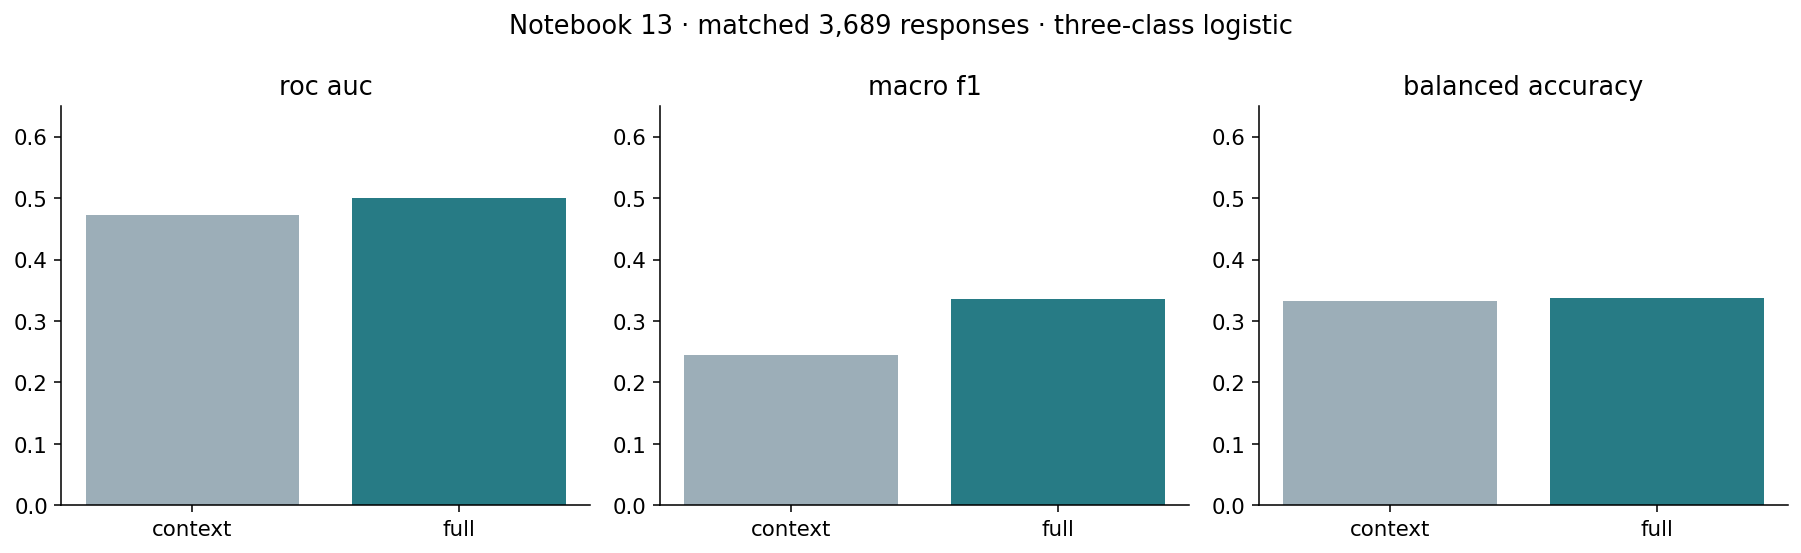

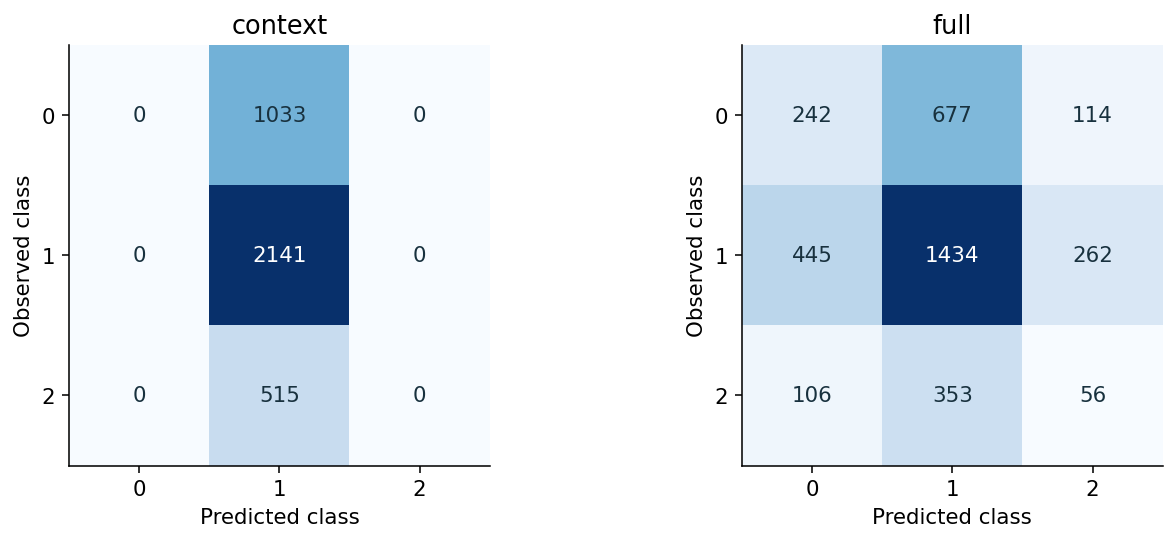

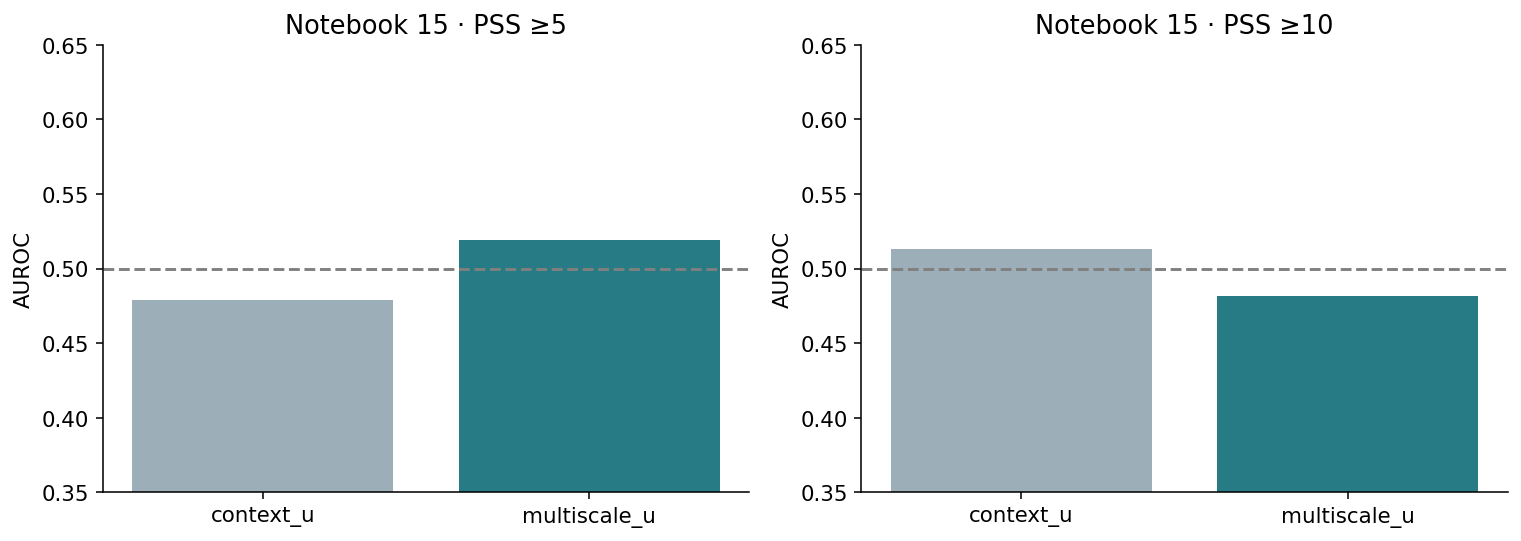

,checkpoint,task,view,label,support,precision,recall,f1
0,13,at_least_10,context,0,3174,0.860396,1.000000,0.924960
1,13,at_least_10,context,1,515,0.000000,0.000000,0.000000
2,13,at_least_10,full,0,3174,0.861674,0.924386,0.891929
3,13,at_least_10,full,1,515,0.154930,0.085437,0.110138
4,13,at_least_5,context,0,1033,0.000000,0.000000,0.000000
5,13,at_least_5,context,1,2656,0.719978,1.000000,0.837195
6,13,at_least_5,full,0,1033,0.302932,0.180058,0.225865
7,13,at_least_5,full,1,2656,0.724553,0.838855,0.777526
8,13,three_class,context,0,1033,0.000000,0.000000,0.000000
9,13,three_class,context,1,2141,0.580374,1.000000,0.734477


In [52]:
classification = table('classification_metrics')
display(classification[['checkpoint','task','view','responses','participants','roc_auc','macro_f1','balanced_accuracy','elevated_precision','elevated_recall']])
figure('classification')
figure('confusion')
figure('binary')
display(table('per_class'))
# Three-class AUROC is macro one-vs-rest. Binary AUROC uses the positive class.


## Matched regression results

,checkpoint,view,family,responses,participants,mae,rmse,r2,spearman
0,14,context,ridge,3689,125,2.238723,2.698385,-0.002402,-0.008570
1,14,full,ridge,3689,125,2.277865,2.774037,-0.059398,0.022943
2,14,context,lasso,3689,125,2.239590,2.698240,-0.002295,-0.014148
3,14,full,lasso,3689,125,2.247417,2.703673,-0.006335,-0.071899
4,14,context,elastic,3689,125,2.239040,2.698020,-0.002132,-0.015072
5,14,full,elastic,3689,125,2.244591,2.700385,-0.003889,-0.095459
6,14,context,huber,3689,125,2.224210,2.712672,-0.013046,-0.011246
7,14,full,huber,3689,125,2.313957,2.872877,-0.136235,0.018947
8,14,context,hgb,3689,125,2.214373,2.726075,-0.023081,-0.002915
9,14,full,hgb,3689,125,2.255455,2.759637,-0.048427,-0.052548


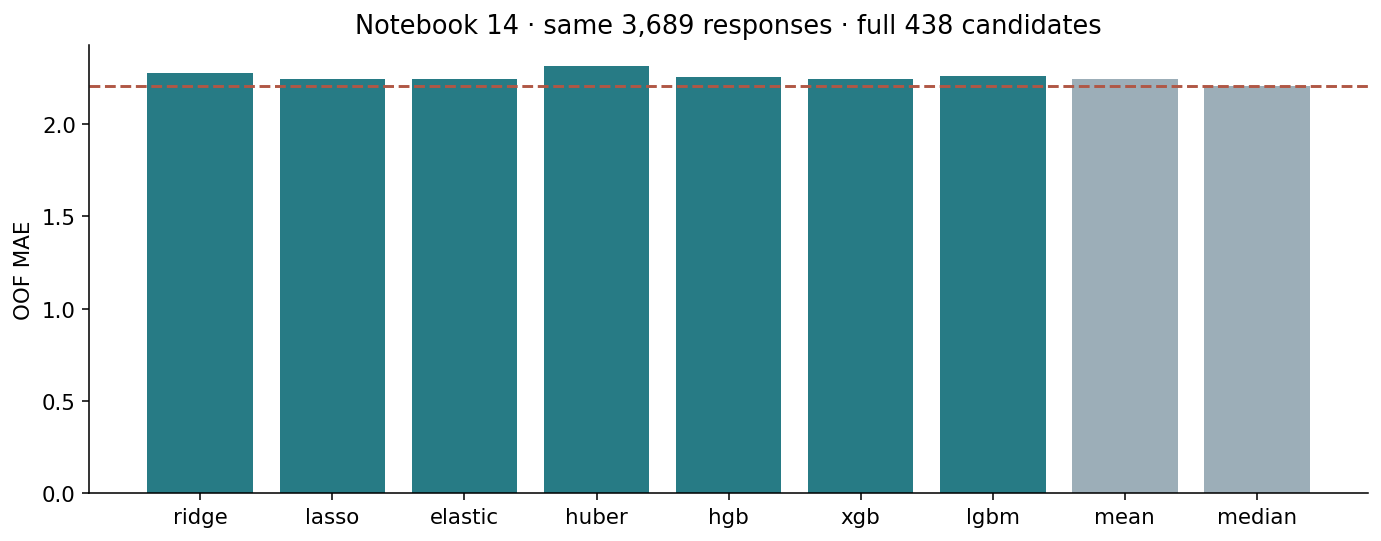

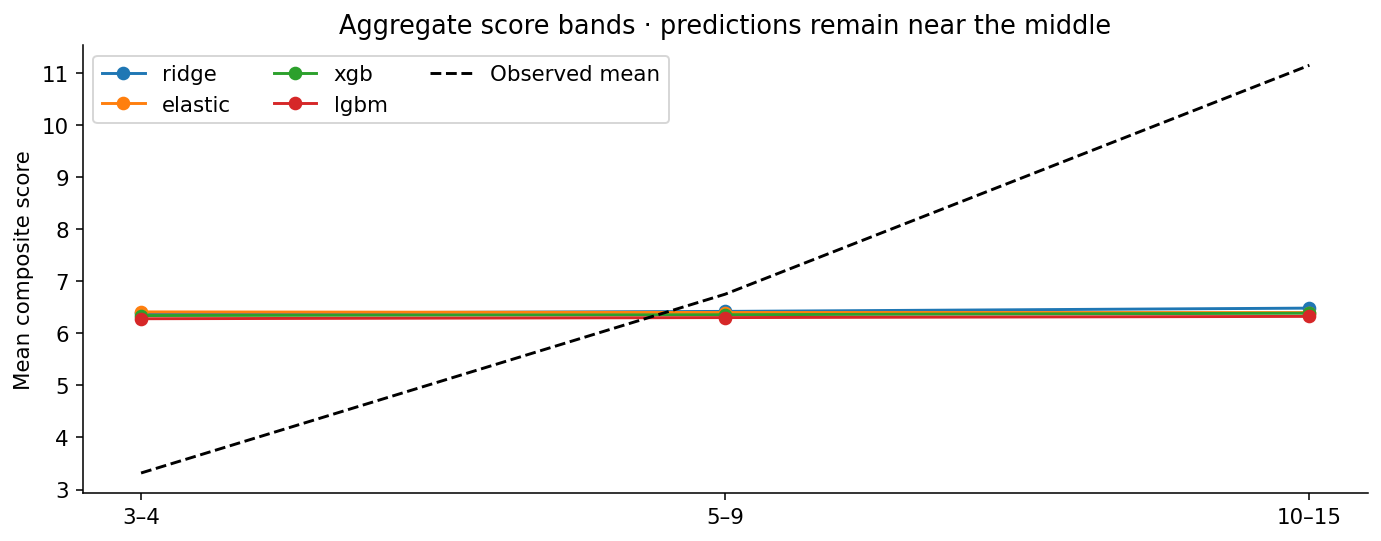

,view,family,score_band,responses,actual_mean,predicted_mean,mae
0,context,elastic,3–4,1033.0,3.317522,6.405821,3.088299
1,context,elastic,5–9,2141.0,6.755255,6.403478,1.227573
2,context,elastic,10–15,515.0,11.155340,6.414809,4.740530
3,context,hgb,3–4,1033.0,3.317522,6.033000,2.715478
4,context,hgb,5–9,2141.0,6.755255,6.022708,1.274192
5,context,hgb,10–15,515.0,11.155340,6.037500,5.117840
6,context,huber,3–4,1033.0,3.317522,6.160970,2.843448
7,context,huber,5–9,2141.0,6.755255,6.155001,1.261228
8,context,huber,10–15,515.0,11.155340,6.169823,4.985517
9,context,lasso,3–4,1033.0,3.317522,6.406425,3.088903


In [53]:
regression = table('regression_metrics')
display(regression[['checkpoint','view','family','responses','participants','mae','rmse','r2','spearman']])
figure('regression')
figure('score_bands')
display(table('regression_score_bands'))
# Within each task, full/context models use identical 3,689 validation responses.
# Repeated exploratory comparisons do not establish a deployable or causal physiological signal.


## Current measurement gates

In [54]:
checkpoint = json.loads((root / 'reports/measurement_alignment/completion.json').read_text())
display(pd.DataFrame({'status':['BLOCKED','BLOCKED'], 'reason':checkpoint['blocked']}))
# Raw clocks, final-test sealing, earlier artifacts and frozen folds remain unchanged.


,status,reason
0,BLOCKED,Prospective recall-aligned prediction: approve...
1,BLOCKED,Previous-answer prediction: exact submitted ve...


## Verification

In [55]:
from garmin_pipeline_review.verify import verify
checks = verify(root)
display(pd.DataFrame([checks]))


,canonical_modules,candidates,supported_candidates,provisional_pulseox,feature_value_checks,classifier_replays,regressor_replays,inner_group_separation_checks,prior_files_preserved,prior_manifests_preserved,raw_reference_metadata_checks,new_model_searches,final_test_evaluated
0,40,678,438,240,6780,50,70,150,1034,3246,7870,0,False
